In [2]:
!pip install pandas numpy matplotlib seaborn sqlalchemy pymysql scikit-learn

In [6]:
import pandas as pd
from sqlalchemy import create_engine
from urllib.parse import quote_plus
from getpass import getpass

host = "18.136.157.135"
port = 3306
database = "project_service_data"

username = input("Enter username: ").strip()
password = getpass("Enter password: ")

connection_string = (
    f"mysql+pymysql://{quote_plus(username)}:"
    f"{quote_plus(password)}@{host}:{port}/{database}"
)

engine = create_engine(
    connection_string,
    pool_size=1,
    max_overflow=0,
    pool_pre_ping=True

)

try:
    with engine.connect() as connection:
        print("✅ Database connected successfully!")

        result = connection.execute(text("SELECT DATABASE();"))
        print("Connected database:", result.fetchone()[0])

except Exception as e:
    print("❌ Connection failed:", e)

finally:
    engine.dispose()

Enter username: 


KeyboardInterrupt: Interrupted by user

In [7]:
query = "SELECT * FROM service_data"

try:
    with engine.connect() as connection:
        df = pd.read_sql(query, connection)

    print("Dataset loaded successfully!")
    print("Dataset Shape:", df.shape)
    display(df.head())

except Exception as e:
    print("Error:", e)

finally:
    engine.dispose()

Dataset loaded successfully!
Dataset Shape: (28482, 7)


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
0,30-05-17,30-05-17,shivXXXXXXXXXX,KA03MFXXXX,BAJAJ AVENGER STREET 220,50000,ENGINE OIL
1,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,ENGINE OIL
2,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,POLISH
3,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,CONSUMABLES
4,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,COOLANT OIL


In [8]:
df

,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
0,30-05-17,30-05-17,shivXXXXXXXXXX,KA03MFXXXX,BAJAJ AVENGER STREET 220,50000,ENGINE OIL
1,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,ENGINE OIL
2,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,POLISH
3,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,CONSUMABLES
4,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,COOLANT OIL
...,...,...,...,...,...,...,...
28477,06-01-19,06-01-19,pravXXXXXXXXXX,KA53EVXXXX,BAJAJ DISCOVER 125,12805,SPROCKET RUBBER
28478,06-01-19,06-01-19,pravXXXXXXXXXX,KA53EVXXXX,BAJAJ DISCOVER 125,12805,CLUTCH CABLE
28479,06-01-19,06-01-19,pravXXXXXXXXXX,KA53EVXXXX,BAJAJ DISCOVER 125,12805,OIL FILTER
28480,06-01-19,06-01-19,pravXXXXXXXXXX,KA53EVXXXX,BAJAJ DISCOVER 125,12805,DISC OIL


In [9]:
# 1. Dataset information
df.info()

# 2. Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 3. Duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# 4. Number of unique values
print("\nUnique Values:")
print(df.nunique())

# 5. Date ranges
print("\nInvoice Date Range:")
print(df['invoice_date'].min(), "to", df['invoice_date'].max())

# 6. Most frequently appearing invoice items
print("\nTop 10 Invoice Items:")
print(df['invoice_line_text'].value_counts().head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28482 entries, 0 to 28481
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   invoice_date           28482 non-null  object
 1   job_card_date          28482 non-null  object
 2   business_partner_name  28482 non-null  object
 3   vehicle_no             28482 non-null  object
 4   vehicle_model          28482 non-null  object
 5   current_km_reading     28482 non-null  object
 6   invoice_line_text      28476 non-null  object
dtypes: object(7)
memory usage: 1.5+ MB

Missing Values:
invoice_date             0
job_card_date            0
business_partner_name    0
vehicle_no               0
vehicle_model            0
current_km_reading       0
invoice_line_text        6
dtype: int64

Duplicate Records:
383

Unique Values:
invoice_date              555
job_card_date             553
business_partner_name    1010
vehicle_no                846
vehicle_model 

In [10]:
# Create a working copy
df_work = df.copy()

# Convert date columns
df_work['invoice_date'] = pd.to_datetime(
    df_work['invoice_date'],
    format='%d-%m-%y',
    errors='coerce'
)

df_work['job_card_date'] = pd.to_datetime(
    df_work['job_card_date'],
    format='%d-%m-%y',
    errors='coerce'
)

# Convert kilometre reading into numeric
df_work['current_km_reading'] = pd.to_numeric(
    df_work['current_km_reading'],
    errors='coerce'
)

# Check data types
print("Updated Data Types:")
print(df_work.dtypes)

# Check actual date range
print("\nInvoice Date Range:")
print(df_work['invoice_date'].min())
print(df_work['invoice_date'].max())

# Check conversion errors
print("\nMissing Values After Conversion:")
print(df_work.isnull().sum())

Updated Data Types:
invoice_date             datetime64[ns]
job_card_date            datetime64[ns]
business_partner_name            object
vehicle_no                       object
vehicle_model                    object
current_km_reading                int64
invoice_line_text                object
dtype: object

Invoice Date Range:
2017-05-30 00:00:00
2019-01-06 00:00:00

Missing Values After Conversion:
invoice_date             0
job_card_date            0
business_partner_name    0
vehicle_no               0
vehicle_model            0
current_km_reading       0
invoice_line_text        6
dtype: int64


In [11]:

# 1. Investigate duplicate records
duplicates = df_work[df_work.duplicated(keep=False)]

print("Total duplicate rows:", len(duplicates))
display(duplicates.head(10))


# 2. Investigate missing invoice descriptions
missing_items = df_work[df_work['invoice_line_text'].isnull()]

print("Records with missing invoice descriptions:")
display(missing_items)


# 3. Records by year
print("\nRecords by year:")
print(df_work['invoice_date'].dt.year.value_counts().sort_index())


# 4. Records by month
print("\nRecords by month:")
print(df_work['invoice_date'].dt.to_period('M').value_counts().sort_index())


Total duplicate rows: 720


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
24,2017-06-03,2017-05-31,MAYAXXXXXXXXXX,KA05JGXXXX,BAJAJ PULSAR 220,25000,DISC PAD
40,2017-06-03,2017-05-31,MAYAXXXXXXXXXX,KA05JGXXXX,BAJAJ PULSAR 220,25000,DISC PAD
41,2017-06-05,2017-06-01,srivXXXXXXXXXX,KA02EWXXXX,BAJAJ PULSAR 150,41458,BRAKE ADJUSTMENT
43,2017-06-05,2017-06-01,srivXXXXXXXXXX,KA02EWXXXX,BAJAJ PULSAR 150,41458,BRAKE ADJUSTMENT
577,2017-06-13,2017-06-13,subhXXXXXXXXXX,KA53J9XXXX,BAJAJ AVENGER STREET 220,14484,SILENCER
579,2017-06-13,2017-06-13,subhXXXXXXXXXX,KA53J9XXXX,BAJAJ AVENGER STREET 220,14484,SILENCER
632,2017-06-15,2017-06-14,naveXXXXXXXXXX,KA53W3XXXX,BAJAJ DISCOVER 150,25677,None
635,2017-06-15,2017-06-14,naveXXXXXXXXXX,KA53W3XXXX,BAJAJ DISCOVER 150,25677,None
884,2017-06-20,2017-06-20,JIBUXXXXXXXXXX,KA53ENXXXX,BAJAJ CT 100,10207,BRAKE SHOE
886,2017-06-20,2017-06-20,JIBUXXXXXXXXXX,KA53ENXXXX,BAJAJ CT 100,10207,BRAKE SHOE


Records with missing invoice descriptions:


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
632,2017-06-15,2017-06-14,naveXXXXXXXXXX,KA53W3XXXX,BAJAJ DISCOVER 150,25677,None
635,2017-06-15,2017-06-14,naveXXXXXXXXXX,KA53W3XXXX,BAJAJ DISCOVER 150,25677,None
661,2017-06-15,2017-06-14,kailXXXXXXXXXX,KA01HNXXXX,BAJAJ PULSAR 150,8679,None
769,2017-06-16,2017-06-16,hariXXXXXXXXXX,KA53ESXXXX,BAJAJ AVENGER STREET,457,None
2579,2017-08-01,2017-08-01,hariXXXXXXXXXX,KA53EQXXXX,BAJAJ PULSAR 150,9677,None
2613,2017-08-03,2017-08-03,diliXXXXXXXXXX,KA53S3XXXX,BAJAJ V,251447,None



Records by year:
invoice_date
2017     8547
2018    19584
2019      351
Name: count, dtype: int64

Records by month:
invoice_date
2017-05      11
2017-06    1346
2017-07    1178
2017-08     973
2017-09    1264
2017-10    1054
2017-11    1376
2017-12    1345
2018-01     998
2018-02    1341
2018-03    1488
2018-04    1406
2018-05    1448
2018-06    1601
2018-07    1550
2018-08    1589
2018-09    2000
2018-10    2123
2018-11    1780
2018-12    2260
2019-01     351
Freq: M, Name: count, dtype: int64


In [12]:

# Identify groups of completely identical records

duplicate_groups = (
    df_work.groupby(list(df_work.columns), dropna=False)
    .size()
    .reset_index(name='occurrences')
)

duplicate_groups = duplicate_groups[
    duplicate_groups['occurrences'] > 1
]

print("Number of duplicate groups:", len(duplicate_groups))

print(
    "Total rows belonging to duplicate groups:",
    duplicate_groups['occurrences'].sum()
)

print(
    "Extra duplicate copies:",
    (duplicate_groups['occurrences'] - 1).sum()
)

print(
    "Maximum occurrences of one identical record:",
    duplicate_groups['occurrences'].max()
)

print("\nDuplicate group frequency:")
print(duplicate_groups['occurrences'].value_counts().sort_index())

display(duplicate_groups.head(10))


Number of duplicate groups: 337
Total rows belonging to duplicate groups: 720
Extra duplicate copies: 383
Maximum occurrences of one identical record: 13

Duplicate group frequency:
occurrences
2     316
3      11
4       3
5       6
13      1
Name: count, dtype: int64


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text,occurrences
80,2017-06-03,2017-05-31,MAYAXXXXXXXXXX,KA05JGXXXX,BAJAJ PULSAR 220,25000,DISC PAD,2
151,2017-06-05,2017-06-01,srivXXXXXXXXXX,KA02EWXXXX,BAJAJ PULSAR 150,41458,BRAKE ADJUSTMENT,2
566,2017-06-13,2017-06-13,subhXXXXXXXXXX,KA53J9XXXX,BAJAJ AVENGER STREET 220,14484,SILENCER,2
702,2017-06-15,2017-06-14,naveXXXXXXXXXX,KA53W3XXXX,BAJAJ DISCOVER 150,25677,NaN,2
880,2017-06-20,2017-06-20,JIBUXXXXXXXXXX,KA53ENXXXX,BAJAJ CT 100,10207,BRAKE SHOE,2
1288,2017-06-29,2017-06-28,DEEPXXXXXXXXXX,TN54E9XXXX,BAJAJ PULSAR NS 200,24665,DISC PAD,2
1502,2017-07-04,2017-07-04,sumaXXXXXXXXXX,KA01HBXXXX,BAJAJ PULSAR NS 200,18305,DISC PAD,2
1569,2017-07-07,2017-07-07,PRASXXXXXXXXXX,KA53EQXXXX,BAJAJ PULSAR 220,13224,DISC PAD,2
1772,2017-07-11,2017-07-11,kiraXXXXXXXXXX,KA03JDXXXX,BAJAJ PULSAR 150,20818,BRAKE SHOE,2
2121,2017-07-20,2017-07-20,niveXXXXXXXXXX,KA53EPXXXX,BAJAJ PULSAR AS 200,7526,DISC PAD,2


In [13]:

# Find records that occur more than 5 times

high_frequency_duplicates = duplicate_groups[
    duplicate_groups['occurrences'] > 5
]

print("Records appearing more than 5 times:")

display(high_frequency_duplicates)


Records appearing more than 5 times:


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text,occurrences
10707,2018-02-27,2018-02-27,PRAVXXXXXXXXXX,KA04JBXXXX,BAJAJ PULSAR 150,24447,,13


In [14]:

# Count the most frequently repeated invoice descriptions

print(
    duplicate_groups
    .sort_values('occurrences', ascending=False)
    .head(10)
)


      invoice_date job_card_date business_partner_name  vehicle_no  \
10707   2018-02-27    2018-02-27        PRAVXXXXXXXXXX  KA04JBXXXX   
17153   2018-07-10    2018-07-10        santXXXXXXXXXX  KA53ETXXXX   
17154   2018-07-10    2018-07-10        santXXXXXXXXXX  KA53ETXXXX   
17151   2018-07-10    2018-07-10        santXXXXXXXXXX  KA53ETXXXX   
17150   2018-07-10    2018-07-10        santXXXXXXXXXX  KA53ETXXXX   
17152   2018-07-10    2018-07-10        santXXXXXXXXXX  KA53ETXXXX   
17149   2018-07-10    2018-07-10        santXXXXXXXXXX  KA53ETXXXX   
10713   2018-02-27    2018-02-27        RAMEXXXXXXXXXX  KA53Y5XXXX   
10790   2018-03-01    2018-03-01        DARSXXXXXXXXXX  KA04JAXXXX   
25281   2018-11-27    2018-11-27        vinaXXXXXXXXXX  KA53EXXXXX   

          vehicle_model  current_km_reading  invoice_line_text  occurrences  
10707  BAJAJ PULSAR 150               24447                              13  
17153  BAJAJ PULSAR 150                5620         ENGINE OIL           

In [15]:

# Investigate missing invoice descriptions

missing_records = df_work[
    df_work['invoice_line_text'].isna()
]

missing_summary = (
    missing_records
    .groupby(
        [
            'invoice_date',
            'job_card_date',
            'business_partner_name',
            'vehicle_no',
            'vehicle_model',
            'current_km_reading'
        ],
        dropna=False
    )
    .size()
    .reset_index(name='occurrences')
)

print("Total missing-description rows:", len(missing_records))

print(
    "Unique missing-description record groups:",
    len(missing_summary)
)

display(missing_summary)


Total missing-description rows: 6
Unique missing-description record groups: 5


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,occurrences
0,2017-06-15,2017-06-14,kailXXXXXXXXXX,KA01HNXXXX,BAJAJ PULSAR 150,8679,1
1,2017-06-15,2017-06-14,naveXXXXXXXXXX,KA53W3XXXX,BAJAJ DISCOVER 150,25677,2
2,2017-06-16,2017-06-16,hariXXXXXXXXXX,KA53ESXXXX,BAJAJ AVENGER STREET,457,1
3,2017-08-01,2017-08-01,hariXXXXXXXXXX,KA53EQXXXX,BAJAJ PULSAR 150,9677,1
4,2017-08-03,2017-08-03,diliXXXXXXXXXX,KA53S3XXXX,BAJAJ V,251447,1


In [16]:

# Count unique invoice item descriptions

print(
    "Total unique invoice descriptions:",
    df_work['invoice_line_text'].nunique()
)

print("\nMost frequently appearing descriptions:")

item_counts = (
    df_work['invoice_line_text']
    .value_counts(dropna=False)
)

display(item_counts.head(30))


Total unique invoice descriptions: 503

Most frequently appearing descriptions:


,count
invoice_line_text,
ENGINE OIL,3802
CHAIN LUBRICATION,3441
GENERAL SERVICE,2142
AIR FILTER,1715
3M OIL,1628
CONSUMABLES,1595
POLISH,1245
DISC OIL,991
BRAKE SHOE,965


In [17]:

# Display the 30 least frequent invoice descriptions

print("Least frequently appearing descriptions:")

display(item_counts.tail(30))

# Check descriptions containing common service-related words

service_keywords = [
    'SERVICE',
    'LABOUR',
    'CHECKUP',
    'OVERHAUL',
    'REPAIR',
    'WASH'
]

print("\nDescriptions containing service-related keywords:")

service_descriptions = [
    item for item in item_counts.index
    if isinstance(item, str)
    and any(keyword in item.upper() for keyword in service_keywords)
]

for item in service_descriptions:
    print(item, ":", item_counts[item])


Least frequently appearing descriptions:


,count
invoice_line_text,
CARBURETOR PLATE,1
WASHING AND POLISH,1
SIDE SWITCH MAGNET,1
GEAR LEVER BUSH,1
GEAR LEVER OIL SEAL,1
MASK,1
tyre,1
BRAKE PEDAL RUBBER,1
HEAD BORE GASKET,1



Descriptions containing service-related keywords:
GENERAL SERVICE : 2142
AIR FILTER CHECKUP : 467
CHAIN OVERHAUL : 284
LABOUR : 131
WASHING : 52
ENGINE LABOUR : 49
WIRING CHECKUP : 20
SERVICE : 12
DRUM BOLT WASHER : 5
WIRING LABOUR : 4
COIL LABOUR : 3
FORK LABOUR : 2
HEAD CAP LABOUR : 1
SERVICE AND ONE WAY CLUTCH BUSH KIT : 1
VISIOR WITH LABOUR : 1
WASHING AND LABOUR : 1
FITTING LABOUR : 1
WASHING AND POLISH : 1
GEAR AND WASHER : 1
LIGHT FITTING LABOUR : 1


In [18]:

# Analyse invoice description frequency

total_records = len(df_work)

non_missing_records = df_work['invoice_line_text'].notna().sum()

top_10_records = item_counts.dropna().head(10).sum()

top_20_records = item_counts.dropna().head(20).sum()

print("Total dataset records:", total_records)

print("Records with invoice descriptions:", non_missing_records)

print("\nTop 10 descriptions:")
print("Records:", top_10_records)
print("Percentage:", round(top_10_records / total_records * 100, 2), "%")

print("\nTop 20 descriptions:")
print("Records:", top_20_records)
print("Percentage:", round(top_20_records / total_records * 100, 2), "%")

print("\nUnique descriptions:", df_work['invoice_line_text'].nunique())


Total dataset records: 28482
Records with invoice descriptions: 28476

Top 10 descriptions:
Records: 18345
Percentage: 64.41 %

Top 20 descriptions:
Records: 22145
Percentage: 77.75 %

Unique descriptions: 503


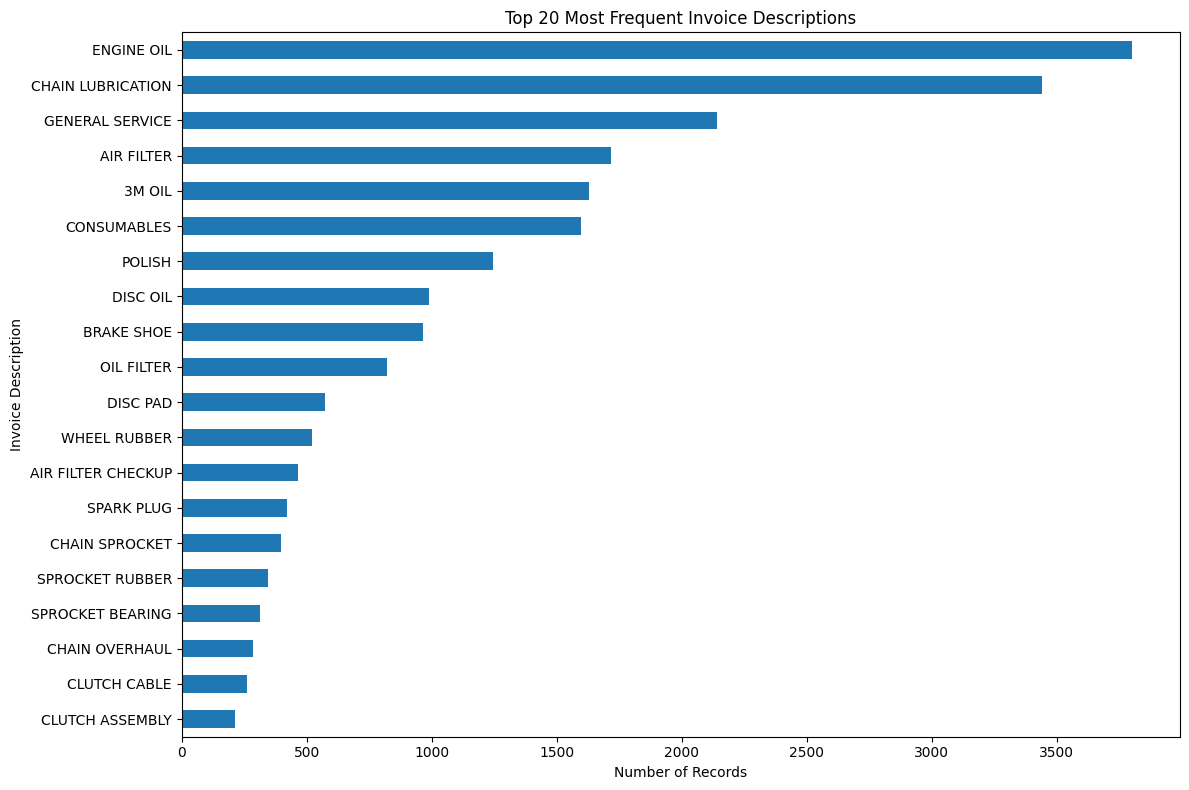

In [19]:

import matplotlib.pyplot as plt

# Select top 20 invoice descriptions
top_20_items = item_counts.dropna().head(20)

# Create horizontal bar chart
plt.figure(figsize=(12, 8))

top_20_items.sort_values().plot(
    kind='barh'
)

plt.title('Top 20 Most Frequent Invoice Descriptions')
plt.xlabel('Number of Records')
plt.ylabel('Invoice Description')

plt.tight_layout()
plt.show()


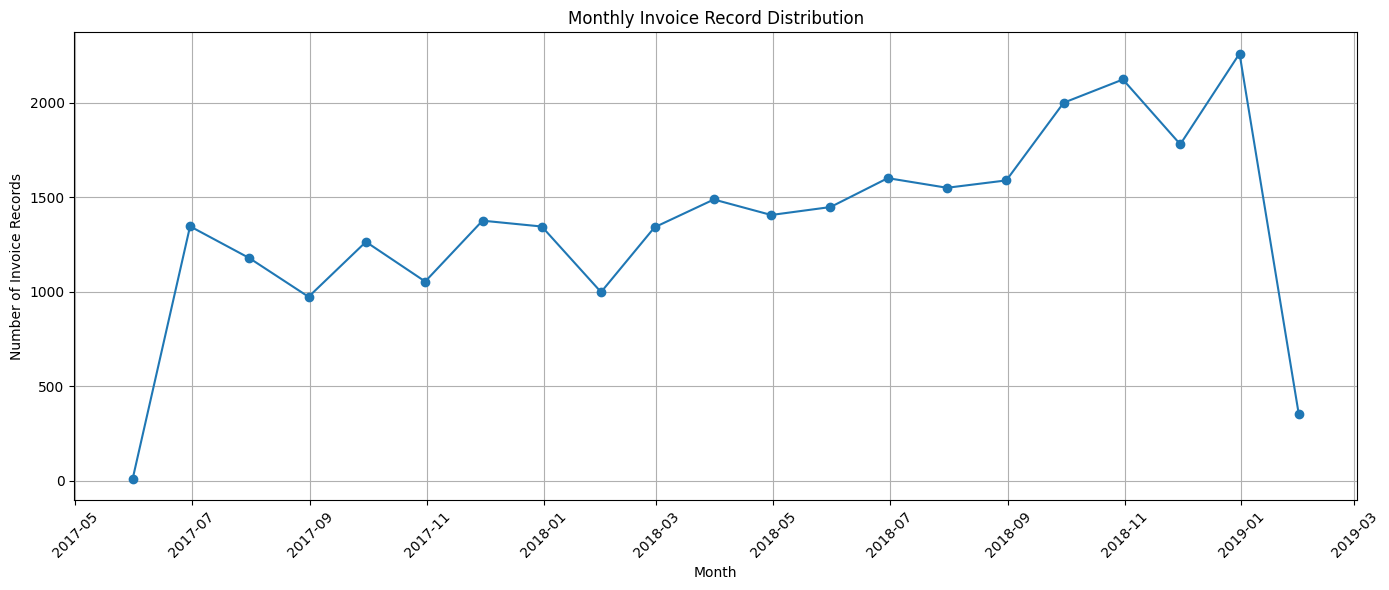


Monthly record counts:


,0
invoice_date,
2017-05-31,11
2017-06-30,1346
2017-07-31,1178
2017-08-31,973
2017-09-30,1264
2017-10-31,1054
2017-11-30,1376
2017-12-31,1345
2018-01-31,998


In [20]:

# Monthly invoice record distribution

monthly_records = (
    df_work
    .set_index('invoice_date')
    .resample('ME')
    .size()
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_records.index,
    monthly_records.values,
    marker='o'
)

plt.title('Monthly Invoice Record Distribution')
plt.xlabel('Month')
plt.ylabel('Number of Invoice Records')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

print("\nMonthly record counts:")
display(monthly_records)


In [21]:

# Investigate how many calendar days contain records each month

monthly_coverage = (
    df_work
    .groupby(df_work['invoice_date'].dt.to_period('M'))
    .agg(
        first_invoice_date=('invoice_date', 'min'),
        last_invoice_date=('invoice_date', 'max'),
        total_records=('invoice_date', 'size'),
        active_days=('invoice_date', 'nunique')
    )
)

print("Monthly Date Coverage:")
display(monthly_coverage)


Monthly Date Coverage:


,first_invoice_date,last_invoice_date,total_records,active_days
invoice_date,,,,
2017-05,2017-05-30,2017-05-31,11,2
2017-06,2017-06-01,2017-06-30,1346,30
2017-07,2017-07-01,2017-07-31,1178,27
2017-08,2017-08-01,2017-08-31,973,28
2017-09,2017-09-01,2017-09-30,1264,29
2017-10,2017-10-01,2017-10-31,1054,22
2017-11,2017-11-01,2017-11-30,1376,29
2017-12,2017-12-01,2017-12-31,1345,31
2018-01,2018-01-02,2018-01-31,998,29


Invoice records by weekday:


,count
invoice_date,
Monday,4141
Tuesday,4808
Wednesday,4038
Thursday,3955
Friday,3854
Saturday,5612
Sunday,2074


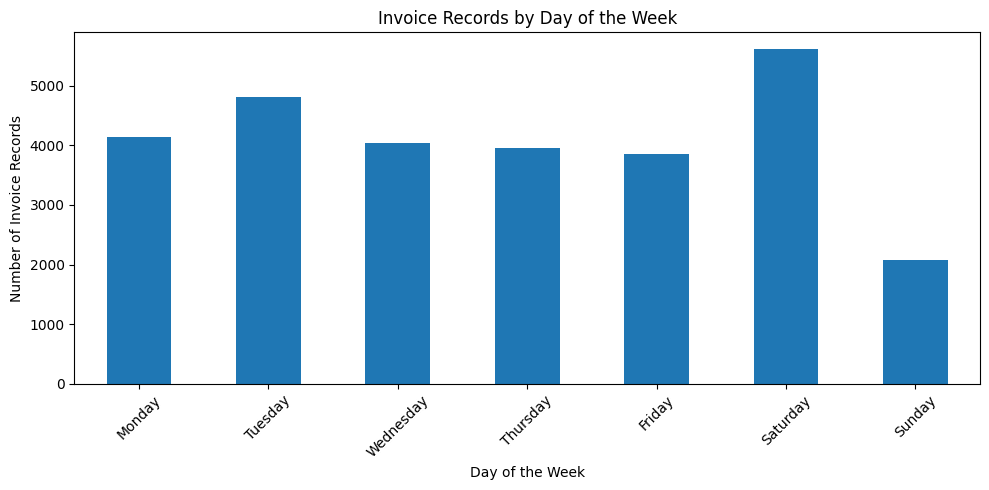

In [22]:

# Analyse invoice activity by day of the week

weekday_records = (
    df_work['invoice_date']
    .dt.day_name()
    .value_counts()
    .reindex([
        'Monday',
        'Tuesday',
        'Wednesday',
        'Thursday',
        'Friday',
        'Saturday',
        'Sunday'
    ])
)

print("Invoice records by weekday:")
display(weekday_records)

# Visualize weekday distribution

plt.figure(figsize=(10, 5))

weekday_records.plot(kind='bar')

plt.title('Invoice Records by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Invoice Records')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [23]:

# Count invoice records for each individual date

daily_records = (
    df_work
    .groupby('invoice_date')
    .size()
)

# Calculate weekday-level statistics

weekday_summary = (
    daily_records
    .groupby(daily_records.index.day_name())
    .agg(
        active_days='count',
        average_records_per_day='mean',
        median_records_per_day='median',
        maximum_records_per_day='max'
    )
)

# Arrange weekdays in calendar order

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_summary = weekday_summary.reindex(weekday_order)

print("Average daily invoice activity by weekday:")
display(weekday_summary.round(2))


Average daily invoice activity by weekday:


,active_days,average_records_per_day,median_records_per_day,maximum_records_per_day
invoice_date,,,,
Monday,81,51.12,48.0,136
Tuesday,83,57.93,55.0,167
Wednesday,82,49.24,41.0,133
Thursday,78,50.71,51.0,111
Friday,78,49.41,48.0,148
Saturday,83,67.61,66.0,179
Sunday,70,29.63,27.0,64


ENGINE OIL invoice records by weekday:


,count
invoice_date,
Monday,552
Tuesday,623
Wednesday,535
Thursday,526
Friday,500
Saturday,755
Sunday,311


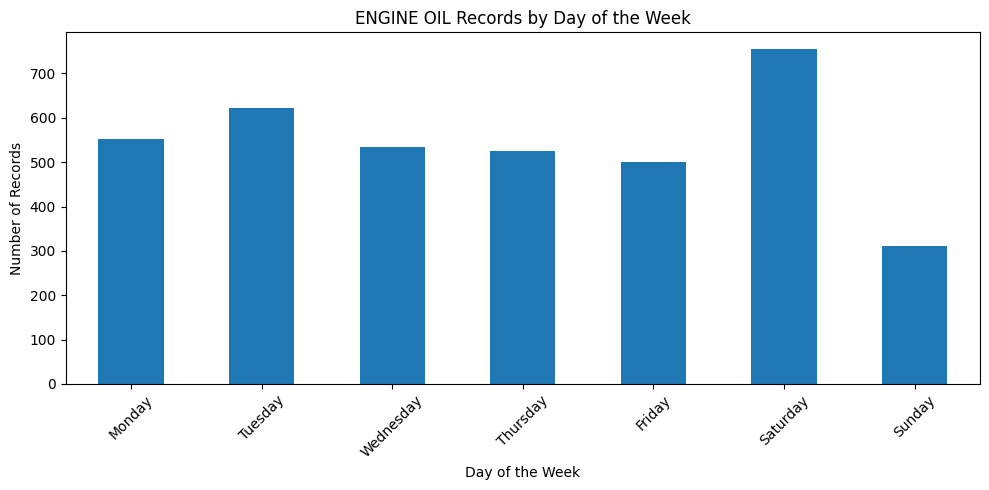

In [24]:

# Filter ENGINE OIL records
engine_oil = df_work[
    df_work['invoice_line_text'].str.strip().str.upper() == 'ENGINE OIL'
]

# Count ENGINE OIL records by weekday
engine_oil_weekday = (
    engine_oil['invoice_date']
    .dt.day_name()
    .value_counts()
    .reindex([
        'Monday', 'Tuesday', 'Wednesday',
        'Thursday', 'Friday', 'Saturday', 'Sunday'
    ], fill_value=0)
)

print("ENGINE OIL invoice records by weekday:")
display(engine_oil_weekday)

# Visualize the result
plt.figure(figsize=(10, 5))

engine_oil_weekday.plot(kind='bar')

plt.title('ENGINE OIL Records by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Records')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [25]:

# Count ENGINE OIL records for each calendar date
engine_oil_daily = (
    engine_oil.groupby('invoice_date')
    .size()
)

# Summarize by weekday
engine_oil_weekday_summary = (
    engine_oil_daily
    .groupby(engine_oil_daily.index.day_name())
    .agg(
        active_days='count',
        average_records_per_day='mean',
        median_records_per_day='median'
    )
)

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

engine_oil_weekday_summary = (
    engine_oil_weekday_summary.reindex(weekday_order)
)

print("ENGINE OIL average daily activity:")
display(engine_oil_weekday_summary.round(2))


ENGINE OIL average daily activity:


,active_days,average_records_per_day,median_records_per_day
invoice_date,,,
Monday,81,6.81,6.0
Tuesday,83,7.51,7.0
Wednesday,82,6.52,6.0
Thursday,78,6.74,7.0
Friday,78,6.41,6.5
Saturday,83,9.10,9.0
Sunday,68,4.57,5.0


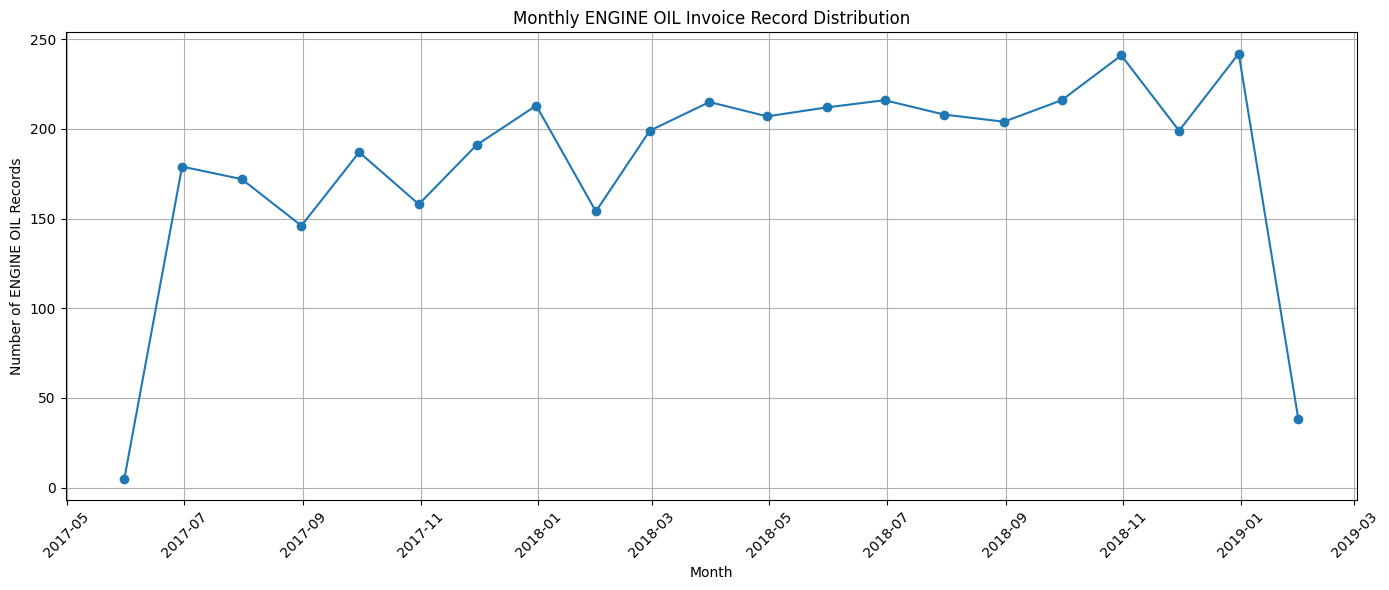

Monthly ENGINE OIL records:


,0
invoice_date,
2017-05-31,5
2017-06-30,179
2017-07-31,172
2017-08-31,146
2017-09-30,187
2017-10-31,158
2017-11-30,191
2017-12-31,213
2018-01-31,154


In [26]:

# Monthly ENGINE OIL invoice records

engine_oil_monthly = (
    engine_oil
    .set_index('invoice_date')
    .resample('ME')
    .size()
)

plt.figure(figsize=(14, 6))

plt.plot(
    engine_oil_monthly.index,
    engine_oil_monthly.values,
    marker='o'
)

plt.title('Monthly ENGINE OIL Invoice Record Distribution')
plt.xlabel('Month')
plt.ylabel('Number of ENGINE OIL Records')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

print("Monthly ENGINE OIL records:")
display(engine_oil_monthly)


In [27]:

# Monthly total invoice records
total_monthly = (
    df_work
    .set_index('invoice_date')
    .resample('ME')
    .size()
)

# Monthly ENGINE OIL records
engine_oil_monthly = (
    engine_oil
    .set_index('invoice_date')
    .resample('ME')
    .size()
)

# Combine both monthly series
monthly_comparison = pd.DataFrame({
    'Total_Invoice_Records': total_monthly,
    'Engine_Oil_Records': engine_oil_monthly
})

# Calculate ENGINE OIL share
monthly_comparison['Engine_Oil_Percentage'] = (
    monthly_comparison['Engine_Oil_Records']
    / monthly_comparison['Total_Invoice_Records']
) * 100

print("Monthly comparison:")
display(monthly_comparison.round(2))


Monthly comparison:


,Total_Invoice_Records,Engine_Oil_Records,Engine_Oil_Percentage
invoice_date,,,
2017-05-31,11,5,45.45
2017-06-30,1346,179,13.30
2017-07-31,1178,172,14.60
2017-08-31,973,146,15.01
2017-09-30,1264,187,14.79
2017-10-31,1054,158,14.99
2017-11-30,1376,191,13.88
2017-12-31,1345,213,15.84
2018-01-31,998,154,15.43


Total AIR FILTER records: 1715

Monthly item comparison:


,ENGINE_OIL,AIR_FILTER
invoice_date,,
2017-05-31,5,NaN
2017-06-30,179,5.0
2017-07-31,172,34.0
2017-08-31,146,52.0
2017-09-30,187,77.0
2017-10-31,158,70.0
2017-11-30,191,89.0
2017-12-31,213,112.0
2018-01-31,154,77.0


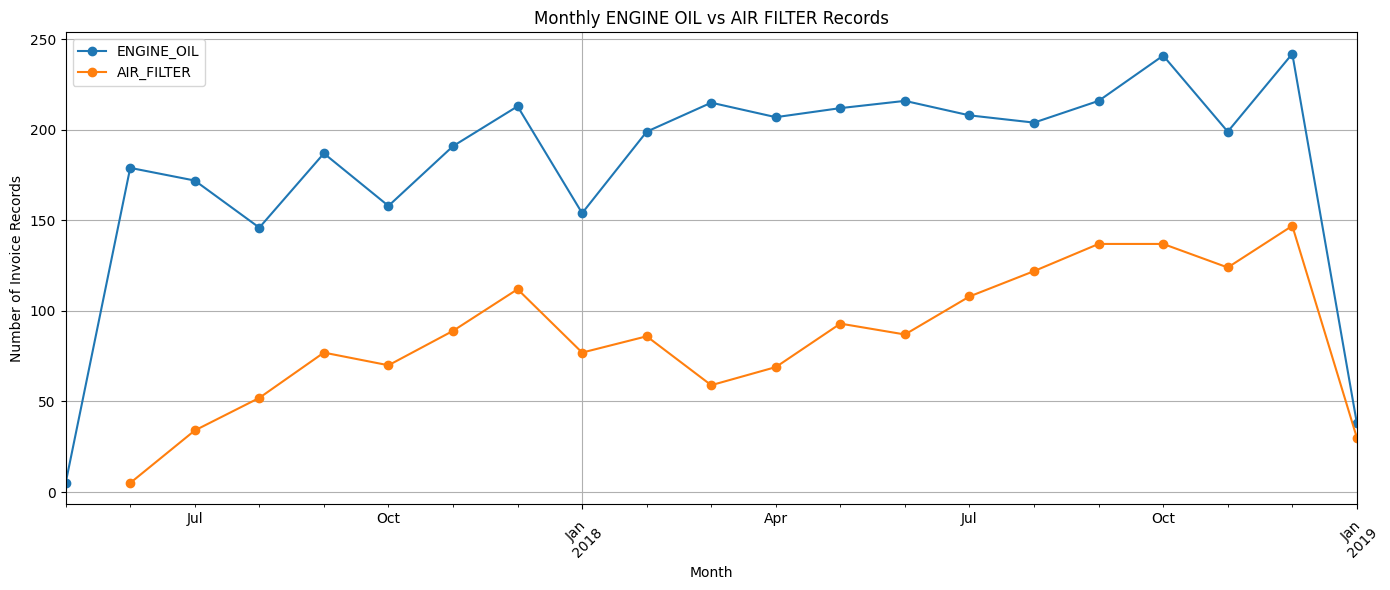

In [28]:

# Filter AIR FILTER records
air_filter = df_work[
    df_work['invoice_line_text'].str.strip().str.upper() == 'AIR FILTER'
]

print("Total AIR FILTER records:", len(air_filter))

# Monthly AIR FILTER records
air_filter_monthly = (
    air_filter
    .set_index('invoice_date')
    .resample('ME')
    .size()
)

# Compare monthly ENGINE OIL and AIR FILTER records
item_monthly_comparison = pd.DataFrame({
    'ENGINE_OIL': engine_oil_monthly,
    'AIR_FILTER': air_filter_monthly
})

print("\nMonthly item comparison:")
display(item_monthly_comparison)

# Visualize both items
item_monthly_comparison.plot(
    figsize=(14, 6),
    marker='o'
)

plt.title('Monthly ENGINE OIL vs AIR FILTER Records')
plt.xlabel('Month')
plt.ylabel('Number of Invoice Records')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


Monthly item percentage comparison:


,ENGINE_OIL_Percentage,AIR_FILTER_Percentage
invoice_date,,
2017-05-31,45.45,NaN
2017-06-30,13.30,0.37
2017-07-31,14.60,2.89
2017-08-31,15.01,5.34
2017-09-30,14.79,6.09
2017-10-31,14.99,6.64
2017-11-30,13.88,6.47
2017-12-31,15.84,8.33
2018-01-31,15.43,7.72


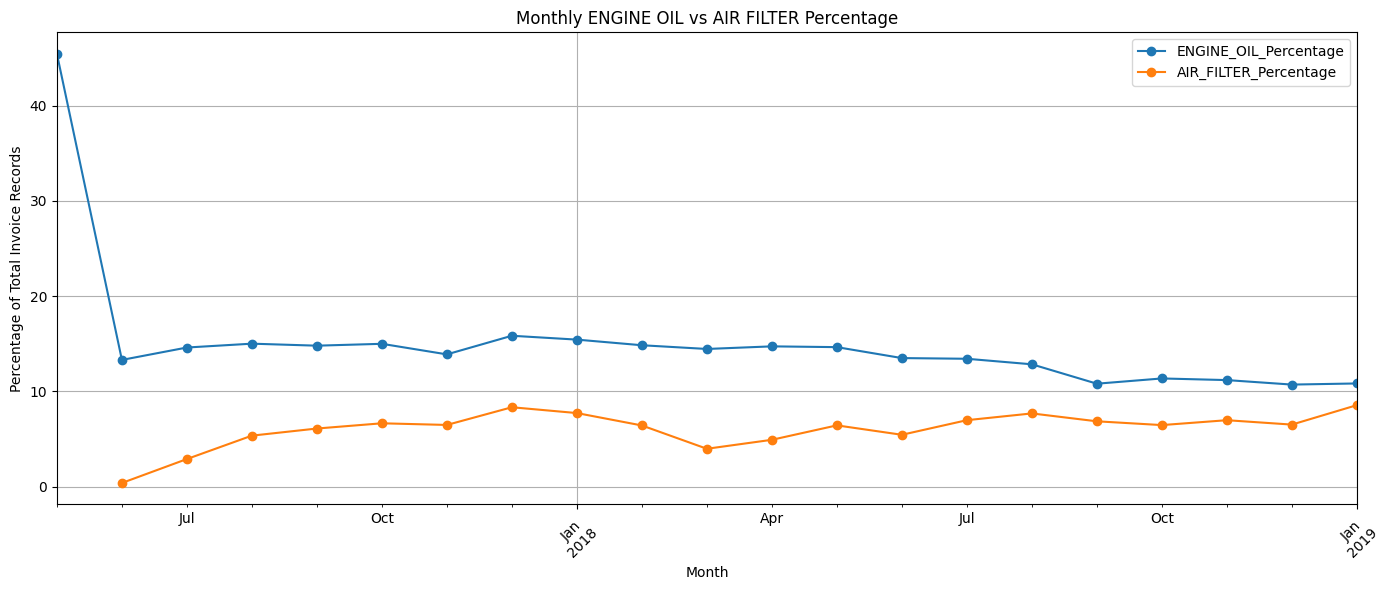

In [29]:

# Calculate monthly AIR FILTER percentage
air_filter_percentage = (
    air_filter_monthly / total_monthly
) * 100

# Create comparison
item_share_comparison = pd.DataFrame({
    'ENGINE_OIL_Percentage':
        (engine_oil_monthly / total_monthly) * 100,

    'AIR_FILTER_Percentage':
        air_filter_percentage
})

print("Monthly item percentage comparison:")
display(item_share_comparison.round(2))

# Visualize percentage comparison
item_share_comparison.plot(
    figsize=(14, 6),
    marker='o'
)

plt.title('Monthly ENGINE OIL vs AIR FILTER Percentage')
plt.xlabel('Month')
plt.ylabel('Percentage of Total Invoice Records')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


Total unique vehicle models: 28

Top 20 vehicle models:


,count
vehicle_model,
BAJAJ PULSAR 150,8633
BAJAJ AVENGER STREET 220,4212
BAJAJ PULSAR 220,2655
BAJAJ PULSAR 180,2252
BAJAJ PULSAR NS 200,2204
BAJAJ CT 100,1432
BAJAJ DISCOVER 125,1346
BAJAJ AVENGER STREET,1112
BAJAJ PLATINA,844


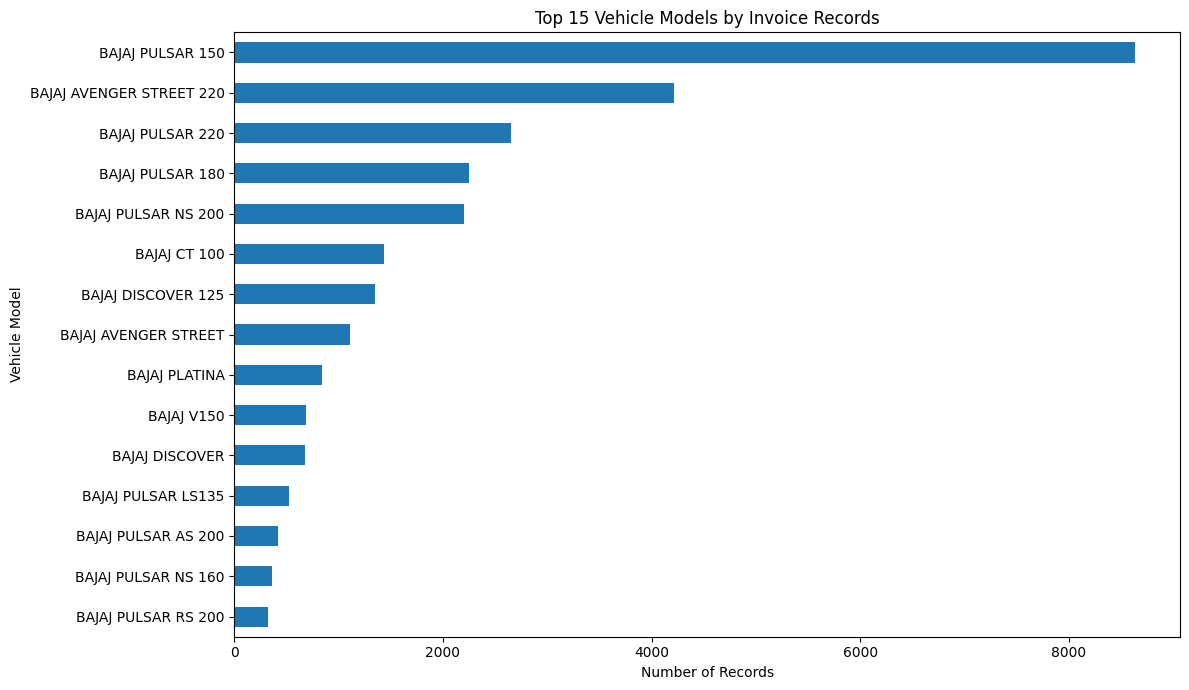

In [30]:

# Count records by vehicle model

vehicle_model_counts = (
    df_work['vehicle_model']
    .value_counts(dropna=False)
)

print("Total unique vehicle models:",
      df_work['vehicle_model'].nunique())

print("\nTop 20 vehicle models:")
display(vehicle_model_counts.head(20))

# Visualize top 15 vehicle models

plt.figure(figsize=(12, 7))

vehicle_model_counts.head(15).sort_values().plot(
    kind='barh'
)

plt.title('Top 15 Vehicle Models by Invoice Records')
plt.xlabel('Number of Records')
plt.ylabel('Vehicle Model')

plt.tight_layout()
plt.show()


In [31]:

# ENGINE OIL records by vehicle model

engine_oil_by_vehicle = (
    engine_oil['vehicle_model']
    .value_counts()
    .head(10)
)

print("Top 10 vehicle models for ENGINE OIL:")
display(engine_oil_by_vehicle)


# AIR FILTER records by vehicle model

air_filter_by_vehicle = (
    air_filter['vehicle_model']
    .value_counts()
    .head(10)
)

print("\nTop 10 vehicle models for AIR FILTER:")
display(air_filter_by_vehicle)


Top 10 vehicle models for ENGINE OIL:


,count
vehicle_model,
BAJAJ PULSAR 150,1066
BAJAJ AVENGER STREET 220,591
BAJAJ PULSAR 220,338
BAJAJ PULSAR 180,303
BAJAJ PULSAR NS 200,297
BAJAJ CT 100,243
BAJAJ AVENGER STREET,171
BAJAJ DISCOVER 125,168
BAJAJ PLATINA,129



Top 10 vehicle models for AIR FILTER:


,count
vehicle_model,
BAJAJ PULSAR 150,554
BAJAJ AVENGER STREET 220,301
BAJAJ PULSAR 220,182
BAJAJ PULSAR 180,169
BAJAJ AVENGER STREET,87
BAJAJ PULSAR NS 200,71
BAJAJ CT 100,66
BAJAJ DISCOVER 125,60
BAJAJ DISCOVER,44


In [32]:

# Total invoice records by vehicle model

vehicle_item_analysis = (
    df_work.groupby('vehicle_model')
    .agg(
        Total_Records=('invoice_line_text', 'size')
    )
)

# ENGINE OIL records by vehicle model
engine_counts = (
    engine_oil['vehicle_model']
    .value_counts()
)

# AIR FILTER records by vehicle model
air_counts = (
    air_filter['vehicle_model']
    .value_counts()
)

# Add item counts
vehicle_item_analysis['ENGINE_OIL_Records'] = (
    engine_counts
)

vehicle_item_analysis['AIR_FILTER_Records'] = (
    air_counts
)

# Fill missing item counts with zero
vehicle_item_analysis[
    ['ENGINE_OIL_Records', 'AIR_FILTER_Records']
] = vehicle_item_analysis[
    ['ENGINE_OIL_Records', 'AIR_FILTER_Records']
].fillna(0)

# Calculate percentages
vehicle_item_analysis['ENGINE_OIL_Percentage'] = (
    vehicle_item_analysis['ENGINE_OIL_Records']
    / vehicle_item_analysis['Total_Records']
) * 100

vehicle_item_analysis['AIR_FILTER_Percentage'] = (
    vehicle_item_analysis['AIR_FILTER_Records']
    / vehicle_item_analysis['Total_Records']
) * 100

# Display top 15 vehicle models
display(
    vehicle_item_analysis
    .sort_values('Total_Records', ascending=False)
    .head(15)
    .round(2)
)


,Total_Records,ENGINE_OIL_Records,AIR_FILTER_Records,ENGINE_OIL_Percentage,AIR_FILTER_Percentage
vehicle_model,,,,,
BAJAJ PULSAR 150,8633,1066.0,554.0,12.35,6.42
BAJAJ AVENGER STREET 220,4212,591.0,301.0,14.03,7.15
BAJAJ PULSAR 220,2655,338.0,182.0,12.73,6.85
BAJAJ PULSAR 180,2252,303.0,169.0,13.45,7.50
BAJAJ PULSAR NS 200,2204,297.0,71.0,13.48,3.22
BAJAJ CT 100,1432,243.0,66.0,16.97,4.61
BAJAJ DISCOVER 125,1346,168.0,60.0,12.48,4.46
BAJAJ AVENGER STREET,1112,171.0,87.0,15.38,7.82
BAJAJ PLATINA,844,129.0,38.0,15.28,4.50


Current KM Reading Statistics:


,current_km_reading
count,28482.000000
mean,19348.003827
std,25246.722306
min,0.000000
25%,3988.000000
50%,12420.500000
75%,27905.000000
max,610112.000000



Minimum KM Reading: 0
Maximum KM Reading: 610112


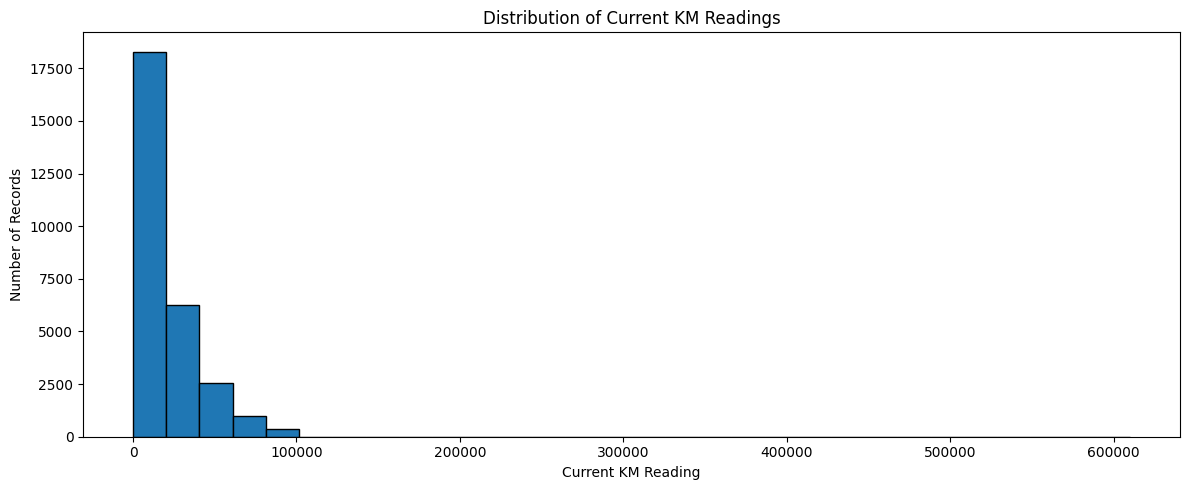

In [33]:


# Basic statistics of current kilometre readings

print("Current KM Reading Statistics:")

display(
    df_work['current_km_reading'].describe()
)

# Check minimum and maximum kilometre readings

print("\nMinimum KM Reading:",
      df_work['current_km_reading'].min())

print("Maximum KM Reading:",
      df_work['current_km_reading'].max())

# Visualize the distribution

plt.figure(figsize=(12, 5))

plt.hist(
    df_work['current_km_reading'],
    bins=30,
    edgecolor='black'
)

plt.title('Distribution of Current KM Readings')
plt.xlabel('Current KM Reading')
plt.ylabel('Number of Records')

plt.tight_layout()
plt.show()


In [34]:

# Investigate unusually high kilometre readings

high_km_records = df_work[
    df_work['current_km_reading'] > 63830.5
].sort_values(
    'current_km_reading',
    ascending=False
)

print("Records above the IQR upper boundary:",
      len(high_km_records))

print("\nTop 20 highest KM readings:")

display(
    high_km_records[
        [
            'invoice_date',
            'vehicle_model',
            'current_km_reading',
            'invoice_line_text'
        ]
    ].head(20)
)

# Check zero kilometre readings
zero_km_records = df_work[
    df_work['current_km_reading'] == 0
]

print("\nRecords with zero KM reading:",
      len(zero_km_records))


Records above the IQR upper boundary: 1179

Top 20 highest KM readings:


,invoice_date,vehicle_model,current_km_reading,invoice_line_text
8430,2017-12-29,BAJAJ PULSAR LS135,610112,GENERAL SERVICE
8428,2017-12-29,BAJAJ PULSAR LS135,610112,SPEEDOMETER CABLE
8429,2017-12-29,BAJAJ PULSAR LS135,610112,CHAIN LUBRICATION
447,2017-06-13,BAJAJ PULSAR 150,550147,AIR FILTER CHECKUP
452,2017-06-13,BAJAJ PULSAR 150,550147,WIRING CHECKUP
451,2017-06-13,BAJAJ PULSAR 150,550147,SPEEDOMETER CABLE
446,2017-06-13,BAJAJ PULSAR 150,550147,BATTERY CHARGE
445,2017-06-13,BAJAJ PULSAR 150,550147,BRAKE SHOE
449,2017-06-13,BAJAJ PULSAR 150,550147,PARKING BULB
450,2017-06-13,BAJAJ PULSAR 150,550147,GENERAL SERVICE



Records with zero KM reading: 842


In [35]:

# Group records by vehicle and invoice date

vehicle_km_groups = (
    df_work
    .groupby([
        'vehicle_no',
        'invoice_date',
        'vehicle_model',
        'current_km_reading'
    ])
    .size()
    .reset_index(name='invoice_line_count')
)

# Find groups with unusually high KM readings

high_km_groups = vehicle_km_groups[
    vehicle_km_groups['current_km_reading'] > 63830.5
].sort_values(
    'current_km_reading',
    ascending=False
)

print("Unique vehicle-date-reading groups above IQR boundary:",
      len(high_km_groups))

print("\nTop 20 unusual vehicle groups:")

display(high_km_groups.head(20))


# Investigate zero KM groups

zero_km_groups = vehicle_km_groups[
    vehicle_km_groups['current_km_reading'] == 0
]

print("\nUnique vehicle-date groups with zero KM:",
      len(zero_km_groups))

display(zero_km_groups.head(20))



Unique vehicle-date-reading groups above IQR boundary: 119

Top 20 unusual vehicle groups:


,vehicle_no,invoice_date,vehicle_model,current_km_reading,invoice_line_count
3906,MH14CRXXXX,2017-12-29,BAJAJ PULSAR LS135,610112,3
626,KA03JCXXXX,2017-06-13,BAJAJ PULSAR 150,550147,8
1205,KA09EPXXXX,2018-09-21,BAJAJ DISCOVER 135,516773,9
1388,KA51EFXXXX,2018-04-13,BAJAJ DISCOVER,461811,7
550,KA03HVXXXX,2017-11-04,BAJAJ PULSAR 150,287188,7
3747,KA53S3XXXX,2017-08-03,BAJAJ V,251447,2
1007,KA04EXXXXX,2017-12-15,BAJAJ XCD 125,99625,4
51,AP04L1XXXX,2017-10-13,BAJAJ PULSAR 150,97450,1
50,AP04L1XXXX,2017-10-04,BAJAJ PULSAR 150,97450,14
1303,KA36S8XXXX,2017-10-04,BAJAJ DISCOVER,96444,9



Unique vehicle-date groups with zero KM: 167


,vehicle_no,invoice_date,vehicle_model,current_km_reading,invoice_line_count
36,AP03BSXXXX,2018-03-22,BAJAJ PULSAR 150,0,4
76,AP16BXXXXX,2018-05-18,BAJAJ PULSAR 150,0,1
82,AP23AHXXXX,2018-06-28,BAJAJ PULSAR 150,0,7
88,AP27ARXXXX,2018-02-21,BAJAJ PULSAR 220,0,2
112,APPUGOXXXX,2017-08-21,BAJAJ PULSAR NS 200,0,4
126,CHANDRXXXX,2018-08-17,BAJAJ CT 100,0,6
140,DL45AYXXXX,2017-11-17,BAJAJ PULSAR 150,0,8
154,GOWNISXXXX,2017-11-04,BAJAJ PULSAR 220,0,5
159,HR10M4XXXX,2018-04-21,BAJAJ PULSAR 150,0,2
202,KA01ENXXXX,2018-08-04,BAJAJ AVENGER STREET 220,0,2


In [36]:

# Create one record per vehicle visit
# Remove repeated invoice lines only for this investigation

vehicle_visits = (
    df_work.groupby(
        ['vehicle_no', 'invoice_date', 'vehicle_model'],
        as_index=False
    )
    .agg(
        current_km_reading=('current_km_reading', 'max'),
        invoice_line_count=('invoice_line_text', 'size')
    )
)

# Sort visits chronologically
vehicle_visits = vehicle_visits.sort_values(
    ['vehicle_no', 'invoice_date']
)

# Calculate the previous reading for each vehicle
vehicle_visits['previous_km_reading'] = (
    vehicle_visits.groupby('vehicle_no')['current_km_reading']
    .shift(1)
)

# Calculate change in KM reading
vehicle_visits['km_difference'] = (
    vehicle_visits['current_km_reading']
    - vehicle_visits['previous_km_reading']
)

# Identify decreasing readings
decreasing_readings = vehicle_visits[
    vehicle_visits['km_difference'] < 0
]

print("Total vehicle visits:", len(vehicle_visits))

print("Visits with decreasing KM readings:",
      len(decreasing_readings))

print("\nExamples of decreasing readings:")

display(
    decreasing_readings[
        [
            'vehicle_no',
            'invoice_date',
            'vehicle_model',
            'previous_km_reading',
            'current_km_reading',
            'km_difference'
        ]
    ].head(20)
)


Total vehicle visits: 4074
Visits with decreasing KM readings: 1427

Examples of decreasing readings:


,vehicle_no,invoice_date,vehicle_model,previous_km_reading,current_km_reading,km_difference
1,177XXXX,2018-08-14,BAJAJ V150,2238.0,769,-1469.0
13,AP02AAXXXX,2018-02-15,BAJAJ DISCOVER 135,47632.0,34286,-13346.0
20,AP02BLXXXX,2018-10-08,BAJAJ PULSAR 150,17054.0,12627,-4427.0
24,AP03APXXXX,2017-12-12,BAJAJ PULSAR 150,59301.0,46319,-12982.0
36,AP03BSXXXX,2018-03-22,BAJAJ PULSAR 150,44638.0,0,-44638.0
78,AP16CLXXXX,2017-11-17,BAJAJ AVENGER STREET 220,15527.0,15526,-1.0
95,AP28DJXXXX,2018-05-12,BAJAJ PULSAR 150,41416.0,13558,-27858.0
126,CHANDRXXXX,2018-08-17,BAJAJ CT 100,786.0,0,-786.0
182,KA01EFXXXX,2018-01-12,BAJAJ DISCOVER,11314.0,5818,-5496.0
185,KA01EGXXXX,2018-11-16,BAJAJ DISCOVER 135,76305.0,33291,-43014.0


In [37]:

# Type A: Current reading becomes zero
zero_decreases = decreasing_readings[
    decreasing_readings['current_km_reading'] == 0
]

# Type B: Both readings are positive, but current reading decreases
positive_decreases = decreasing_readings[
    (decreasing_readings['previous_km_reading'] > 0) &
    (decreasing_readings['current_km_reading'] > 0)
]

print("Decreasing readings where current KM is zero:",
      len(zero_decreases))

print("\nDecreasing readings where both readings are positive:",
      len(positive_decreases))

print("\nPercentage of positive-to-positive decreases:",
      round(len(positive_decreases) / len(vehicle_visits) * 100, 2),
      "%")

print("\nExamples of positive-to-positive decreases:")

display(
    positive_decreases[
        [
            'vehicle_no',
            'invoice_date',
            'vehicle_model',
            'previous_km_reading',
            'current_km_reading',
            'km_difference'
        ]
    ].head(20)
)


Decreasing readings where current KM is zero: 100

Decreasing readings where both readings are positive: 1327

Percentage of positive-to-positive decreases: 32.57 %

Examples of positive-to-positive decreases:


,vehicle_no,invoice_date,vehicle_model,previous_km_reading,current_km_reading,km_difference
1,177XXXX,2018-08-14,BAJAJ V150,2238.0,769,-1469.0
13,AP02AAXXXX,2018-02-15,BAJAJ DISCOVER 135,47632.0,34286,-13346.0
20,AP02BLXXXX,2018-10-08,BAJAJ PULSAR 150,17054.0,12627,-4427.0
24,AP03APXXXX,2017-12-12,BAJAJ PULSAR 150,59301.0,46319,-12982.0
78,AP16CLXXXX,2017-11-17,BAJAJ AVENGER STREET 220,15527.0,15526,-1.0
95,AP28DJXXXX,2018-05-12,BAJAJ PULSAR 150,41416.0,13558,-27858.0
182,KA01EFXXXX,2018-01-12,BAJAJ DISCOVER,11314.0,5818,-5496.0
185,KA01EGXXXX,2018-11-16,BAJAJ DISCOVER 135,76305.0,33291,-43014.0
190,KA01EKXXXX,2018-02-22,BAJAJ AVENGER STREET 220,38910.0,21514,-17396.0
192,KA01ELXXXX,2017-08-04,BAJAJ PULSAR 150,51611.0,32975,-18636.0


In [38]:

# Count unique vehicle models associated with each vehicle number

vehicle_model_check = (
    df_work.groupby('vehicle_no')['vehicle_model']
    .nunique()
    .sort_values(ascending=False)
)

# Find vehicle numbers associated with multiple models
multiple_model_vehicles = vehicle_model_check[
    vehicle_model_check > 1
]

print(
    "Vehicle numbers associated with multiple models:",
    len(multiple_model_vehicles)
)

print("\nTop examples:")
display(multiple_model_vehicles.head(20))

# Inspect their actual records
problem_vehicle_numbers = multiple_model_vehicles.head(10).index

display(
    df_work[
        df_work['vehicle_no'].isin(problem_vehicle_numbers)
    ][
        [
            'vehicle_no',
            'invoice_date',
            'vehicle_model',
            'current_km_reading'
        ]
    ].sort_values(['vehicle_no', 'invoice_date'])
)


Vehicle numbers associated with multiple models: 158

Top examples:


,vehicle_model
vehicle_no,
KA53ETXXXX,13
KA53ERXXXX,13
KA53EPXXXX,13
KA53EVXXXX,13
KA53EWXXXX,13
KA53EXXXXX,12
KA53ESXXXX,12
KA53EYXXXX,12
KA53EUXXXX,12


,vehicle_no,invoice_date,vehicle_model,current_km_reading
99,KA53EPXXXX,2017-06-02,BAJAJ PULSAR 150,4707
100,KA53EPXXXX,2017-06-02,BAJAJ PULSAR 150,4707
101,KA53EPXXXX,2017-06-02,BAJAJ PULSAR 150,4707
152,KA53EPXXXX,2017-06-04,BAJAJ PULSAR 220,8517
153,KA53EPXXXX,2017-06-04,BAJAJ PULSAR 220,8517
...,...,...,...,...
28468,KA53EYXXXX,2019-01-06,BAJAJ PULSAR 150,3425
28469,KA53EYXXXX,2019-01-06,BAJAJ PULSAR 150,3425
28470,KA53EYXXXX,2019-01-06,BAJAJ PULSAR 150,3425
28471,KA53EYXXXX,2019-01-06,BAJAJ PULSAR 150,3425


In [39]:

# Distribution of number of models per vehicle number

model_count_distribution = (
    vehicle_model_check
    .value_counts()
    .sort_index()
)

print("Distribution of models per vehicle number:")
display(model_count_distribution)

# Total unique vehicle numbers
print(
    "\nTotal unique vehicle numbers:",
    df_work['vehicle_no'].nunique()
)

# Vehicle numbers associated with exactly one model
print(
    "\nVehicle numbers associated with one model:",
    (vehicle_model_check == 1).sum()
)

# Vehicle numbers associated with multiple models
print(
    "Vehicle numbers associated with multiple models:",
    (vehicle_model_check > 1).sum()
)


Distribution of models per vehicle number:


,count
vehicle_model,
1,688
2,76
3,24
4,21
5,9
6,4
7,4
8,4
9,4



Total unique vehicle numbers: 846

Vehicle numbers associated with one model: 688
Vehicle numbers associated with multiple models: 158


In [40]:
same_date_multiple_models = (
    df_work.groupby(['vehicle_no', 'invoice_date'])['vehicle_model']
    .nunique()
)

same_date_multiple_models = same_date_multiple_models[
    same_date_multiple_models > 1
]

print("Vehicle number and date combinations with multiple models:",
      len(same_date_multiple_models))

display(same_date_multiple_models.head(10))

Vehicle number and date combinations with multiple models: 325


,,vehicle_model
vehicle_no,invoice_date,
KA03JCXXXX,2017-09-23,2
KA03JLXXXX,2017-07-18,2
KA03JNXXXX,2018-02-27,2
KA03JPXXXX,2018-02-12,2
KA03JQXXXX,2018-03-13,2
KA03JRXXXX,2018-05-15,2
KA07W4XXXX,2018-03-23,2
KA51EXXXXX,2017-07-10,2
KA53EDXXXX,2017-06-05,2


In [41]:
df_work[
    (df_work['vehicle_no'] == 'KA03JCXXXX') &
    (df_work['invoice_date'] == '2017-09-23')
].sort_values('vehicle_model')[
    [
        'invoice_date',
        'vehicle_no',
        'vehicle_model',
        'current_km_reading',
        'invoice_line_text'
    ]
]

,invoice_date,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
4518,2017-09-23,KA03JCXXXX,BAJAJ PULSAR 150,7388,GENERAL SERVICE
4519,2017-09-23,KA03JCXXXX,BAJAJ PULSAR 150,7388,ENGINE OIL
4520,2017-09-23,KA03JCXXXX,BAJAJ PULSAR 150,7388,AIR FILTER
4521,2017-09-23,KA03JCXXXX,BAJAJ PULSAR 150,7388,CHAIN LUBRICATION
4500,2017-09-23,KA03JCXXXX,BAJAJ PULSAR AS 200,17414,ENGINE OIL
4501,2017-09-23,KA03JCXXXX,BAJAJ PULSAR AS 200,17414,GENERAL SERVICE
4502,2017-09-23,KA03JCXXXX,BAJAJ PULSAR AS 200,17414,OIL FILTER
4503,2017-09-23,KA03JCXXXX,BAJAJ PULSAR AS 200,17414,CHAIN LUBRICATION
4504,2017-09-23,KA03JCXXXX,BAJAJ PULSAR AS 200,17414,AIR FILTER
4505,2017-09-23,KA03JCXXXX,BAJAJ PULSAR AS 200,17414,AIR FILTER


In [42]:
same_vehicle_date_model = (
    df_work.groupby(
        ['vehicle_no', 'invoice_date', 'vehicle_model']
    )['current_km_reading']
    .nunique()
)

multiple_km_readings = same_vehicle_date_model[
    same_vehicle_date_model > 1
]

print(
    "Vehicle-date-model groups with multiple KM readings:",
    len(multiple_km_readings)
)

display(multiple_km_readings.head(10))

Vehicle-date-model groups with multiple KM readings: 78


vehicle_no  invoice_date  vehicle_model           
KA03HLXXXX  2017-10-11    BAJAJ PULSAR LS135          2
KA03JQXXXX  2018-05-15    BAJAJ PULSAR NS 200         2
KA04HFXXXX  2018-09-22    BAJAJ PULSAR 150            2
KA53EMXXXX  2018-06-11    BAJAJ AVENGER STREET 220    2
KA53ENXXXX  2017-08-17    BAJAJ AVENGER STREET        2
            2018-05-10    BAJAJ PULSAR 150            2
KA53EPXXXX  2017-10-31    BAJAJ AVENGER STREET 220    2
            2018-06-30    BAJAJ AVENGER STREET 220    2
            2018-09-25    BAJAJ AVENGER STREET 220    2
            2018-12-14    BAJAJ PULSAR 220            2
Name: current_km_reading, dtype: int64

In [43]:
df_work[
    (df_work['vehicle_no'] == 'KA03HLXXXX') &
    (df_work['invoice_date'] == '2017-10-11') &
    (df_work['vehicle_model'] == 'BAJAJ PULSAR LS135')
][
    [
        'invoice_date',
        'vehicle_no',
        'vehicle_model',
        'current_km_reading',
        'invoice_line_text'
    ]
].sort_values('current_km_reading')

,invoice_date,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
5171,2017-10-11,KA03HLXXXX,BAJAJ PULSAR LS135,24016,SWITCH
5172,2017-10-11,KA03HLXXXX,BAJAJ PULSAR LS135,24016,AIR FILTER
5173,2017-10-11,KA03HLXXXX,BAJAJ PULSAR LS135,24016,CHAIN SPROCKET
5174,2017-10-11,KA03HLXXXX,BAJAJ PULSAR LS135,24016,GENERAL SERVICE
5175,2017-10-11,KA03HLXXXX,BAJAJ PULSAR LS135,24016,BRAKE SHOE
5176,2017-10-11,KA03HLXXXX,BAJAJ PULSAR LS135,24016,WHEEL RUBBER
5177,2017-10-11,KA03HLXXXX,BAJAJ PULSAR LS135,24016,ENGINE OIL TOPUP
5178,2017-10-11,KA03HLXXXX,BAJAJ PULSAR LS135,37112,DISC ASSEMBLY
5179,2017-10-11,KA03HLXXXX,BAJAJ PULSAR LS135,37112,GENERAL SERVICE
5180,2017-10-11,KA03HLXXXX,BAJAJ PULSAR LS135,37112,CLUTCH ASSEMBLY


In [44]:
print("Number of groups with 2 KM readings:",
      (multiple_km_readings == 2).sum())

print("Number of groups with 3 KM readings:",
      (multiple_km_readings == 3).sum())

print("Number of groups with more than 3 KM readings:",
      (multiple_km_readings > 3).sum())

print("\nMaximum distinct KM readings in one group:",
      multiple_km_readings.max())

Number of groups with 2 KM readings: 74
Number of groups with 3 KM readings: 4
Number of groups with more than 3 KM readings: 0

Maximum distinct KM readings in one group: 3


In [45]:
unique_invoice_items = sorted(
    df_work['invoice_line_text'].dropna().unique()
)

print("Total unique invoice descriptions:", len(unique_invoice_items))

for item in unique_invoice_items:
    print(item)

Total unique invoice descriptions: 503

10 SIZE NUT
12 SIZE BOLT
3M OIL
4 WAY SWITCH
6004 BEARING
6202 BEARING
6303 BEARING
8 SIZE BOLT
ACCELATOR CABLE
ADD ON FEES
AIR FILTER
AIR FILTER CHECKUP
AIR INTAKE
AXLE
BALANCING GEAR
BATTERY
BATTERY BELT
BATTERY CHARGE
BATTERY CLIP
BATTERY TARMINAL
BC UNIT
BEARING
BEARING SET
BEARING WIELDING
BEDDING BOLT
BODY 
BODY COVER
BOLT REMOVAL
BOLT WIELDING
BORE
BORE GASKET
BORE KIT
BOTTLE COIL
BRAKE ADJUSTMENT
BRAKE BUSH KIT
BRAKE CABLE
BRAKE LEVER
BRAKE LIGHT SPRING
BRAKE LIGHT SWITCH
BRAKE LIGHT SWITCH 
BRAKE PEDAL
BRAKE PEDAL RUBBER
BRAKE PEDAL SPRING
BRAKE ROD
BRAKE ROD SPRING
BRAKE RUBBER
BRAKE SHOE
BRAKE SWITCH
BULB
BULB 
BULB HOLDER
BUSH KIT
BUZZER
CABLE LOCK
CAHIN PAD SCREW
CALIPER ASSEMBLY
CALIPER RUBBER KIT
CAM SHAFT
CAM SHAFT SPRING
CARBURETOR
CARBURETOR ASSEMBLY
CARBURETOR CLEANING
CARBURETOR DIAPHRAGM RUBBER
CARBURETOR PLATE
CARBURETOR SPRING
CASE BEARING
CASE WELDING
CDI UNIT
CENTER STAND
CENTER STAND SPRING
CHAIN ADJUSTER
CHAIN ADJUSTER 

In [46]:
item_frequency = (
    df_work['invoice_line_text']
    .value_counts(dropna=False)
    .reset_index()
)

item_frequency.columns = [
    'invoice_description',
    'record_count'
]

print("Total invoice descriptions:", len(item_frequency))

display(item_frequency.head(30))

Total invoice descriptions: 504


,invoice_description,record_count
0,ENGINE OIL,3802
1,CHAIN LUBRICATION,3441
2,GENERAL SERVICE,2142
3,AIR FILTER,1715
4,3M OIL,1628
5,CONSUMABLES,1595
6,POLISH,1245
7,DISC OIL,991
8,BRAKE SHOE,965
9,OIL FILTER,821


In [47]:
item_frequency['percentage'] = (
    item_frequency['record_count'] / len(df_work) * 100
)

item_frequency['cumulative_percentage'] = (
    item_frequency['percentage'].cumsum()
)

for n in [10, 20, 30, 50]:
    contribution = item_frequency.head(n)['record_count'].sum()
    percentage = contribution / len(df_work) * 100

    print(
        f"Top {n} descriptions: "
        f"{contribution:,} records "
        f"({percentage:.2f}%)"
    )

Top 10 descriptions: 18,345 records (64.41%)
Top 20 descriptions: 22,145 records (77.75%)
Top 30 descriptions: 23,399 records (82.15%)
Top 50 descriptions: 24,888 records (87.38%)


In [48]:
partner_frequency = (
    df_work['business_partner_name']
    .value_counts()
    .reset_index()
)

partner_frequency.columns = [
    'business_partner',
    'record_count'
]

print("Total unique business partners:",
      df_work['business_partner_name'].nunique())

display(partner_frequency.head(20))

Total unique business partners: 1010


,business_partner,record_count
0,venkXXXXXXXXXX,424
1,manjXXXXXXXXXX,362
2,prasXXXXXXXXXX,328
3,shivXXXXXXXXXX,314
4,chanXXXXXXXXXX,312
5,raviXXXXXXXXXX,310
6,santXXXXXXXXXX,296
7,hariXXXXXXXXXX,284
8,PRASXXXXXXXXXX,251
9,arunXXXXXXXXXX,242


In [49]:
for n in [10, 20, 50, 100]:
    records = partner_frequency.head(n)['record_count'].sum()
    percentage = records / len(df_work) * 100

    print(
        f"Top {n} business partners: "
        f"{records:,} records "
        f"({percentage:.2f}%)"
    )

Top 10 business partners: 3,123 records (10.96%)
Top 20 business partners: 5,089 records (17.87%)
Top 50 business partners: 9,092 records (31.92%)
Top 100 business partners: 13,292 records (46.67%)


In [50]:
vehicle_model_frequency = (
    df_work['vehicle_model']
    .value_counts()
    .reset_index()
)

vehicle_model_frequency.columns = [
    'vehicle_model',
    'record_count'
]

vehicle_model_frequency['percentage'] = (
    vehicle_model_frequency['record_count']
    / len(df_work) * 100
)

display(vehicle_model_frequency)

,vehicle_model,record_count,percentage
0,BAJAJ PULSAR 150,8633,30.310371
1,BAJAJ AVENGER STREET 220,4212,14.788287
2,BAJAJ PULSAR 220,2655,9.321677
3,BAJAJ PULSAR 180,2252,7.906748
4,BAJAJ PULSAR NS 200,2204,7.738221
5,BAJAJ CT 100,1432,5.027737
6,BAJAJ DISCOVER 125,1346,4.725792
7,BAJAJ AVENGER STREET,1112,3.904220
8,BAJAJ PLATINA,844,2.963275
9,BAJAJ V150,686,2.408539


In [51]:
air_filter_by_model = (
    df_work[
        df_work['invoice_line_text'].str.strip().str.upper()
        == 'AIR FILTER'
    ]
    .groupby('vehicle_model')
    .size()
    .reset_index(name='record_count')
    .sort_values('record_count', ascending=False)
)

air_filter_by_model['percentage'] = (
    air_filter_by_model['record_count']
    / air_filter_by_model['record_count'].sum() * 100
)

display(air_filter_by_model)

,vehicle_model,record_count,percentage
10,BAJAJ PULSAR 150,554,32.303207
2,BAJAJ AVENGER STREET 220,301,17.551020
12,BAJAJ PULSAR 220,182,10.612245
11,BAJAJ PULSAR 180,169,9.854227
0,BAJAJ AVENGER STREET,87,5.072886
16,BAJAJ PULSAR NS 200,71,4.139942
4,BAJAJ CT 100,66,3.848397
6,BAJAJ DISCOVER 125,60,3.498542
5,BAJAJ DISCOVER,44,2.565598
9,BAJAJ PLATINA,38,2.215743


In [52]:
important_items = ['AIR FILTER', 'ENGINE OIL']

item_model_comparison = (
    df_work[
        df_work['invoice_line_text'].str.strip().str.upper()
        .isin(important_items)
    ]
    .groupby(['invoice_line_text', 'vehicle_model'])
    .size()
    .unstack(fill_value=0)
)

item_model_comparison = item_model_comparison.T

item_model_comparison['TOTAL'] = item_model_comparison.sum(axis=1)

display(
    item_model_comparison.sort_values(
        'TOTAL',
        ascending=False
    )
)

invoice_line_text,AIR FILTER,ENGINE OIL,TOTAL
vehicle_model,,,
BAJAJ PULSAR 150,554,1066,1620
BAJAJ AVENGER STREET 220,301,591,892
BAJAJ PULSAR 220,182,338,520
BAJAJ PULSAR 180,169,303,472
BAJAJ PULSAR NS 200,71,297,368
BAJAJ CT 100,66,243,309
BAJAJ AVENGER STREET,87,171,258
BAJAJ DISCOVER 125,60,168,228
BAJAJ PLATINA,38,129,167


In [53]:
df_item_monthly = df_work.copy()

df_item_monthly['month'] = (
    df_item_monthly['invoice_date'].dt.to_period('M')
)

monthly_item_comparison = (
    df_item_monthly[
        df_item_monthly['invoice_line_text'].str.strip().str.upper()
        .isin(['AIR FILTER', 'ENGINE OIL'])
    ]
    .groupby(['month', 'invoice_line_text'])
    .size()
    .unstack(fill_value=0)
)

display(monthly_item_comparison)

invoice_line_text,AIR FILTER,ENGINE OIL
month,,
2017-05,0,5
2017-06,5,179
2017-07,34,172
2017-08,52,146
2017-09,77,187
2017-10,70,158
2017-11,89,191
2017-12,112,213
2018-01,77,154


In [54]:
monthly_total = (
    df_item_monthly
    .groupby('month')
    .size()
    .rename('total_records')
)

monthly_share = monthly_item_comparison.join(monthly_total)

monthly_share['AIR_FILTER_SHARE'] = (
    monthly_share['AIR FILTER']
    / monthly_share['total_records'] * 100
)

monthly_share['ENGINE_OIL_SHARE'] = (
    monthly_share['ENGINE OIL']
    / monthly_share['total_records'] * 100
)

display(monthly_share.round(2))

,AIR FILTER,ENGINE OIL,total_records,AIR_FILTER_SHARE,ENGINE_OIL_SHARE
month,,,,,
2017-05,0,5,11,0.00,45.45
2017-06,5,179,1346,0.37,13.30
2017-07,34,172,1178,2.89,14.60
2017-08,52,146,973,5.34,15.01
2017-09,77,187,1264,6.09,14.79
2017-10,70,158,1054,6.64,14.99
2017-11,89,191,1376,6.47,13.88
2017-12,112,213,1345,8.33,15.84
2018-01,77,154,998,7.72,15.43


In [55]:
monthly_total_df = monthly_total.reset_index()

monthly_total_df.columns = [
    'month',
    'total_records'
]

display(monthly_total_df)

,month,total_records
0,2017-05,11
1,2017-06,1346
2,2017-07,1178
3,2017-08,973
4,2017-09,1264
5,2017-10,1054
6,2017-11,1376
7,2017-12,1345
8,2018-01,998
9,2018-02,1341


In [56]:

monthly_activity = (
    df_work.groupby('month' if 'month' in df_work.columns else
                    df_work['invoice_date'].dt.to_period('M'))
    .agg(
        total_records=('invoice_date', 'size'),
        active_days=('invoice_date', 'nunique')
    )
)

monthly_activity['records_per_active_day'] = (
    monthly_activity['total_records']
    / monthly_activity['active_days']
)

display(monthly_activity.round(2))

,total_records,active_days,records_per_active_day
invoice_date,,,
2017-05,11,2,5.50
2017-06,1346,30,44.87
2017-07,1178,27,43.63
2017-08,973,28,34.75
2017-09,1264,29,43.59
2017-10,1054,22,47.91
2017-11,1376,29,47.45
2017-12,1345,31,43.39
2018-01,998,29,34.41


In [57]:
items_to_compare = [
    'BRAKE SHOE',
    'OIL FILTER',
    'CHAIN SPROCKET'
]

monthly_three_items = (
    df_item_monthly[
        df_item_monthly['invoice_line_text'].str.strip().str.upper()
        .isin(items_to_compare)
    ]
    .groupby(['month', 'invoice_line_text'])
    .size()
    .unstack(fill_value=0)
)

display(monthly_three_items)

invoice_line_text,BRAKE SHOE,CHAIN SPROCKET,OIL FILTER
month,,,
2017-05,0,0,1
2017-06,44,9,34
2017-07,35,19,21
2017-08,29,15,29
2017-09,36,11,25
2017-10,41,19,27
2017-11,51,17,26
2017-12,47,14,33
2018-01,38,18,22


In [58]:
monthly_item_business = monthly_three_items.join(monthly_total)

for item in items_to_compare:
    monthly_item_business[f'{item}_share'] = (
        monthly_item_business[item]
        / monthly_item_business['total_records'] * 100
    )

display(monthly_item_business.round(2))

,BRAKE SHOE,CHAIN SPROCKET,OIL FILTER,total_records,BRAKE SHOE_share,OIL FILTER_share,CHAIN SPROCKET_share
month,,,,,,,
2017-05,0,0,1,11,0.00,9.09,0.00
2017-06,44,9,34,1346,3.27,2.53,0.67
2017-07,35,19,21,1178,2.97,1.78,1.61
2017-08,29,15,29,973,2.98,2.98,1.54
2017-09,36,11,25,1264,2.85,1.98,0.87
2017-10,41,19,27,1054,3.89,2.56,1.80
2017-11,51,17,26,1376,3.71,1.89,1.24
2017-12,47,14,33,1345,3.49,2.45,1.04
2018-01,38,18,22,998,3.81,2.20,1.80


In [59]:
df_weekly_items = df_work.copy()

df_weekly_items['weekday'] = (
    df_weekly_items['invoice_date'].dt.day_name()
)

weekday_item_comparison = (
    df_weekly_items[
        df_weekly_items['invoice_line_text'].str.strip().str.upper()
        .isin(['BRAKE SHOE', 'OIL FILTER', 'CHAIN SPROCKET'])
    ]
    .groupby(['weekday', 'invoice_line_text'])
    .size()
    .unstack(fill_value=0)
)

weekday_item_comparison = weekday_item_comparison.reindex([
    'Monday',
    'Tuesday',
    'Wednesday',
    'Thursday',
    'Friday',
    'Saturday',
    'Sunday'
])

display(weekday_item_comparison)

invoice_line_text,BRAKE SHOE,CHAIN SPROCKET,OIL FILTER
weekday,,,
Monday,126,58,121
Tuesday,174,78,134
Wednesday,111,52,115
Thursday,154,54,121
Friday,129,52,120
Saturday,199,78,148
Sunday,72,24,62


In [60]:
weekday_item_average = (
    df_weekly_items[
        df_weekly_items['invoice_line_text'].str.strip().str.upper()
        .isin(['BRAKE SHOE', 'OIL FILTER', 'CHAIN SPROCKET'])
    ]
    .groupby([
        df_weekly_items['invoice_date'].dt.day_name(),
        'invoice_line_text'
    ])
    .size()
    .unstack(fill_value=0)
)

weekday_active_days = (
    df_work.groupby(df_work['invoice_date'].dt.day_name())
    ['invoice_date'].nunique()
)

weekday_item_average = (
    weekday_item_average
    .div(weekday_active_days, axis=0)
    .reindex([
        'Monday', 'Tuesday', 'Wednesday',
        'Thursday', 'Friday', 'Saturday', 'Sunday'
    ])
)

display(weekday_item_average.round(2))

invoice_line_text,BRAKE SHOE,CHAIN SPROCKET,OIL FILTER
invoice_date,,,
Monday,1.56,0.72,1.49
Tuesday,2.10,0.94,1.61
Wednesday,1.35,0.63,1.40
Thursday,1.97,0.69,1.55
Friday,1.65,0.67,1.54
Saturday,2.40,0.94,1.78
Sunday,1.03,0.34,0.89


In [61]:
df_date_analysis = df_work.copy()

df_date_analysis['job_to_invoice_days'] = (
    df_date_analysis['invoice_date']
    - df_date_analysis['job_card_date']
).dt.days

print("Job-to-invoice difference statistics:")

display(
    df_date_analysis['job_to_invoice_days'].describe()
)

print("\nNegative differences:")
print(
    (df_date_analysis['job_to_invoice_days'] < 0).sum()
)

print("\nZero-day differences:")
print(
    (df_date_analysis['job_to_invoice_days'] == 0).sum()
)

print("\nPositive differences:")
print(
    (df_date_analysis['job_to_invoice_days'] > 0).sum()
)

Job-to-invoice difference statistics:


,job_to_invoice_days
count,28482.000000
mean,0.034653
std,0.439955
min,-1.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,19.000000



Negative differences:
5

Zero-day differences:
28066

Positive differences:
411


In [62]:
display(
    df_date_analysis[
        df_date_analysis['job_to_invoice_days'] < 0
    ][[
        'job_card_date',
        'invoice_date',
        'business_partner_name',
        'vehicle_no',
        'vehicle_model',
        'invoice_line_text',
        'job_to_invoice_days'
    ]]
)

,job_card_date,invoice_date,business_partner_name,vehicle_no,vehicle_model,invoice_line_text,job_to_invoice_days
19044,2018-08-15,2018-08-14,reetXXXXXXXXXX,177XXXX,BAJAJ V150,ENGINE OIL,-1
19045,2018-08-15,2018-08-14,reetXXXXXXXXXX,177XXXX,BAJAJ V150,GENERAL SERVICE,-1
19046,2018-08-15,2018-08-14,reetXXXXXXXXXX,177XXXX,BAJAJ V150,POLISH,-1
19047,2018-08-15,2018-08-14,reetXXXXXXXXXX,177XXXX,BAJAJ V150,AIR FILTER CHECKUP,-1
19048,2018-08-15,2018-08-14,reetXXXXXXXXXX,177XXXX,BAJAJ V150,OIL FILTER,-1


In [63]:
print("Unique business partners:",
      df_work['business_partner_name'].nunique())

print("\nTop 15 business partners:")
display(
    df_work['business_partner_name']
    .value_counts()
    .head(15)
)

Unique business partners: 1010

Top 15 business partners:


,count
business_partner_name,
venkXXXXXXXXXX,424
manjXXXXXXXXXX,362
prasXXXXXXXXXX,328
shivXXXXXXXXXX,314
chanXXXXXXXXXX,312
raviXXXXXXXXXX,310
santXXXXXXXXXX,296
hariXXXXXXXXXX,284
PRASXXXXXXXXXX,251


In [64]:
top_5_partners = (
    df_work['business_partner_name']
    .value_counts()
    .head(5)
    .index
)

partner_monthly = (
    df_work[
        df_work['business_partner_name'].isin(top_5_partners)
    ]
    .groupby([
        df_work['invoice_date'].dt.to_period('M'),
        'business_partner_name'
    ])
    .size()
    .unstack(fill_value=0)
)

display(partner_monthly)

business_partner_name,chanXXXXXXXXXX,manjXXXXXXXXXX,prasXXXXXXXXXX,shivXXXXXXXXXX,venkXXXXXXXXXX
invoice_date,,,,,
2017-05,0,0,0,1,0
2017-06,47,16,15,22,21
2017-07,7,0,6,39,14
2017-08,0,20,26,11,16
2017-09,9,14,19,10,34
2017-10,12,5,22,34,21
2017-11,10,29,8,24,17
2017-12,7,13,19,12,21
2018-01,6,4,20,14,5


The top five business partners show fluctuating monthly invoice activity. Their transaction frequency varies across months, with some partners having zero recorded activity in certain months. This indicates variation in partner-level invoice activity, but the reason for these changes is unknown.

In [65]:
partner_counts = df_work['business_partner_name'].value_counts()

total_records = len(df_work)

for n in [10, 20, 50, 100]:
    records = partner_counts.head(n).sum()
    percentage = (records / total_records) * 100

    print(
        f"Top {n} partners: {records} records "
        f"({percentage:.2f}%)"
    )

Top 10 partners: 3123 records (10.96%)
Top 20 partners: 5089 records (17.87%)
Top 50 partners: 9092 records (31.92%)
Top 100 partners: 13292 records (46.67%)


In [66]:
missing_analysis = pd.DataFrame({
    'Missing_Count': df_work.isnull().sum(),
    'Missing_Percentage': (
        df_work.isnull().sum() / len(df_work) * 100
    ).round(2)
})

display(missing_analysis)

,Missing_Count,Missing_Percentage
invoice_date,0,0.00
job_card_date,0,0.00
business_partner_name,0,0.00
vehicle_no,0,0.00
vehicle_model,0,0.00
current_km_reading,0,0.00
invoice_line_text,6,0.02


In [67]:
print("Original unique descriptions:",
      df_work['invoice_line_text'].nunique())

print("\nDescriptions with leading/trailing spaces:")

space_records = df_work[
    df_work['invoice_line_text'].notna() &
    (
        df_work['invoice_line_text'] !=
        df_work['invoice_line_text'].str.strip()
    )
]

display(space_records[['invoice_line_text']].drop_duplicates())

Original unique descriptions: 503

Descriptions with leading/trailing spaces:


,invoice_line_text
134,CLUTCH CAM
595,SWITCH
2481,BULB
5952,BODY
8830,BRAKE LIGHT SWITCH
15935,STAND LOCK PIN


In [68]:
description_case_check = (
    df_work['invoice_line_text']
    .dropna()
    .str.strip()
    .groupby(lambda x: x)
)

normalized_descriptions = (
    df_work['invoice_line_text']
    .dropna()
    .str.strip()
    .str.upper()
)

case_variations = (
    df_work.assign(normalized_description=normalized_descriptions)
    .groupby('normalized_description')['invoice_line_text']
    .nunique()
)

display(case_variations[case_variations > 1])

,invoice_line_text
normalized_description,
BORE KIT,2
BRAKE LIGHT SWITCH,2
BULB,2
CLUTCH CABLE,4
HANDLE WEIGHT,2
SWITCH,2
TYRE,2


In [69]:
temp = df_work[
    df_work['invoice_line_text'].notna()
].copy()

temp['normalized_description'] = (
    temp['invoice_line_text']
    .str.strip()
    .str.upper()
)

variation_list = (
    temp.groupby('normalized_description')['invoice_line_text']
    .unique()
)

display(
    variation_list[
        variation_list.apply(len) > 1
    ]
)

,invoice_line_text
normalized_description,
BORE KIT,"[BORE KIT, bore kit]"
BRAKE LIGHT SWITCH,"[BRAKE LIGHT SWITCH, BRAKE LIGHT SWITCH ]"
BULB,"[BULB , BULB]"
CLUTCH CABLE,"[CLUTCH CABLE, Clutch cable, clutch cable, Clu..."
HANDLE WEIGHT,"[HANDLE WEIGHT, handle weight]"
SWITCH,"[SWITCH, SWITCH ]"
TYRE,"[TYRE, tyre]"


In [70]:
df_work['normalized_description'] = (
    df_work['invoice_line_text']
    .str.strip()
    .str.upper()
)

In [71]:
descriptions = sorted(
    df_work['invoice_line_text']
    .dropna()
    .str.strip()
    .str.upper()
    .unique()
)

for item in descriptions:
    if any(word in item for word in [
        'DISC', 'DISK', 'MUD', 'SPEED', 'SPPED',
        'CLUTCH', 'TYRE', 'TIRE'
    ]):
        print(item)

CLUTCH ADJUSTMENT
CLUTCH ASSEMBLY
CLUTCH BELL REST
CLUTCH CABLE
CLUTCH CAM
CLUTCH CAM SPRING
CLUTCH CAM SWITCH
CLUTCH COVER GASKET
CLUTCH COVER PACKING
CLUTCH LEVER
CLUTCH OUTLET PIPE
CLUTCH OVERHUAL
CLUTCH REPALCEMENT
CLUTCH ROLLERS
CLUTCH SHOE
CLUTCH SPRING KIT
CLUTCH SWITCH
CLUTCH YOUCK
DISC ASSEMBLY
DISC HOSE PIPE
DISC LEVER
DISC OIL
DISC OIL TOPUP
DISC OVERHUAL
DISC PAD
DISC PLATE
DISC PUMP KIT
DISK PAD
DISK PLATE
FRONT MUDGUARD
MUDGAURD
MUDGAURD CLAMP
MUDGUARD
MUDGUARD BOLT
MUDGUARD CLAMP
MUDGUARD FLOP
ONE WAY CLUTCH
ONE WAY CLUTCH ASSEMBLY
ONE WAY CLUTCH BODY
ONE WAY CLUTCH BUSH KIT
SERVICE AND ONE WAY CLUTCH BUSH KIT
SPEEDOMETER
SPEEDOMETER BULB
SPEEDOMETER CABLE
SPEEDOMETER CAP
SPEEDOMETER CLAMP
SPEEDOMETER COVER
SPEEDOMETER FLOP
SPEEDOMETER GLASS
SPEEDOMETER STAY
SPEEDOMETER WORM
SPPEDOMETER CABLE
TYRE
TYRE GUARD
TYRE REPLACEMENT


In [72]:
spelling_candidates = [
    'DISK PAD',
    'DISK PLATE',
    'MUDGAURD',
    'SPPEDOMETER CABLE',
    'CLUTCH OVERHUAL',
    'CLUTCH REPALCEMENT'
]

spelling_counts = (
    df_work.assign(
        normalized_description=(
            df_work['invoice_line_text']
            .str.strip()
            .str.upper()
        )
    )
    .groupby('normalized_description')
    .size()
    .reindex(spelling_candidates, fill_value=0)
    .reset_index(name='record_count')
)

display(spelling_counts)

,normalized_description,record_count
0,DISK PAD,63
1,DISK PLATE,1
2,MUDGAURD,1
3,SPPEDOMETER CABLE,1
4,CLUTCH OVERHUAL,163
5,CLUTCH REPALCEMENT,1


In [73]:
print("Total records:", len(df_work))

print(
    "Exact duplicate records:",
    df_work.duplicated().sum()
)

print(
    "Records involved in duplicate groups:",
    df_work.duplicated(keep=False).sum()
)

print(
    "Unique records after removing duplicates:",
    len(df_work.drop_duplicates())
)

Total records: 28482
Exact duplicate records: 383
Records involved in duplicate groups: 720
Unique records after removing duplicates: 28099




The dataset contains 383 exact duplicate copies, involving 720 records across duplicate groups. These records require further validation before deduplication because identical invoice lines may represent legitimate transactions or data-entry duplication.

In [74]:
duplicate_frequency = (
    df_work[df_work.duplicated(keep=False)]
    .value_counts()
    .value_counts()
    .sort_index()
)

display(
    duplicate_frequency.rename_axis(
        'Number_of_repetitions'
    ).reset_index(name='Number_of_groups')
)

,Number_of_repetitions,Number_of_groups
0,2,315
1,3,11
2,4,3
3,5,6
4,13,1


The dataset contains 336 exact duplicate groups involving 720 records. Most groups occur twice, while one group occurs 13 times. Duplicate records have been identified but not removed because their business validity is unknown.


In [75]:
duplicate_counts = (
    df_work.value_counts()
    .reset_index(name='repetition_count')
)

display(
    duplicate_counts[
        duplicate_counts['repetition_count'] == 13
    ]
)

,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text,normalized_description,repetition_count
0,2018-02-27,2018-02-27,PRAVXXXXXXXXXX,KA04JBXXXX,BAJAJ PULSAR 150,24447,,,13


In [76]:
missing_description_duplicates = df_work[
    df_work['invoice_line_text'].isna()
]

print("Missing description records:",
      len(missing_description_duplicates))

print("\nMissing description records by repetition:")
display(
    missing_description_duplicates.value_counts()
    .reset_index(name='repetition_count')
)

Missing description records: 6

Missing description records by repetition:


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text,normalized_description,repetition_count


In [77]:
missing_description_duplicates = df_work[
    df_work['invoice_line_text'].isna()
]

display(
    missing_description_duplicates
    .groupby(list(df_work.columns), dropna=False)
    .size()
    .reset_index(name='repetition_count')
)

,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text,normalized_description,repetition_count
0,2017-06-15,2017-06-14,kailXXXXXXXXXX,KA01HNXXXX,BAJAJ PULSAR 150,8679,NaN,NaN,1
1,2017-06-15,2017-06-14,naveXXXXXXXXXX,KA53W3XXXX,BAJAJ DISCOVER 150,25677,NaN,NaN,2
2,2017-06-16,2017-06-16,hariXXXXXXXXXX,KA53ESXXXX,BAJAJ AVENGER STREET,457,NaN,NaN,1
3,2017-08-01,2017-08-01,hariXXXXXXXXXX,KA53EQXXXX,BAJAJ PULSAR 150,9677,NaN,NaN,1
4,2017-08-03,2017-08-03,diliXXXXXXXXXX,KA53S3XXXX,BAJAJ V,251447,NaN,NaN,1


In [78]:
print("Dataset already sorted by invoice_date:",
      df_work['invoice_date'].is_monotonic_increasing)

print("\nFirst 10 invoice dates:")
display(df_work['invoice_date'].head(10))

print("\nLast 10 invoice dates:")
display(df_work['invoice_date'].tail(10))

Dataset already sorted by invoice_date: False

First 10 invoice dates:


,invoice_date
0,2017-05-30
1,2017-06-02
2,2017-06-02
3,2017-06-02
4,2017-06-02
5,2017-06-02
6,2017-06-02
7,2017-05-31
8,2017-05-31
9,2017-05-31



Last 10 invoice dates:


,invoice_date
28472,2019-01-06
28473,2019-01-06
28474,2019-01-06
28475,2019-01-06
28476,2019-01-06
28477,2019-01-06
28478,2019-01-06
28479,2019-01-06
28480,2019-01-06
28481,2019-01-06


The dataset is not arranged in chronological order. Invoice dates appear in a mixed sequence, although the dataset includes records up to 6 January 2019. Chronological sorting will be necessary when preparing time-series data for forecasting.

In [79]:
date_difference = df_work['invoice_date'].diff()

print(
    "Date order reversals:",
    (date_difference < pd.Timedelta(0)).sum()
)

print("\nLargest backward date movement:")
print(date_difference.min())

Date order reversals: 28

Largest backward date movement:
-19 days +00:00:00


The dataset contains 28 chronological ordering reversals, with the largest backward movement being 19 days. The records should be sorted by invoice date when preparing time-series analysis and forecasting.

In [80]:
df_ts = df_work.sort_values(by='invoice_date').copy()

df_ts = df_ts.reset_index(drop=True)

print("Data shape:", df_ts.shape)
print("Date is sorted:", df_ts['invoice_date'].is_monotonic_increasing)

print("\nFirst 5 dates:")
print(df_ts['invoice_date'].head())

print("\nLast 5 dates:")
print(df_ts['invoice_date'].tail())

Data shape: (28482, 8)
Date is sorted: True

First 5 dates:
0   2017-05-30
1   2017-05-31
2   2017-05-31
3   2017-05-31
4   2017-05-31
Name: invoice_date, dtype: datetime64[ns]

Last 5 dates:
28477   2019-01-06
28478   2019-01-06
28479   2019-01-06
28480   2019-01-06
28481   2019-01-06
Name: invoice_date, dtype: datetime64[ns]


In [81]:
# Count records for each invoice date
daily_records = df_ts.groupby('invoice_date').size()

print("Total unique invoice dates:", daily_records.shape[0])

print("\nRecords per date - summary:")
print(daily_records.describe())

print("\nFirst 10 dates:")
print(daily_records.head(10))

print("\nLast 10 dates:")
print(daily_records.tail(10))

Total unique invoice dates: 555

Records per date - summary:
count    555.000000
mean      51.318919
std       26.636155
min        1.000000
25%       31.000000
50%       49.000000
75%       66.000000
max      179.000000
dtype: float64

First 10 dates:
invoice_date
2017-05-30     1
2017-05-31    10
2017-06-01    39
2017-06-02    24
2017-06-03    46
2017-06-04    32
2017-06-05    57
2017-06-06    55
2017-06-07    41
2017-06-08    18
dtype: int64

Last 10 dates:
invoice_date
2018-12-27    77
2018-12-28    84
2018-12-29    39
2018-12-30    26
2018-12-31    81
2019-01-02    86
2019-01-03    59
2019-01-04    90
2019-01-05    88
2019-01-06    28
dtype: int64


In [82]:
# Create a complete daily calendar covering the dataset
full_date_range = pd.date_range(
    start=df_ts['invoice_date'].min(),
    end=df_ts['invoice_date'].max(),
    freq='D'
)

# Identify dates that do not exist in the dataset
missing_dates = full_date_range.difference(df_ts['invoice_date'].unique())

print("Total calendar days:", len(full_date_range))
print("Dates with records:", df_ts['invoice_date'].nunique())
print("Dates without records:", len(missing_dates))

print("\nFirst 20 missing dates:")
print(missing_dates[:20])

Total calendar days: 587
Dates with records: 555
Dates without records: 32

First 20 missing dates:
DatetimeIndex(['2017-07-02', '2017-07-16', '2017-07-23', '2017-07-30',
               '2017-08-06', '2017-08-13', '2017-08-25', '2017-09-29',
               '2017-10-08', '2017-10-19', '2017-10-20', '2017-10-22',
               '2017-10-23', '2017-10-25', '2017-10-26', '2017-10-27',
               '2017-10-28', '2017-11-05', '2018-01-01', '2018-01-28'],
              dtype='datetime64[ns]', freq=None)


In [83]:
# Analyze missing dates by weekday

missing_dates_df = pd.DataFrame({
    'missing_date': missing_dates
})

missing_dates_df['weekday'] = missing_dates_df['missing_date'].dt.day_name()

print("Missing dates by weekday:")
print(missing_dates_df['weekday'].value_counts().reindex(
    ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
     'Friday', 'Saturday', 'Sunday'],
    fill_value=0
))

Missing dates by weekday:
weekday
Monday        2
Tuesday       1
Wednesday     2
Thursday      6
Friday        6
Saturday      1
Sunday       14
Name: count, dtype: int64


In [84]:
# Count all calendar dates by weekday
all_weekdays = pd.Series(full_date_range.day_name()).value_counts()

# Count missing dates by weekday
missing_weekdays = missing_dates_df['weekday'].value_counts()

# Combine both counts
weekday_analysis = pd.DataFrame({
    'Total_Calendar_Days': all_weekdays,
    'Missing_Days': missing_weekdays
})

weekday_analysis = weekday_analysis.reindex([
    'Monday', 'Tuesday', 'Wednesday', 'Thursday',
    'Friday', 'Saturday', 'Sunday'
])

weekday_analysis['Missing_Days'] = weekday_analysis['Missing_Days'].fillna(0).astype(int)

# Calculate missing percentage
weekday_analysis['Missing_Percentage'] = (
    weekday_analysis['Missing_Days'] /
    weekday_analysis['Total_Calendar_Days'] * 100
).round(2)

print(weekday_analysis)

           Total_Calendar_Days  Missing_Days  Missing_Percentage
Monday                      83             2                2.41
Tuesday                     84             1                1.19
Wednesday                   84             2                2.38
Thursday                    84             6                7.14
Friday                      84             6                7.14
Saturday                    84             1                1.19
Sunday                      84            14               16.67


In [85]:
daily_km = df_ts.groupby('invoice_date')['current_km_reading'].agg(
    ['mean', 'median', 'count']
)

print("Daily KM data shape:", daily_km.shape)

print("\nFirst 10 dates:")
print(daily_km.head(10))

print("\nDaily KM summary:")
print(daily_km.describe())

Daily KM data shape: (555, 3)

First 10 dates:
                      mean   median  count
invoice_date                              
2017-05-30    50000.000000  50000.0      1
2017-05-31     4863.200000   4554.0     10
2017-06-01    18945.461538   8079.0     39
2017-06-02    16373.041667   3510.0     24
2017-06-03    16505.608696  25000.0     46
2017-06-04    28484.218750   7753.0     32
2017-06-05    20497.017544  18744.0     57
2017-06-06    12031.618182  14018.0     55
2017-06-07    20461.658537   6853.0     41
2017-06-08    14096.666667   4158.0     18

Daily KM summary:
                mean        median       count
count     555.000000    555.000000  555.000000
mean    18393.214155  14812.033333   51.318919
std     10717.933910  11673.049662   26.636155
min       510.000000    478.000000    1.000000
25%     11355.795029   6622.000000   31.000000
50%     16998.470588  12180.000000   49.000000
75%     23143.670115  19688.000000   66.000000
max    113417.956522  96444.000000  179.00

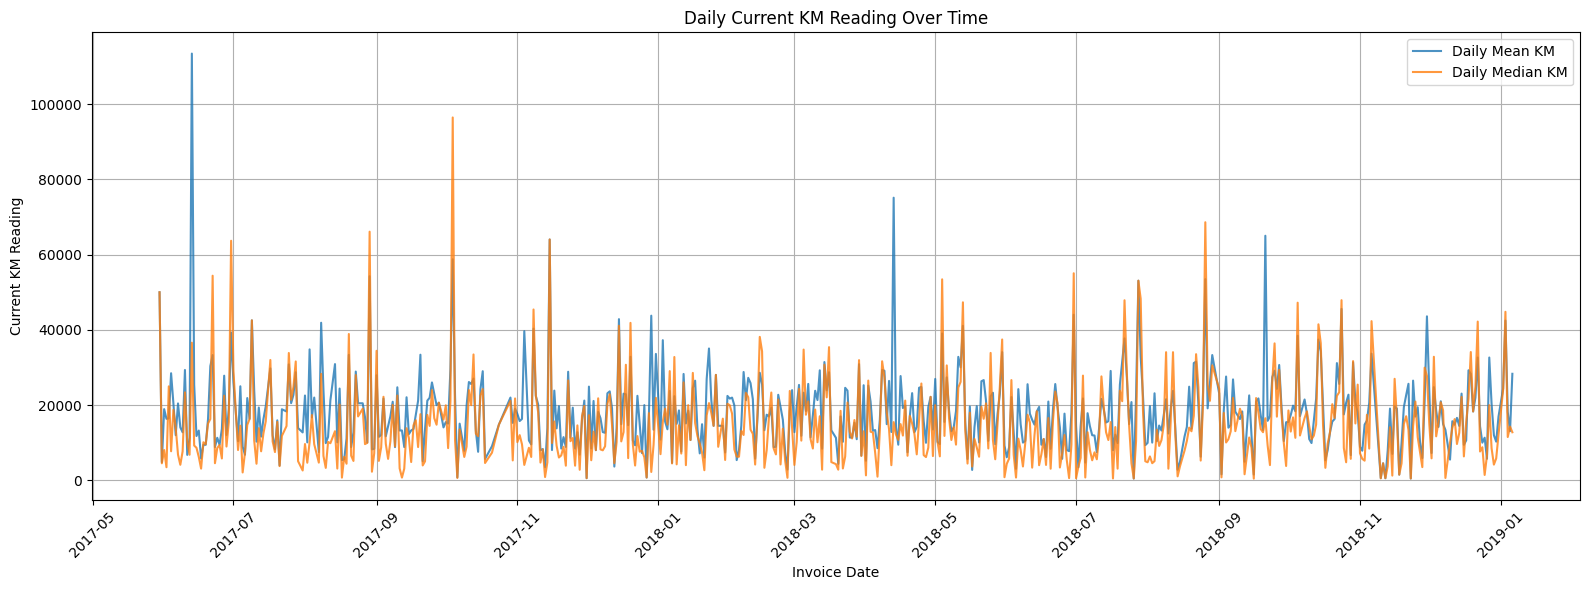

In [86]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.plot(
    daily_km.index,
    daily_km['mean'],
    label='Daily Mean KM',
    alpha=0.8
)

plt.plot(
    daily_km.index,
    daily_km['median'],
    label='Daily Median KM',
    alpha=0.8
)

plt.title('Daily Current KM Reading Over Time')
plt.xlabel('Invoice Date')
plt.ylabel('Current KM Reading')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

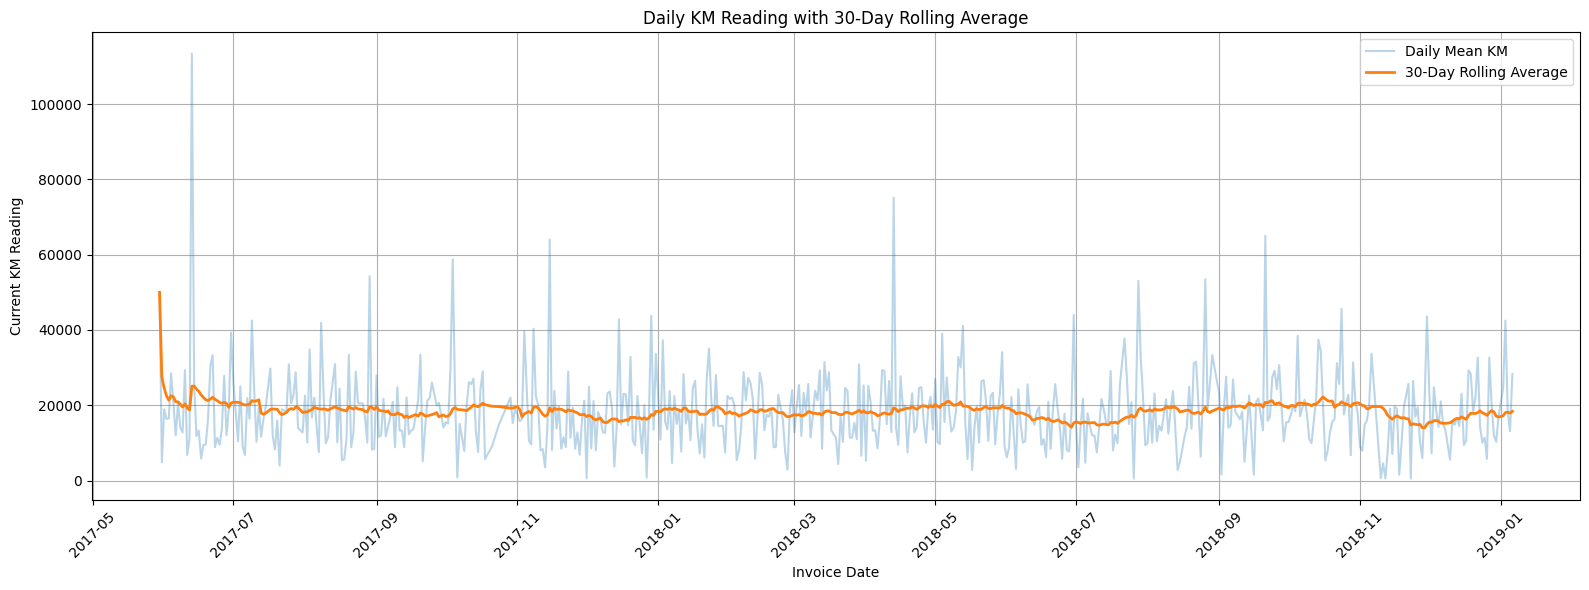

In [87]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_km.index,
    daily_km['mean'],
    alpha=0.3,
    label='Daily Mean KM'
)

plt.plot(
    daily_km.index,
    daily_km['mean'].rolling('30D').mean(),
    linewidth=2,
    label='30-Day Rolling Average'
)

plt.title('Daily KM Reading with 30-Day Rolling Average')
plt.xlabel('Invoice Date')
plt.ylabel('Current KM Reading')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

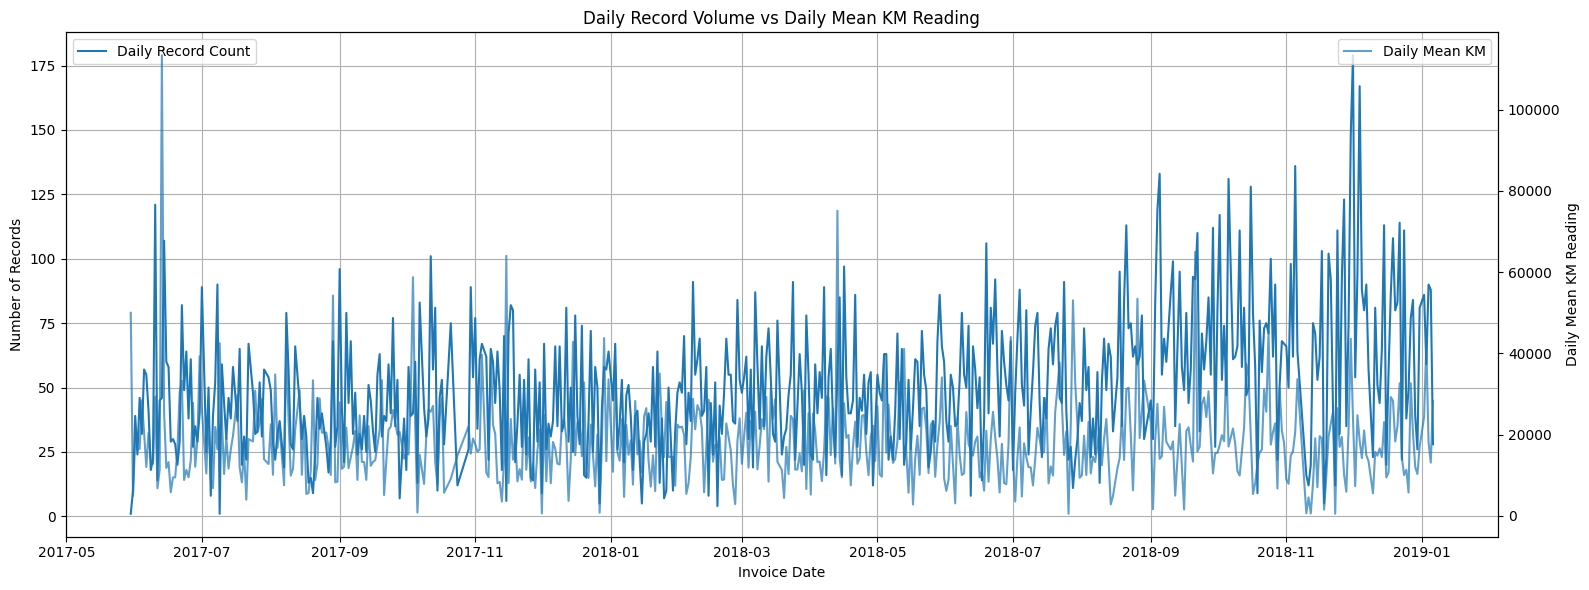

In [88]:
fig, ax1 = plt.subplots(figsize=(16, 6))

# Daily number of records
ax1.plot(
    daily_km.index,
    daily_km['count'],
    label='Daily Record Count'
)

ax1.set_xlabel('Invoice Date')
ax1.set_ylabel('Number of Records')
ax1.grid(True)

# Daily mean KM on a second axis
ax2 = ax1.twinx()

ax2.plot(
    daily_km.index,
    daily_km['mean'],
    label='Daily Mean KM',
    alpha=0.7
)

ax2.set_ylabel('Daily Mean KM Reading')

plt.title('Daily Record Volume vs Daily Mean KM Reading')

ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [89]:
# Calculate correlation between daily record count and daily mean KM
correlation = daily_km['count'].corr(daily_km['mean'])

print("Correlation between daily record count and daily mean KM:", correlation)

Correlation between daily record count and daily mean KM: 0.17194352381447722


In [90]:
# Create a complete daily time index
daily_mean_ts = daily_km['mean'].asfreq('D')

print("Total calendar days:", daily_mean_ts.shape[0])
print("Missing values in daily mean series:", daily_mean_ts.isna().sum())

print("\nMissing dates:")
print(daily_mean_ts[daily_mean_ts.isna()].index)

Total calendar days: 587
Missing values in daily mean series: 32

Missing dates:
DatetimeIndex(['2017-07-02', '2017-07-16', '2017-07-23', '2017-07-30',
               '2017-08-06', '2017-08-13', '2017-08-25', '2017-09-29',
               '2017-10-08', '2017-10-19', '2017-10-20', '2017-10-22',
               '2017-10-23', '2017-10-25', '2017-10-26', '2017-10-27',
               '2017-10-28', '2017-11-05', '2018-01-01', '2018-01-28',
               '2018-03-18', '2018-08-16', '2018-08-30', '2018-08-31',
               '2018-09-09', '2018-09-13', '2018-10-07', '2018-11-07',
               '2018-11-08', '2018-11-09', '2018-12-09', '2019-01-01'],
              dtype='datetime64[ns]', name='invoice_date', freq=None)


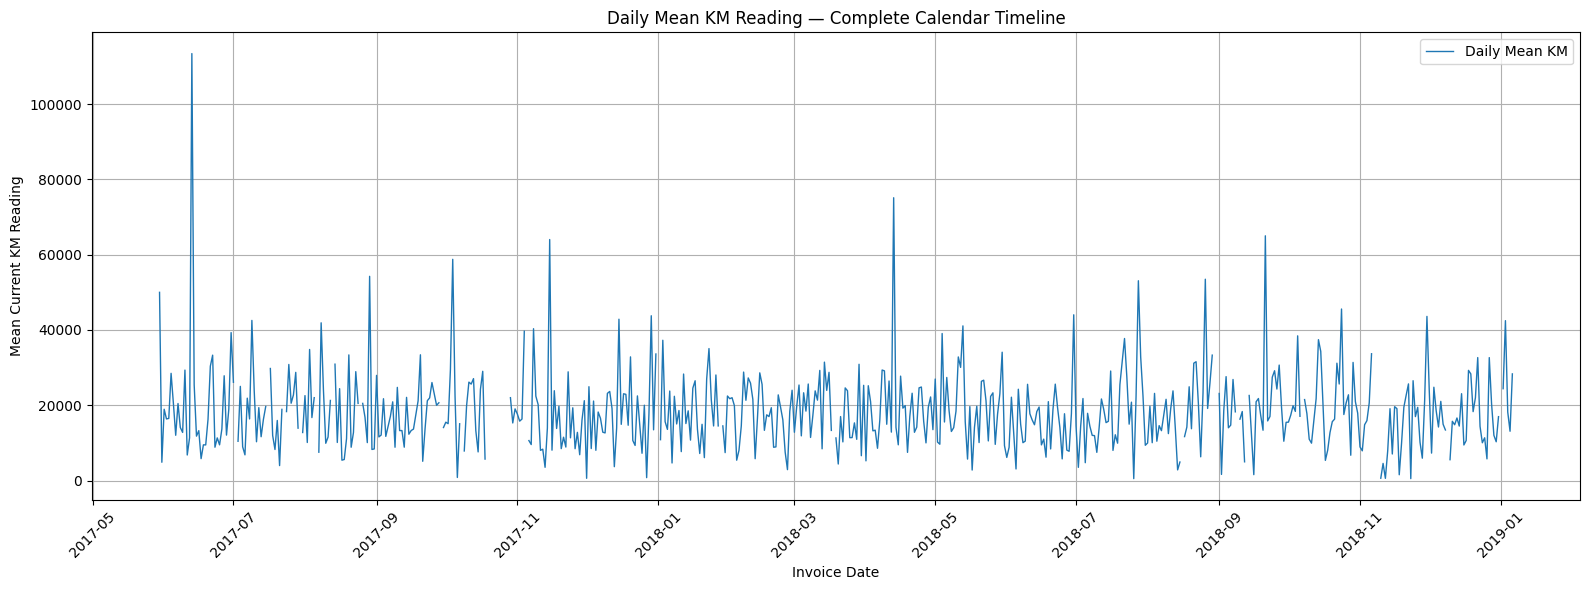

In [91]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_mean_ts.index,
    daily_mean_ts,
    label='Daily Mean KM',
    linewidth=1
)

plt.title('Daily Mean KM Reading — Complete Calendar Timeline')
plt.xlabel('Invoice Date')
plt.ylabel('Mean Current KM Reading')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [92]:
# Monthly aggregation of current KM readings
monthly_km = df_ts.groupby(
    df_ts['invoice_date'].dt.to_period('M')
)['current_km_reading'].agg(['mean', 'median', 'count'])

monthly_km.index = monthly_km.index.astype(str)

print("Monthly KM data shape:", monthly_km.shape)

print("\nMonthly KM readings:")
print(monthly_km)

Monthly KM data shape: (21, 3)

Monthly KM readings:
                      mean   median  count
invoice_date                              
2017-05        8966.545455   5391.0     11
2017-06       22205.385587  10399.0   1346
2017-07       18311.051783  13299.5   1178
2017-08       22193.588900  11130.0    973
2017-09       18551.383703  11724.0   1264
2017-10       20045.657495  12572.0   1054
2017-11       17518.183140  11193.0   1376
2017-12       18922.139777   9206.0   1345
2018-01       19064.884770  11806.0    998
2018-02       18544.909769  11247.0   1341
2018-03       18544.521505  13309.0   1488
2018-04       20405.096017  12000.0   1406
2018-05       20052.014503  13703.0   1448
2018-06       16520.582136   9706.0   1601
2018-07       17436.834194  10724.0   1550
2018-08       19549.686595  12180.0   1589
2018-09       20779.909000  14837.0   2000
2018-10       20107.616580  15565.0   2123
2018-11       19177.763483  12153.0   1780
2018-12       19228.767699  15380.0   2260
2

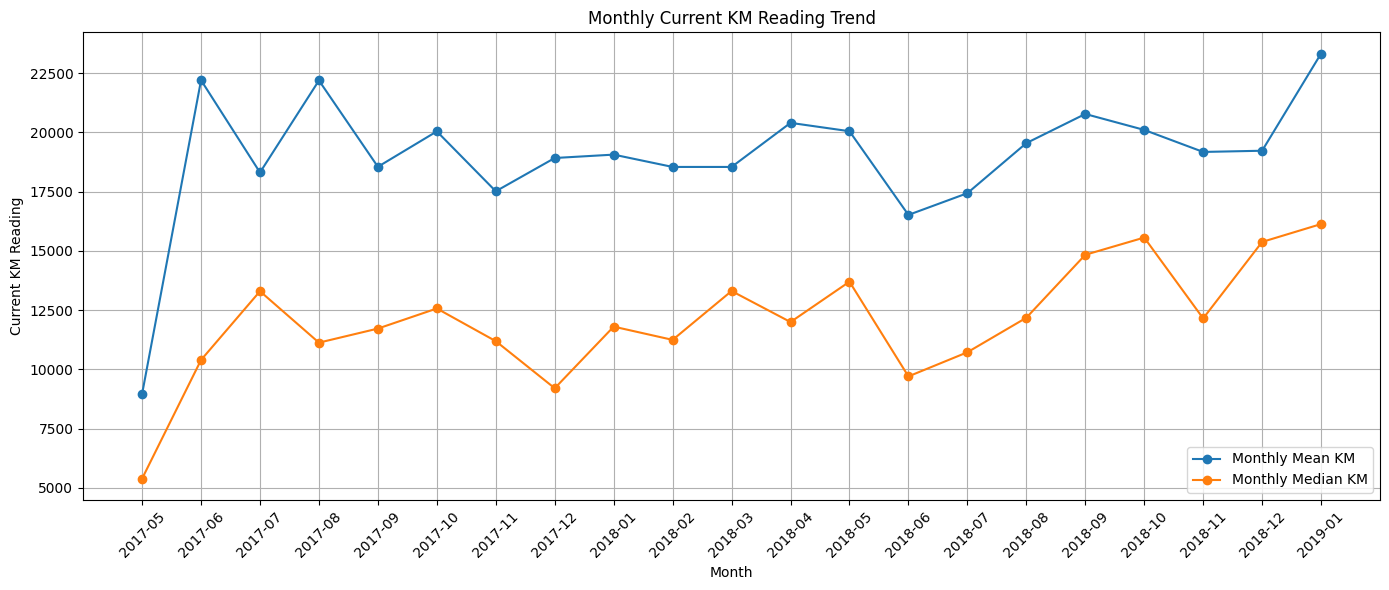

In [93]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_km.index,
    monthly_km['mean'],
    marker='o',
    label='Monthly Mean KM'
)

plt.plot(
    monthly_km.index,
    monthly_km['median'],
    marker='o',
    label='Monthly Median KM'
)

plt.title('Monthly Current KM Reading Trend')
plt.xlabel('Month')
plt.ylabel('Current KM Reading')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [94]:
from statsmodels.tsa.stattools import adfuller

# Use observed daily mean KM readings
adf_series = daily_km['mean'].dropna()

# Perform ADF test
adf_result = adfuller(adf_series)

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Number of Lags:", adf_result[2])
print("Number of Observations:", adf_result[3])

print("\nCritical Values:")
for key, value in adf_result[4].items():
    print(f"{key}: {value}")

ADF Statistic: -18.215708481341753
p-value: 2.3866411598180322e-30
Number of Lags: 1
Number of Observations: 553

Critical Values:
1%: -3.4422304958001386
5%: -2.866780664287393
10%: -2.5695611022893377


/tmp/ipykernel_482/2813530715.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(adf_series)


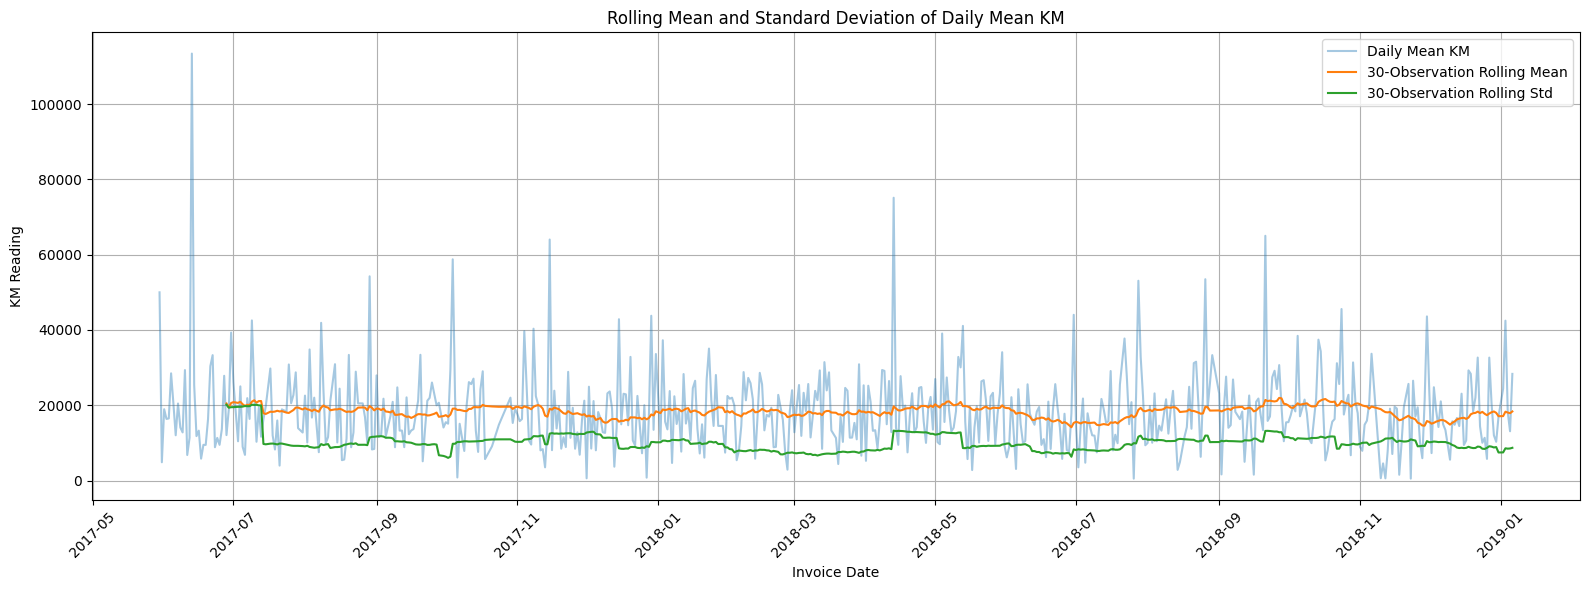

In [95]:
# Calculate rolling statistics
rolling_mean = adf_series.rolling(window=30).mean()
rolling_std = adf_series.rolling(window=30).std()

# Plot
plt.figure(figsize=(16, 6))

plt.plot(adf_series.index, adf_series, label='Daily Mean KM', alpha=0.4)
plt.plot(rolling_mean.index, rolling_mean, label='30-Observation Rolling Mean')
plt.plot(rolling_std.index, rolling_std, label='30-Observation Rolling Std')

plt.title('Rolling Mean and Standard Deviation of Daily Mean KM')
plt.xlabel('Invoice Date')
plt.ylabel('KM Reading')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [96]:
# Extract weekday from invoice_date
df_ts['weekday'] = df_ts['invoice_date'].dt.day_name()

# Calculate weekday statistics
weekday_km = df_ts.groupby('weekday')['current_km_reading'].agg(
    ['mean', 'median', 'std', 'count']
)

# Arrange weekdays in correct order
weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_km = weekday_km.reindex(weekday_order)

display(weekday_km.round(2))

,mean,median,std,count
weekday,,,,
Monday,18156.84,12180.0,18217.79,4141
Tuesday,19685.62,12684.0,29528.12,4808
Wednesday,20332.32,14478.0,21016.96,4038
Thursday,17385.43,10967.0,18233.80,3955
Friday,21939.43,11541.0,40229.08,3854
Saturday,19262.33,13555.0,20584.88,5612
Sunday,18186.05,10737.0,19926.74,2074


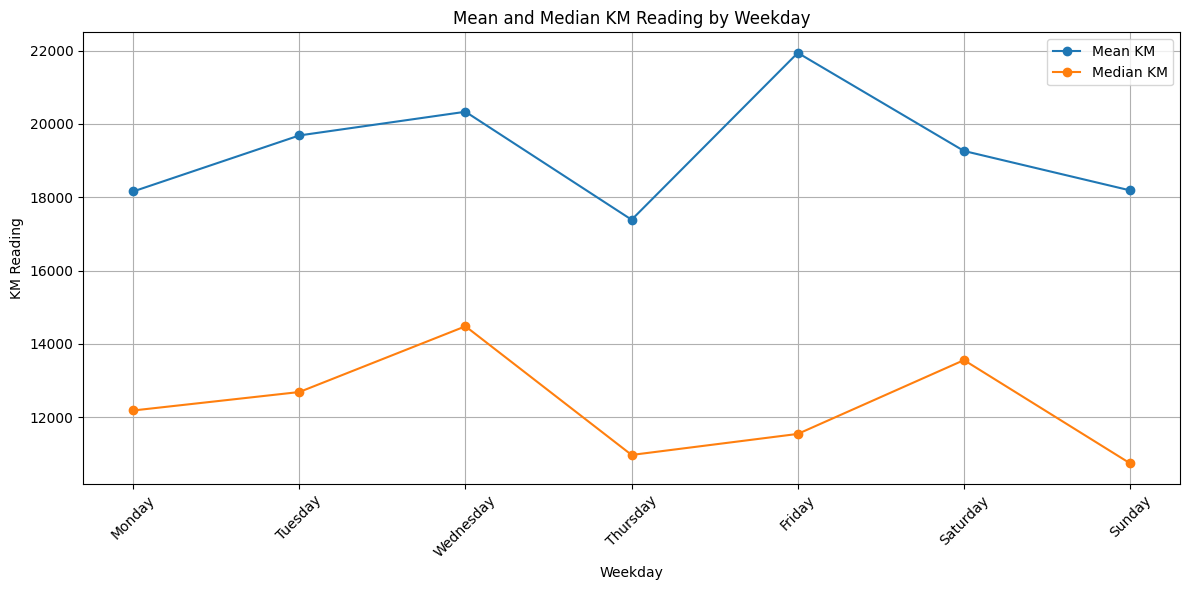

In [97]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(weekday_km.index, weekday_km['mean'], marker='o', label='Mean KM')
plt.plot(weekday_km.index, weekday_km['median'], marker='o', label='Median KM')

plt.title('Mean and Median KM Reading by Weekday')
plt.xlabel('Weekday')
plt.ylabel('KM Reading')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [98]:
# Calculate weekly average of daily mean KM readings
weekly_km = daily_km['mean'].resample('W').mean()

# Count observed days in each week
weekly_observed_days = daily_km['mean'].resample('W').count()

# Combine into a DataFrame
weekly_ts = pd.DataFrame({
    'weekly_mean_km': weekly_km,
    'observed_days': weekly_observed_days
})

display(weekly_ts.head(10))
print("Weekly dataset shape:", weekly_ts.shape)

,weekly_mean_km,observed_days
invoice_date,,
2017-06-04,22528.588442,6
2017-06-11,16573.585243,7
2017-06-18,27227.373164,7
2017-06-25,17018.195285,7
2017-07-02,22990.716916,6
2017-07-09,18866.782515,7
2017-07-16,16879.610650,6
2017-07-23,14809.433438,6
2017-07-30,22519.809772,6


Weekly dataset shape: (84, 2)


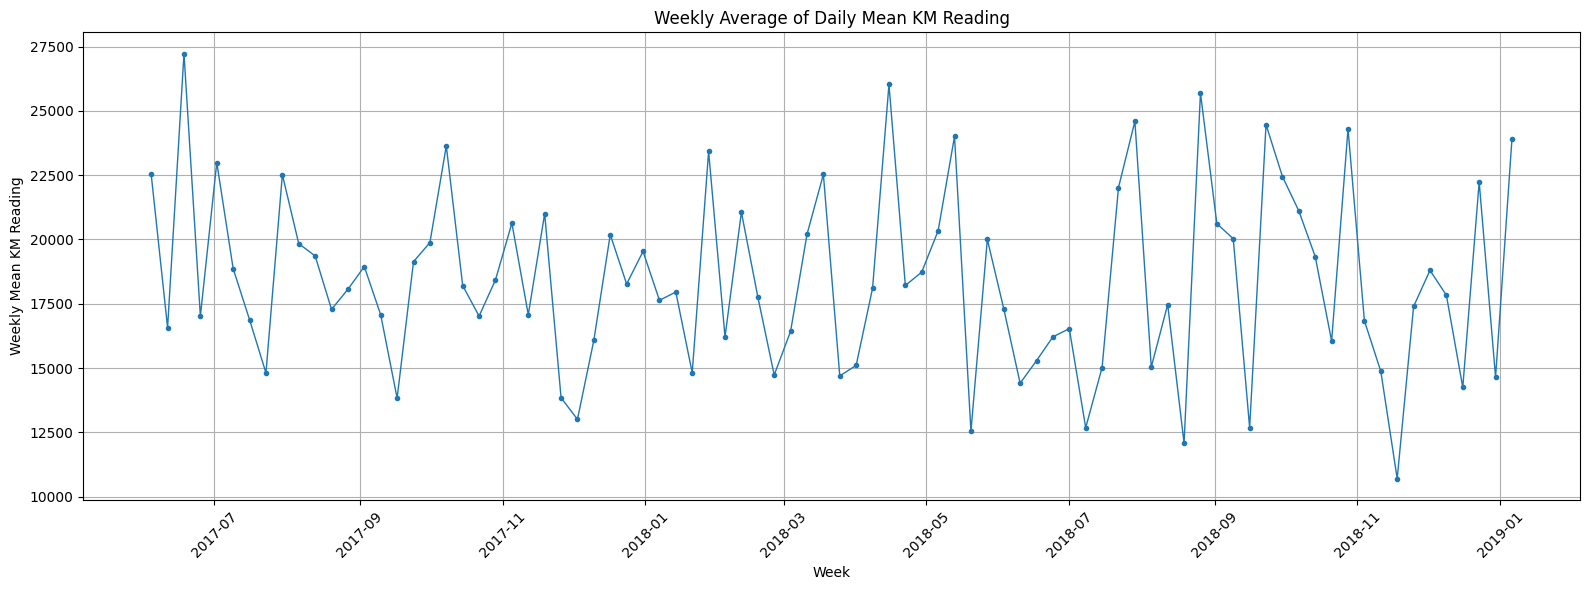

In [99]:
plt.figure(figsize=(16, 6))

plt.plot(
    weekly_ts.index,
    weekly_ts['weekly_mean_km'],
    marker='o',
    markersize=3,
    linewidth=1
)

plt.title('Weekly Average of Daily Mean KM Reading')
plt.xlabel('Week')
plt.ylabel('Weekly Mean KM Reading')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

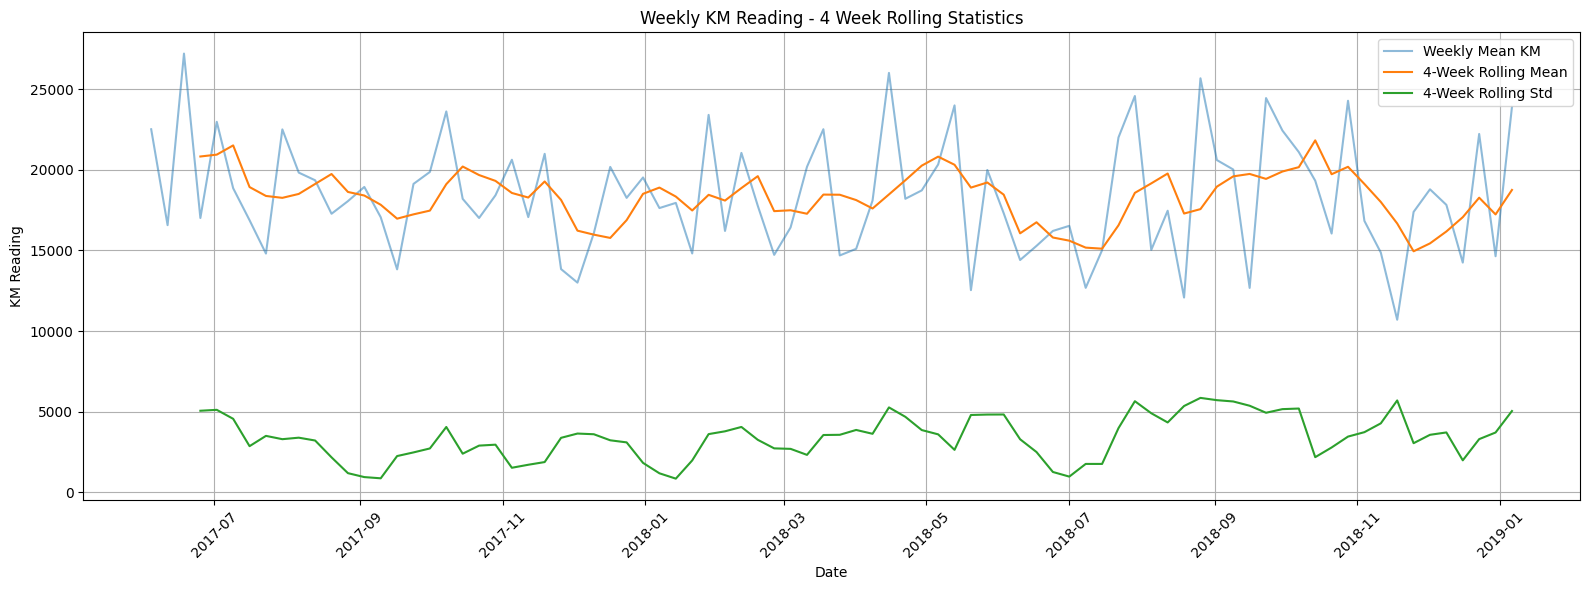

In [100]:
# Calculate 4-week rolling statistics
weekly_rolling_mean = weekly_ts['weekly_mean_km'].rolling(window=4).mean()
weekly_rolling_std = weekly_ts['weekly_mean_km'].rolling(window=4).std()

# Plot
plt.figure(figsize=(16, 6))

plt.plot(weekly_ts.index, weekly_ts['weekly_mean_km'],
         label='Weekly Mean KM', alpha=0.5)

plt.plot(weekly_ts.index, weekly_rolling_mean,
         label='4-Week Rolling Mean')

plt.plot(weekly_ts.index, weekly_rolling_std,
         label='4-Week Rolling Std')

plt.title('Weekly KM Reading - 4 Week Rolling Statistics')
plt.xlabel('Date')
plt.ylabel('KM Reading')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [101]:
from statsmodels.tsa.stattools import adfuller

# Prepare weekly series
weekly_adf_series = weekly_ts['weekly_mean_km'].dropna()

# Perform ADF test
weekly_adf_result = adfuller(weekly_adf_series)

print("Weekly ADF Statistic:", weekly_adf_result[0])
print("P-value:", weekly_adf_result[1])
print("Number of Lags:", weekly_adf_result[2])
print("Number of Observations:", weekly_adf_result[3])
print("\nCritical Values:")

for key, value in weekly_adf_result[4].items():
    print(f"{key}: {value}")

Weekly ADF Statistic: -4.128207967079948
P-value: 0.0008696110379140613
Number of Lags: 3
Number of Observations: 80

Critical Values:
1%: -3.5148692050781247
5%: -2.8984085156250003
10%: -2.58643890625


/tmp/ipykernel_482/504769554.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  weekly_adf_result = adfuller(weekly_adf_series)


<Figure size 1200x500 with 0 Axes>

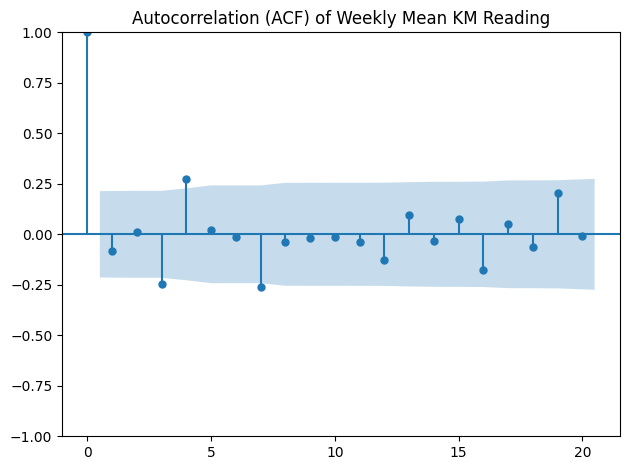

In [102]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plot_acf(
    weekly_adf_series,
    lags=20,
    alpha=0.05
)

plt.title('Autocorrelation (ACF) of Weekly Mean KM Reading')
plt.tight_layout()
plt.show()

<Figure size 1200x500 with 0 Axes>

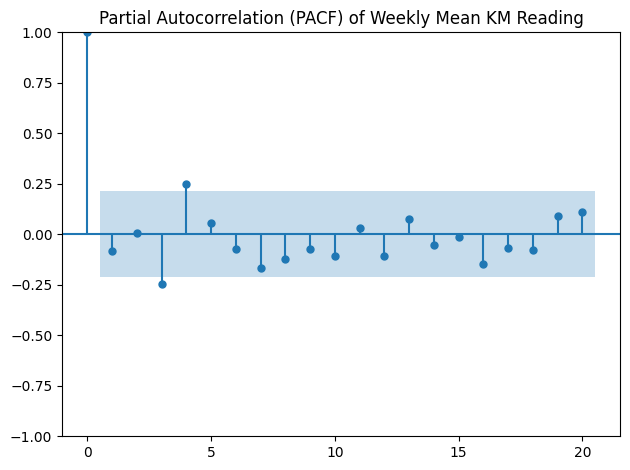

In [103]:
from statsmodels.graphics.tsaplots import plot_pacf
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plot_pacf(
    weekly_adf_series,
    lags=20,
    method='ywm',
    alpha=0.05
)

plt.title('Partial Autocorrelation (PACF) of Weekly Mean KM Reading')
plt.tight_layout()
plt.show()

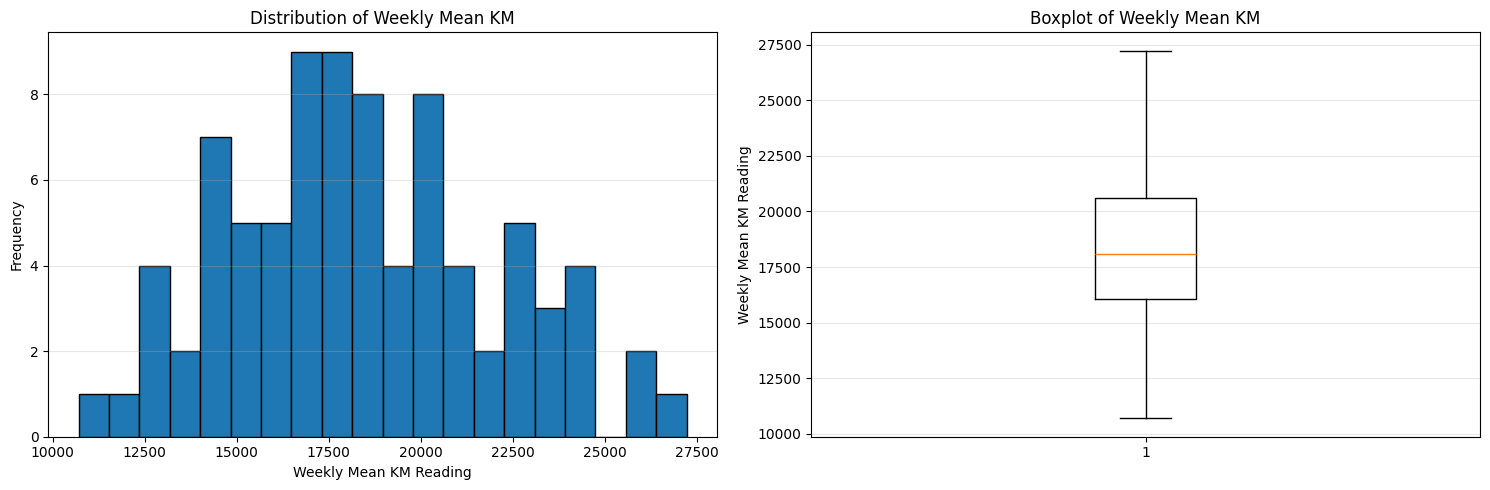

In [104]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram
axes[0].hist(weekly_adf_series, bins=20, edgecolor='black')
axes[0].set_title('Distribution of Weekly Mean KM')
axes[0].set_xlabel('Weekly Mean KM Reading')
axes[0].set_ylabel('Frequency')
axes[0].grid(axis='y', alpha=0.3)

# Boxplot
axes[1].boxplot(weekly_adf_series, vert=True)
axes[1].set_title('Boxplot of Weekly Mean KM')
axes[1].set_ylabel('Weekly Mean KM Reading')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [105]:
# Calculate weekly distribution statistics
Q1 = weekly_adf_series.quantile(0.25)
Q2 = weekly_adf_series.quantile(0.50)
Q3 = weekly_adf_series.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1 (25th percentile):", round(Q1, 2))
print("Median (50th percentile):", round(Q2, 2))
print("Q3 (75th percentile):", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))

# Identify potential outliers (analysis only; no removal)
potential_outliers = weekly_adf_series[
    (weekly_adf_series < lower_bound) |
    (weekly_adf_series > upper_bound)
]

print("\nPotential outlier count:", len(potential_outliers))
display(potential_outliers)

Q1 (25th percentile): 16073.12
Median (50th percentile): 18084.0
Q3 (75th percentile): 20619.94
IQR: 4546.82
Lower Bound: 9252.89
Upper Bound: 27440.17

Potential outlier count: 0


,weekly_mean_km
invoice_date,


In [106]:
from scipy.stats import skew, kurtosis

weekly_skewness = skew(weekly_adf_series)
weekly_kurtosis = kurtosis(weekly_adf_series)

print("Weekly Skewness:", round(weekly_skewness, 4))
print("Weekly Excess Kurtosis:", round(weekly_kurtosis, 4))

Weekly Skewness: 0.278
Weekly Excess Kurtosis: -0.4468


In [107]:
import numpy as np

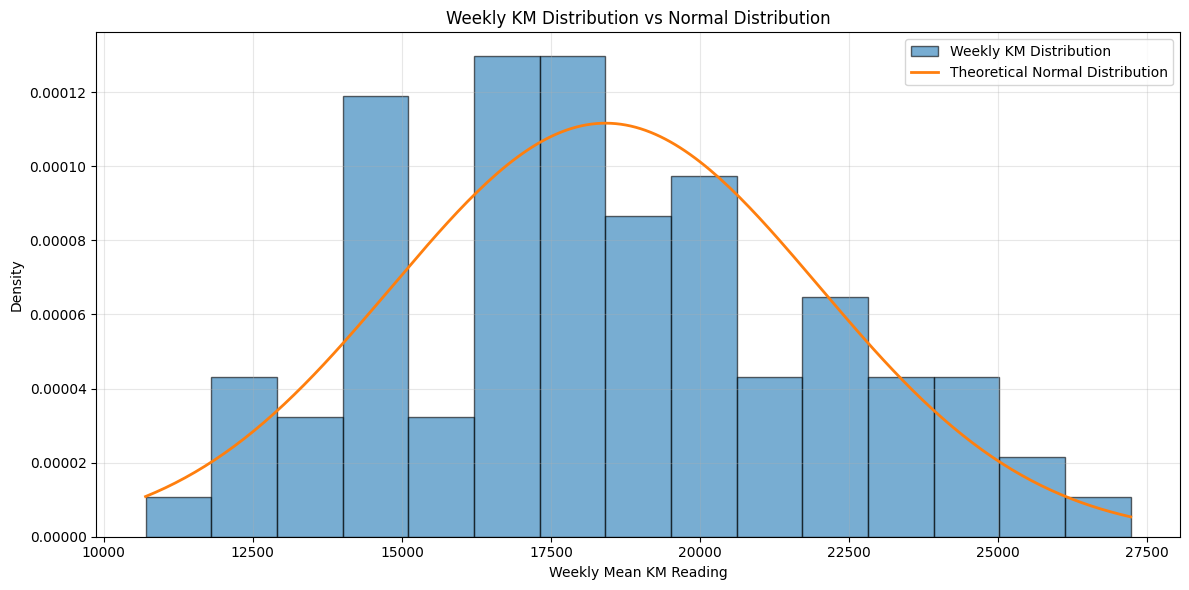

In [108]:
import matplotlib.pyplot as plt
from scipy.stats import norm

# Calculate weekly mean and standard deviation
weekly_mean = weekly_adf_series.mean()
weekly_std = weekly_adf_series.std()

# Plot histogram
plt.figure(figsize=(12, 6))

plt.hist(
    weekly_adf_series,
    bins=15,
    density=True,
    alpha=0.6,
    edgecolor='black',
    label='Weekly KM Distribution'
)

# Generate theoretical normal curve
x = np.linspace(
    weekly_adf_series.min(),
    weekly_adf_series.max(),
    200
)

y = norm.pdf(x, weekly_mean, weekly_std)

plt.plot(x, y, label='Theoretical Normal Distribution', linewidth=2)

plt.title('Weekly KM Distribution vs Normal Distribution')
plt.xlabel('Weekly Mean KM Reading')
plt.ylabel('Density')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

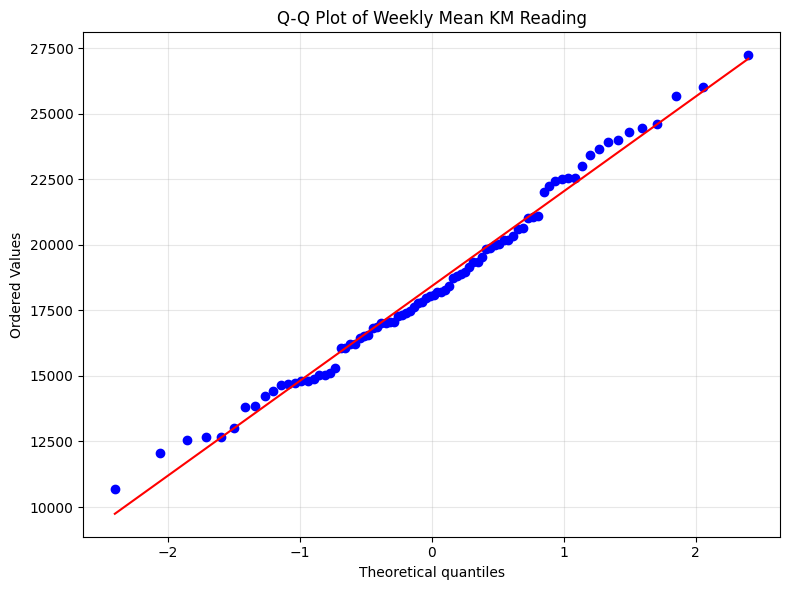

In [109]:
import matplotlib.pyplot as plt
import scipy.stats as stats

plt.figure(figsize=(8, 6))

stats.probplot(
    weekly_adf_series,
    dist="norm",
    plot=plt
)

plt.title('Q-Q Plot of Weekly Mean KM Reading')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [110]:
# Analyze weekly data coverage
print("Weekly Observed Days Distribution:")
display(weekly_ts['observed_days'].value_counts().sort_index())

print("\nMinimum observed days in a week:",
      weekly_ts['observed_days'].min())

print("Maximum observed days in a week:",
      weekly_ts['observed_days'].max())

print("Average observed days per week:",
      round(weekly_ts['observed_days'].mean(), 2))

print("\nWeeks with fewer than 7 observed days:",
      (weekly_ts['observed_days'] < 7).sum())

print("Weeks with all 7 observed days:",
      (weekly_ts['observed_days'] == 7).sum())

Weekly Observed Days Distribution:


,count
observed_days,
2,1
4,2
5,1
6,20
7,60



Minimum observed days in a week: 2
Maximum observed days in a week: 7
Average observed days per week: 6.61

Weeks with fewer than 7 observed days: 24
Weeks with all 7 observed days: 60


The weekly time series has 84 observations, with an average of 6.61 observed days per week. Sixty weeks have complete seven-day coverage, while 24 weeks contain missing dates. Weekly aggregation improves readability, but incomplete weekly coverage may affect the reliability and comparability of some weekly mean values.

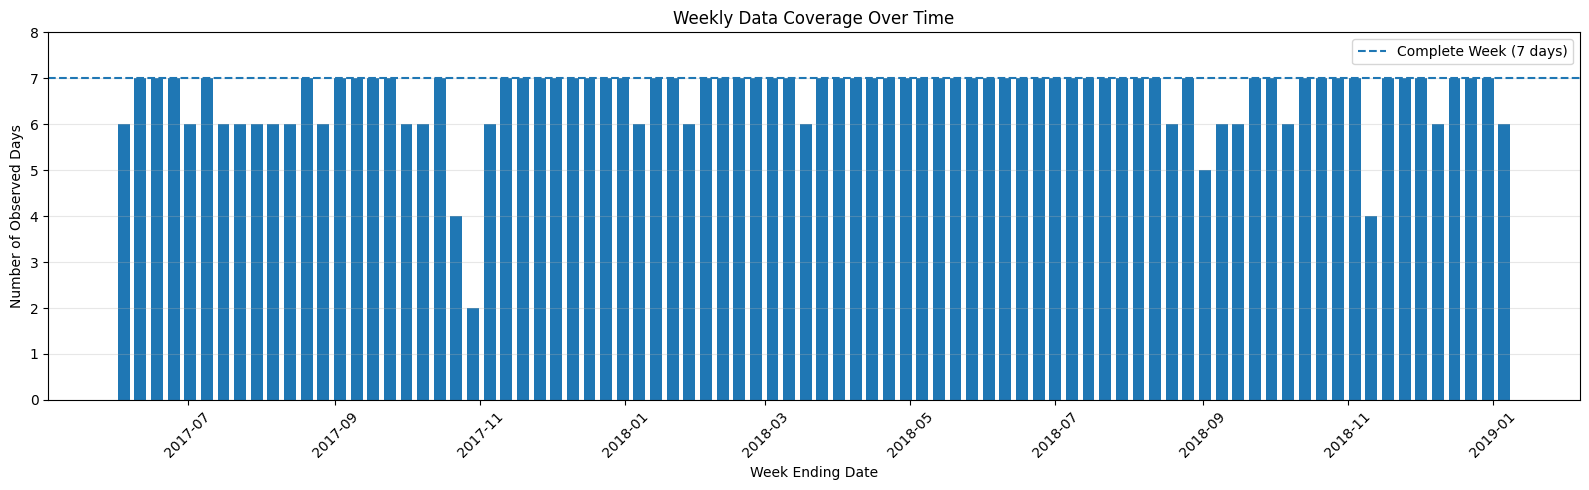

In [111]:
plt.figure(figsize=(16, 5))

plt.bar(
    weekly_ts.index,
    weekly_ts['observed_days'],
    width=5
)

plt.axhline(y=7, linestyle='--', label='Complete Week (7 days)')

plt.title('Weekly Data Coverage Over Time')
plt.xlabel('Week Ending Date')
plt.ylabel('Number of Observed Days')
plt.ylim(0, 8)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [112]:
# Find weeks with fewer than 6 observed days
low_coverage_weeks = weekly_ts[
    weekly_ts['observed_days'] < 6
].sort_values('observed_days')

display(low_coverage_weeks)

print("Number of low-coverage weeks:", len(low_coverage_weeks))

,weekly_mean_km,observed_days
invoice_date,,
2017-10-29,18428.673077,2
2017-10-22,17018.347054,4
2018-11-11,14872.046415,4
2018-09-02,20615.199785,5


Number of low-coverage weeks: 4


In [113]:
# Calculate total invoice records per week
weekly_record_count = daily_km['count'].resample('W').sum()

# Combine weekly KM and weekly record counts
weekly_analysis = weekly_ts.copy()

weekly_analysis['weekly_record_count'] = weekly_record_count

display(weekly_analysis.head(10))

,weekly_mean_km,observed_days,weekly_record_count
invoice_date,,,
2017-06-04,22528.588442,6,152
2017-06-11,16573.585243,7,328
2017-06-18,27227.373164,7,375
2017-06-25,17018.195285,7,310
2017-07-02,22990.716916,6,281
2017-07-09,18866.782515,7,265
2017-07-16,16879.610650,6,275
2017-07-23,14809.433438,6,242
2017-07-30,22519.809772,6,253


In [114]:
# Calculate correlation
pearson_corr = weekly_analysis['weekly_record_count'].corr(
    weekly_analysis['weekly_mean_km'], method='pearson'
)

spearman_corr = weekly_analysis['weekly_record_count'].corr(
    weekly_analysis['weekly_mean_km'], method='spearman'
)

print("Pearson Correlation:", round(pearson_corr, 4))
print("Spearman Correlation:", round(spearman_corr, 4))

Pearson Correlation: 0.1212
Spearman Correlation: 0.0829


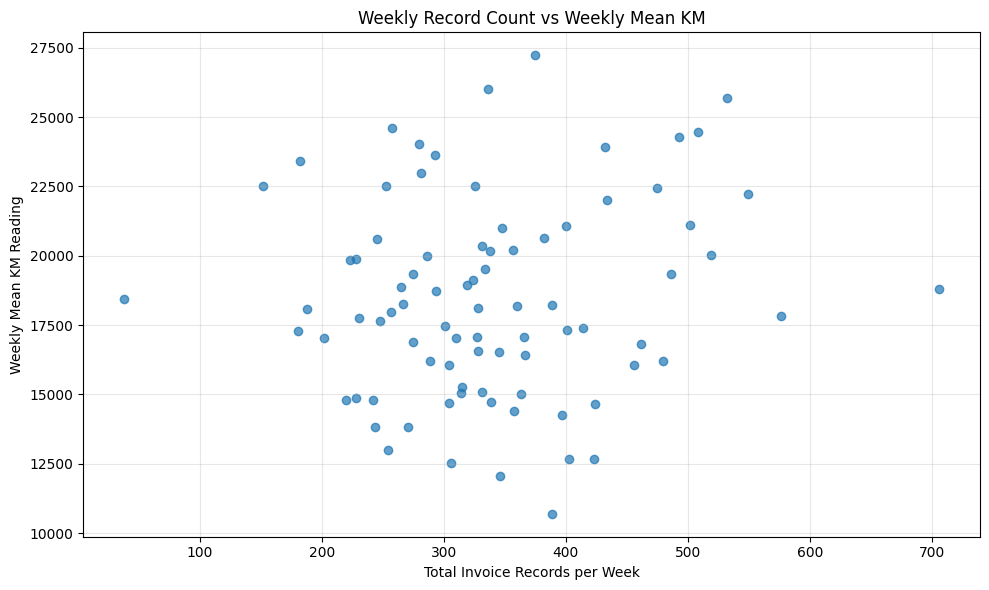

In [115]:
plt.figure(figsize=(10, 6))

plt.scatter(
    weekly_analysis['weekly_record_count'],
    weekly_analysis['weekly_mean_km'],
    alpha=0.7
)

plt.title('Weekly Record Count vs Weekly Mean KM')
plt.xlabel('Total Invoice Records per Week')
plt.ylabel('Weekly Mean KM Reading')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [116]:
# Correlation between weekly data coverage and weekly mean KM
coverage_corr = weekly_analysis['observed_days'].corr(
    weekly_analysis['weekly_mean_km'],
    method='pearson'
)

print("Correlation (Observed Days vs Weekly Mean KM):",
      round(coverage_corr, 4))

Correlation (Observed Days vs Weekly Mean KM): -0.0569


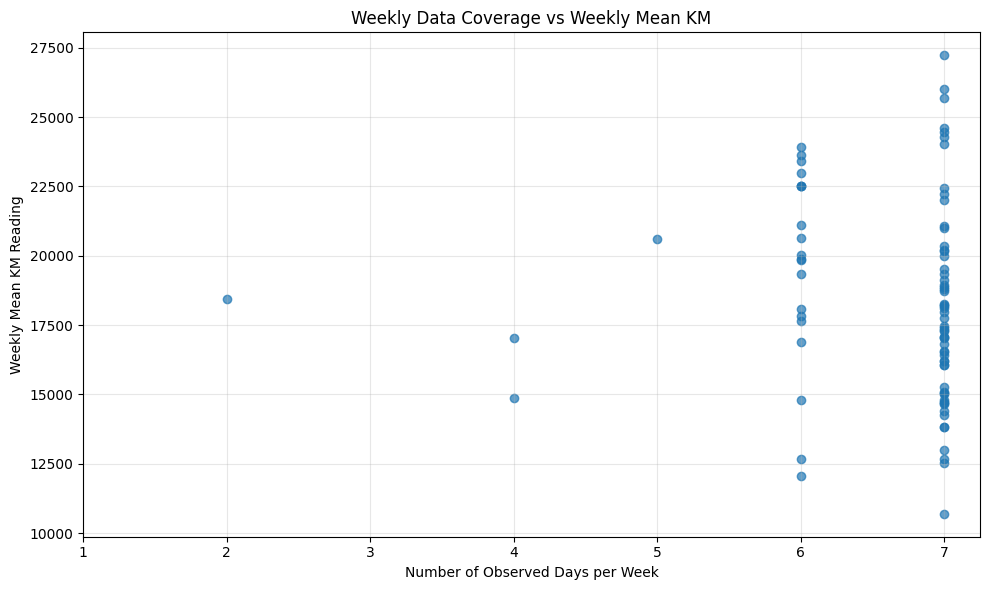

In [117]:
plt.figure(figsize=(10, 6))

plt.scatter(
    weekly_analysis['observed_days'],
    weekly_analysis['weekly_mean_km'],
    alpha=0.7
)

plt.title('Weekly Data Coverage vs Weekly Mean KM')
plt.xlabel('Number of Observed Days per Week')
plt.ylabel('Weekly Mean KM Reading')
plt.xticks(range(1, 8))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [118]:
# Calculate week-to-week change
weekly_analysis['weekly_change'] = weekly_analysis['weekly_mean_km'].diff()

# Calculate percentage change
weekly_analysis['weekly_pct_change'] = (
    weekly_analysis['weekly_mean_km'].pct_change() * 100
)

print("Week-to-Week Change Statistics:")
display(weekly_analysis['weekly_change'].describe())

print("\nPercentage Change Statistics:")
display(weekly_analysis['weekly_pct_change'].describe())

Week-to-Week Change Statistics:


,weekly_change
count,83.000000
mean,16.689007
std,5242.299032
min,-11472.379174
25%,-3260.100048
50%,-476.677413
75%,3037.302114
max,13614.040850



Percentage Change Statistics:


,weekly_pct_change
count,83.000000
mean,4.295228
std,31.402148
min,-47.780279
25%,-17.186846
50%,-2.403006
75%,18.674407
max,112.714935


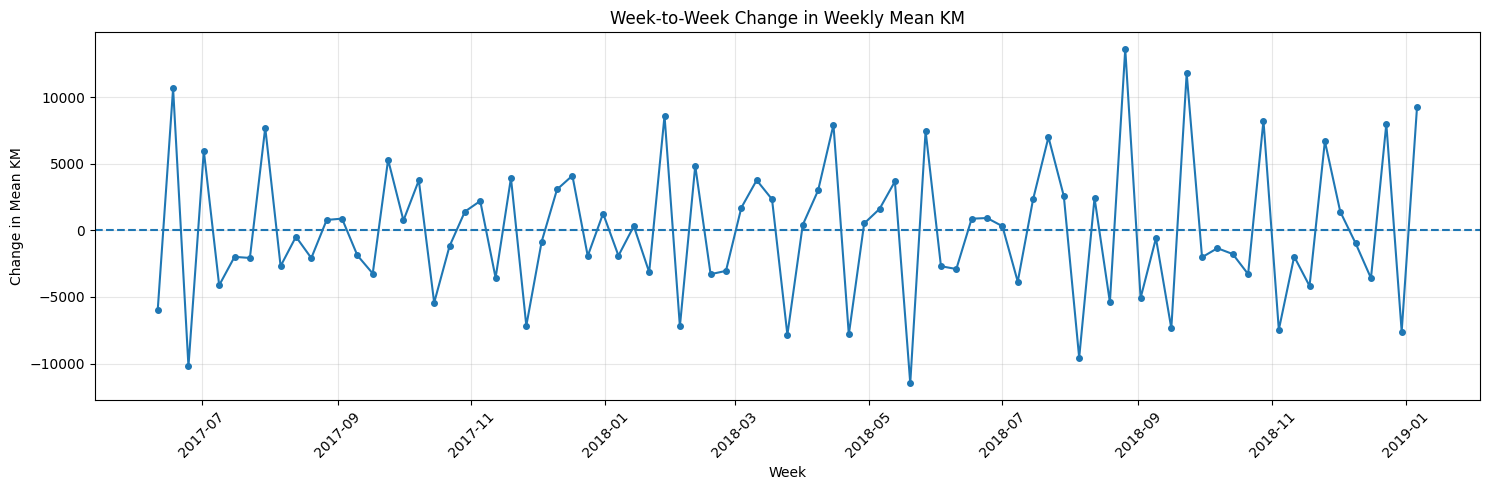

In [119]:
plt.figure(figsize=(15, 5))

plt.plot(
    weekly_analysis.index,
    weekly_analysis['weekly_change'],
    marker='o',
    markersize=4
)

plt.axhline(y=0, linestyle='--')

plt.title('Week-to-Week Change in Weekly Mean KM')
plt.xlabel('Week')
plt.ylabel('Change in Mean KM')
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [120]:
# Count weekly increases, decreases, and unchanged values
increase_weeks = (weekly_analysis['weekly_change'] > 0).sum()
decrease_weeks = (weekly_analysis['weekly_change'] < 0).sum()
unchanged_weeks = (weekly_analysis['weekly_change'] == 0).sum()

total_changes = weekly_analysis['weekly_change'].dropna().count()

print("Weekly Increases:", increase_weeks)
print("Weekly Decreases:", decrease_weeks)
print("Unchanged Weeks:", unchanged_weeks)
print("Total Week-to-Week Comparisons:", total_changes)

print("\nIncrease Percentage:", round(increase_weeks / total_changes * 100, 2), "%")
print("Decrease Percentage:", round(decrease_weeks / total_changes * 100, 2), "%")

Weekly Increases: 41
Weekly Decreases: 42
Unchanged Weeks: 0
Total Week-to-Week Comparisons: 83

Increase Percentage: 49.4 %
Decrease Percentage: 50.6 %


In [121]:
# Method 1: Mean of daily means (our existing method)
weekly_mean_daily = daily_km['mean'].resample('W').mean()

# Method 2: Direct mean of all original records within each week
weekly_mean_direct = df_ts.set_index('invoice_date')['current_km_reading'].resample('W').mean()

# Compare both methods
aggregation_comparison = pd.DataFrame({
    'mean_of_daily_means': weekly_mean_daily,
    'direct_weekly_mean': weekly_mean_direct
})

aggregation_comparison['difference'] = (
    aggregation_comparison['direct_weekly_mean'] -
    aggregation_comparison['mean_of_daily_means']
)

display(aggregation_comparison.head(10))

print("Average absolute difference:",
      round(aggregation_comparison['difference'].abs().mean(), 2))

print("Maximum absolute difference:",
      round(aggregation_comparison['difference'].abs().max(), 2))

,mean_of_daily_means,direct_weekly_mean,difference
invoice_date,,,
2017-06-04,22528.588442,19086.914474,-3441.673968
2017-06-11,16573.585243,20884.945122,4311.359879
2017-06-18,27227.373164,27684.069333,456.696169
2017-06-25,17018.195285,18462.848387,1444.653102
2017-07-02,22990.716916,22971.153025,-19.563891
2017-07-09,18866.782515,16999.162264,-1867.620251
2017-07-16,16879.610650,17257.614545,378.003896
2017-07-23,14809.433438,16093.557851,1284.124414
2017-07-30,22519.809772,21390.434783,-1129.374989


Average absolute difference: 1548.65
Maximum absolute difference: 7169.02


In [122]:
# Absolute difference between the two aggregation methods
aggregation_comparison['absolute_difference'] = (
    aggregation_comparison['difference'].abs()
)

# Percentage difference relative to the direct weekly mean
aggregation_comparison['percentage_difference'] = (
    aggregation_comparison['absolute_difference'] /
    aggregation_comparison['direct_weekly_mean'] * 100
)

print("Absolute Difference Statistics:")
display(aggregation_comparison['absolute_difference'].describe())

print("\nPercentage Difference Statistics:")
display(aggregation_comparison['percentage_difference'].describe())

print("\nWeeks with difference greater than 2,000 KM:",
      (aggregation_comparison['absolute_difference'] > 2000).sum())

print("\nWeeks with difference greater than 10%:",
      (aggregation_comparison['percentage_difference'] > 10).sum())

Absolute Difference Statistics:


,absolute_difference
count,84.000000
mean,1548.650224
std,1444.786991
min,18.998903
25%,449.742367
50%,1206.749702
75%,1917.225964
max,7169.023760



Percentage Difference Statistics:


,percentage_difference
count,84.000000
mean,8.016333
std,7.136965
min,0.085167
25%,2.530954
50%,6.529067
75%,10.124502
max,33.461282



Weeks with difference greater than 2,000 KM: 20

Weeks with difference greater than 10%: 21


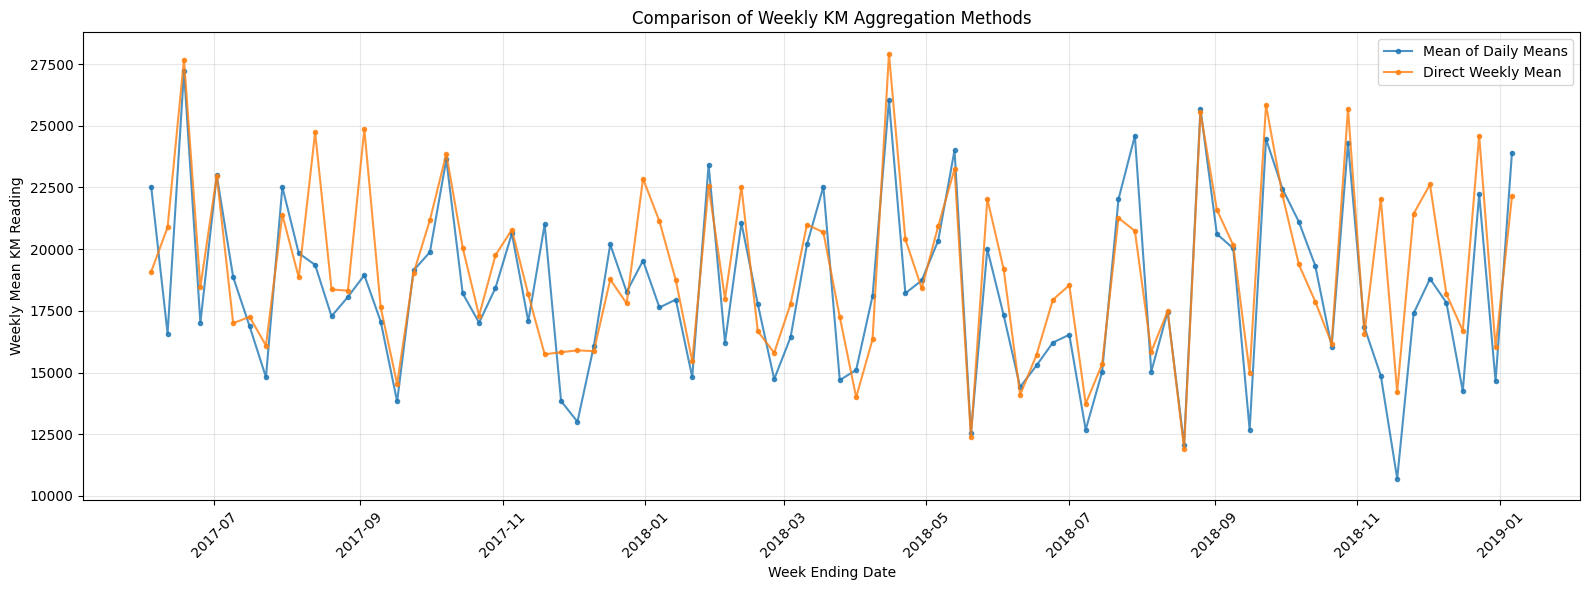

In [123]:
plt.figure(figsize=(16, 6))

plt.plot(
    aggregation_comparison.index,
    aggregation_comparison['mean_of_daily_means'],
    label='Mean of Daily Means',
    marker='o',
    markersize=3,
    alpha=0.8
)

plt.plot(
    aggregation_comparison.index,
    aggregation_comparison['direct_weekly_mean'],
    label='Direct Weekly Mean',
    marker='o',
    markersize=3,
    alpha=0.8
)

plt.title('Comparison of Weekly KM Aggregation Methods')
plt.xlabel('Week Ending Date')
plt.ylabel('Weekly Mean KM Reading')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [124]:
# Build final weekly analysis dataset using direct weekly aggregation

weekly_analysis_final = pd.DataFrame({
    'weekly_mean_km': weekly_mean_direct,
    'weekly_record_count': df_ts.set_index('invoice_date')['current_km_reading'].resample('W').count(),
    'observed_days': daily_km['mean'].resample('W').count()
})

print("Final Weekly Dataset Shape:", weekly_analysis_final.shape)

display(weekly_analysis_final.head(10))

print("\nMissing Values:")
print(weekly_analysis_final.isnull().sum())

Final Weekly Dataset Shape: (84, 3)


,weekly_mean_km,weekly_record_count,observed_days
invoice_date,,,
2017-06-04,19086.914474,152,6
2017-06-11,20884.945122,328,7
2017-06-18,27684.069333,375,7
2017-06-25,18462.848387,310,7
2017-07-02,22971.153025,281,6
2017-07-09,16999.162264,265,7
2017-07-16,17257.614545,275,6
2017-07-23,16093.557851,242,6
2017-07-30,21390.434783,253,6



Missing Values:
weekly_mean_km         0
weekly_record_count    0
observed_days          0
dtype: int64


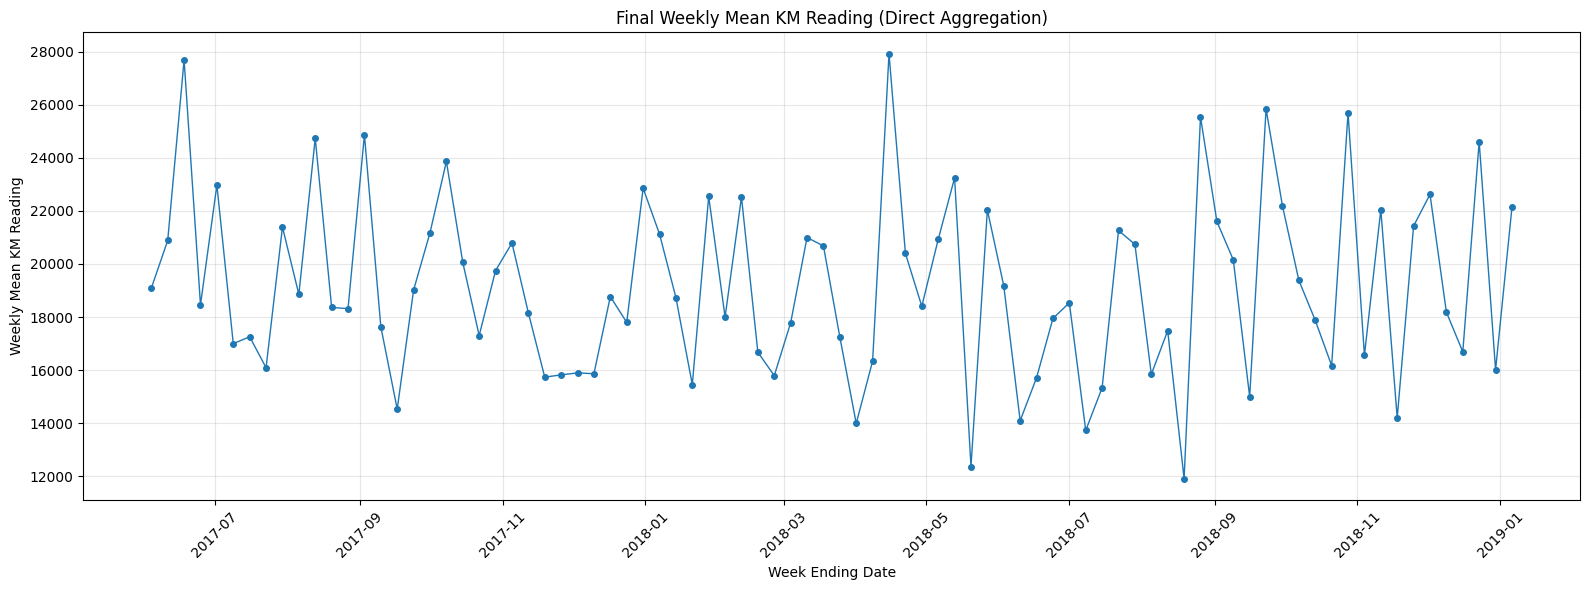

In [125]:
plt.figure(figsize=(16, 6))

plt.plot(
    weekly_analysis_final.index,
    weekly_analysis_final['weekly_mean_km'],
    marker='o',
    markersize=4,
    linewidth=1
)

plt.title('Final Weekly Mean KM Reading (Direct Aggregation)')
plt.xlabel('Week Ending Date')
plt.ylabel('Weekly Mean KM Reading')
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

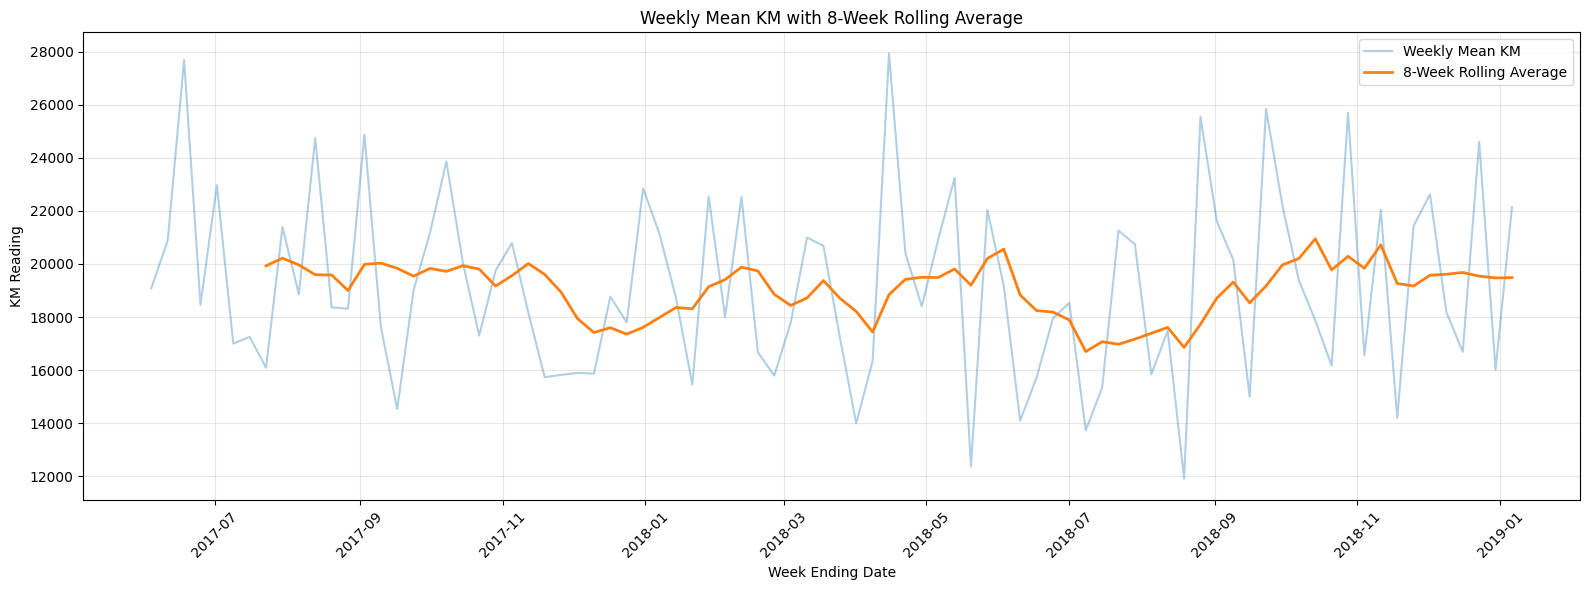

In [126]:
# Calculate 8-week rolling average
weekly_analysis_final['rolling_8_week_mean'] = (
    weekly_analysis_final['weekly_mean_km'].rolling(window=8).mean()
)

# Plot
plt.figure(figsize=(16, 6))

plt.plot(
    weekly_analysis_final.index,
    weekly_analysis_final['weekly_mean_km'],
    label='Weekly Mean KM',
    alpha=0.35
)

plt.plot(
    weekly_analysis_final.index,
    weekly_analysis_final['rolling_8_week_mean'],
    label='8-Week Rolling Average',
    linewidth=2
)

plt.title('Weekly Mean KM with 8-Week Rolling Average')
plt.xlabel('Week Ending Date')
plt.ylabel('KM Reading')
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

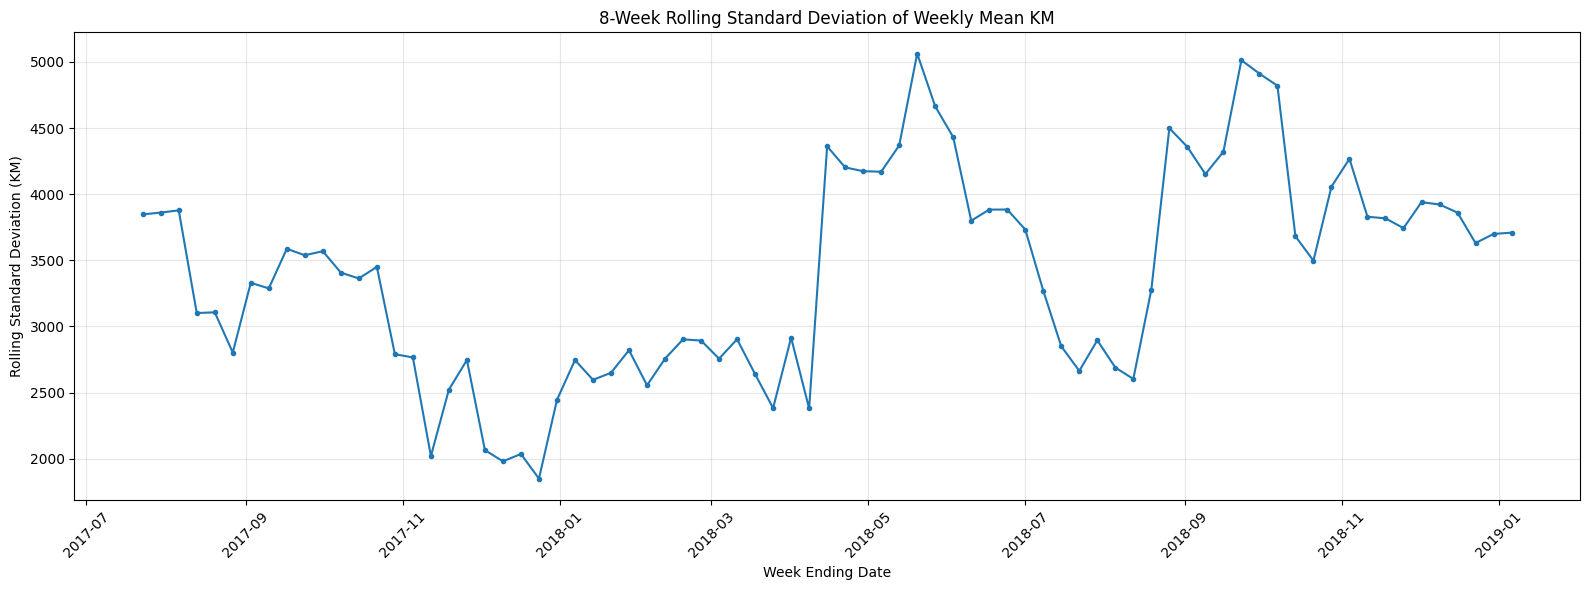

In [127]:
# Calculate 8-week rolling standard deviation
weekly_analysis_final['rolling_8_week_std'] = (
    weekly_analysis_final['weekly_mean_km'].rolling(window=8).std()
)

# Plot rolling volatility
plt.figure(figsize=(16, 6))

plt.plot(
    weekly_analysis_final.index,
    weekly_analysis_final['rolling_8_week_std'],
    marker='o',
    markersize=3
)

plt.title('8-Week Rolling Standard Deviation of Weekly Mean KM')
plt.xlabel('Week Ending Date')
plt.ylabel('Rolling Standard Deviation (KM)')
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

The 8-week rolling standard deviation indicates that the variability of weekly mean KM readings is not constant over time. Periods of relatively low volatility alternate with periods of higher volatility, suggesting changes in short-term variability across the series.

In [128]:
# Summary of 8-week rolling volatility
rolling_volatility = weekly_analysis_final['rolling_8_week_std'].dropna()

print("8-Week Rolling Volatility Summary")
print("Minimum:", round(rolling_volatility.min(), 2))
print("Maximum:", round(rolling_volatility.max(), 2))
print("Mean:", round(rolling_volatility.mean(), 2))
print("Median:", round(rolling_volatility.median(), 2))
print("Standard Deviation:", round(rolling_volatility.std(), 2))

8-Week Rolling Volatility Summary
Minimum: 1849.8
Maximum: 5062.71
Mean: 3402.15
Median: 3450.48
Standard Deviation: 783.04


In [129]:
!pip install pymannkendall

In [130]:
import pymannkendall as mk

# Perform Mann-Kendall trend test
mk_result = mk.original_test(weekly_adf_series)

print("Mann-Kendall Trend Test Results")
print("-" * 40)
print("Trend:", mk_result.trend)
print("H:", mk_result.h)
print("P-value:", mk_result.p)
print("Z-statistic:", mk_result.z)
print("Tau:", mk_result.Tau)
print("Sen's Slope:", mk_result.slope)
print("Intercept:", mk_result.intercept)

Mann-Kendall Trend Test Results
----------------------------------------
Trend: no trend
H: False
P-value: 0.4374653136790334
Z-statistic: -0.7764805278229759
Tau: -0.057946069994262765
Sen's Slope: -13.994756468174923
Intercept: 18664.780420061586


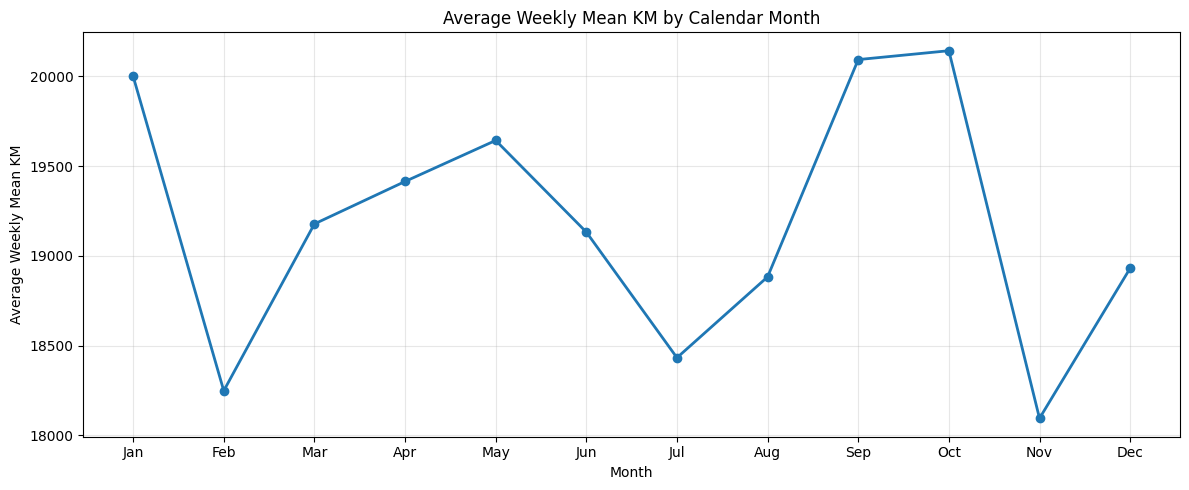

,weekly_mean_km
month,
1,20000.408800
2,18247.739961
3,19177.405933
4,19413.966489
5,19642.626308
6,19132.101927
7,18431.937645
8,18882.471356
9,20093.131278


In [131]:
# Extract month from weekly index
weekly_analysis_final['month'] = weekly_analysis_final.index.month

# Calculate average weekly KM for each calendar month
monthly_seasonality = weekly_analysis_final.groupby('month')['weekly_mean_km'].mean()

# Plot
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_seasonality.index,
    monthly_seasonality.values,
    marker='o',
    linewidth=2
)

plt.title('Average Weekly Mean KM by Calendar Month')
plt.xlabel('Month')
plt.ylabel('Average Weekly Mean KM')
plt.xticks(
    range(1, 13),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly_seasonality)

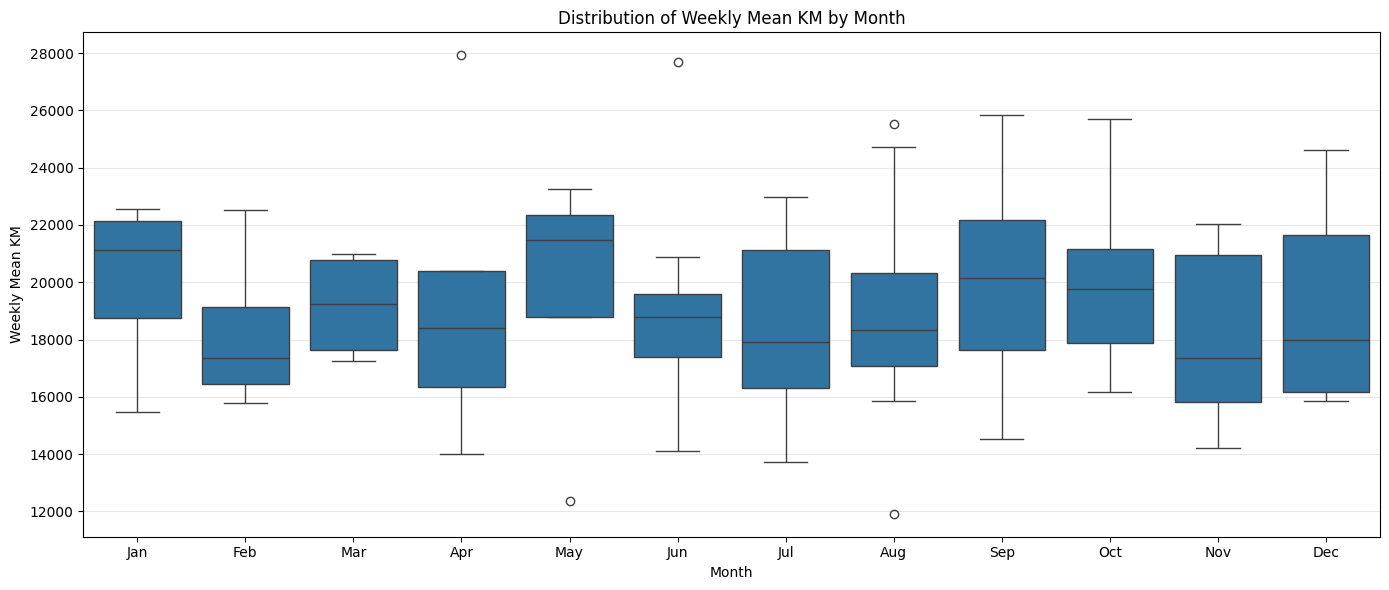

In [132]:
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=weekly_analysis_final,
    x='month',
    y='weekly_mean_km'
)

plt.title('Distribution of Weekly Mean KM by Month')
plt.xlabel('Month')
plt.ylabel('Weekly Mean KM')
plt.xticks(
    range(12),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Exploratory monthly analysis indicates fluctuations in weekly mean vehicle KM readings across calendar months. Although some months exhibit higher or lower averages and varying dispersion, no clear, consistent seasonal pattern is evident. Given the limited dataset duration of approximately 19 months, these observations are preliminary and insufficient to establish reliable annual seasonality.

In [133]:
monthly_week_counts = weekly_analysis_final.groupby('month')['weekly_mean_km'].agg(
    ['count', 'mean', 'median', 'std']
)

display(monthly_week_counts)

,count,mean,median,std
month,,,,
1,5,20000.408800,21128.612903,2938.747969
2,4,18247.739961,17337.108809,2988.712165
3,4,19177.405933,19231.741984,1934.498014
4,5,19413.966489,18405.547619,5319.746737
5,4,19642.626308,21479.757051,4941.277559
6,8,19132.101927,18774.881430,4054.783203
7,10,18431.937645,17897.660896,3041.750404
8,8,18882.471356,18340.938448,4454.661688
9,9,20093.131278,20156.726397,3976.247781


Monthly seasonality was explored using monthly averages and boxplots of weekly mean KM readings. The analysis revealed variations in both central tendency and dispersion across months. However, the dataset contains only approximately 19 months of observations, with some months having as few as four weekly observations. Therefore, the observed differences are insufficient to establish a reliable recurring annual seasonal pattern

<Figure size 1200x500 with 0 Axes>

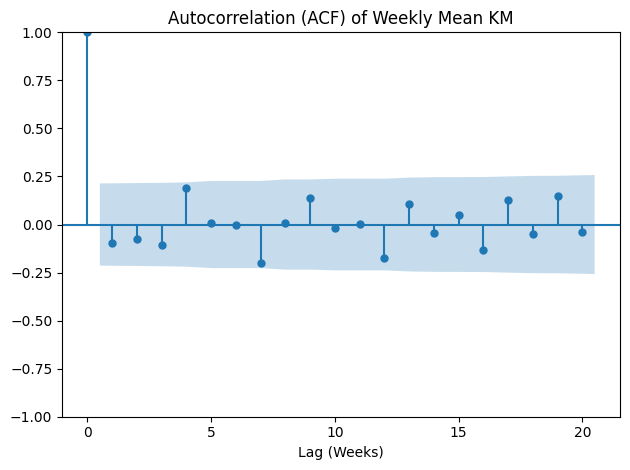

In [134]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plot_acf(
    weekly_analysis_final['weekly_mean_km'],
    lags=20
)

plt.title('Autocorrelation (ACF) of Weekly Mean KM')
plt.xlabel('Lag (Weeks)')
plt.tight_layout()
plt.show()

The Autocorrelation Function (ACF) plot of weekly mean KM readings was examined for lags up to 20 weeks. Most autocorrelation coefficients were small and remained within the confidence bounds, indicating no statistically significant autocorrelation at the examined lags. This suggests limited linear dependence between the weekly readings and their past values.

<Figure size 1200x500 with 0 Axes>

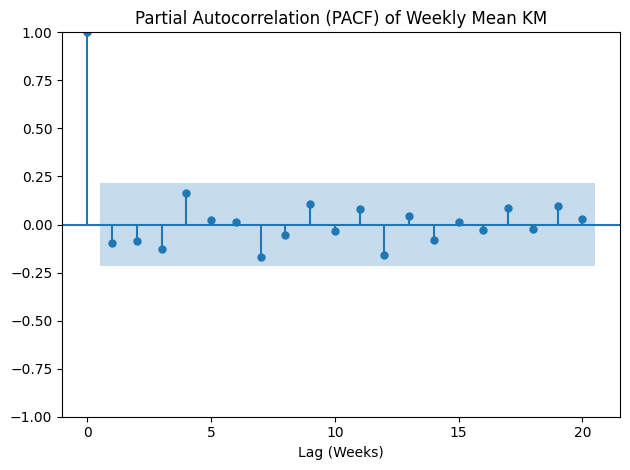

In [135]:
from statsmodels.graphics.tsaplots import plot_pacf
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plot_pacf(
    weekly_analysis_final['weekly_mean_km'],
    lags=20,
    method='ywm'
)

plt.title('Partial Autocorrelation (PACF) of Weekly Mean KM')
plt.xlabel('Lag (Weeks)')
plt.tight_layout()
plt.show()

In [136]:
from statsmodels.tsa.stattools import kpss

kpss_series = weekly_analysis_final['weekly_mean_km']

statistic, p_value, lags, critical_values = kpss(
    kpss_series,
    regression='c',
    nlags='auto'
)

print("KPSS Statistic:", statistic)
print("P-value:", p_value)
print("Lags Used:", lags)
print("Critical Values:", critical_values)


KPSS Statistic: 0.12835949610280634
P-value: 0.1
Lags Used: 4
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}


/tmp/ipykernel_482/329513462.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  statistic, p_value, lags, critical_values = kpss(
/tmp/ipykernel_482/329513462.py:5: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  statistic, p_value, lags, critical_values = kpss(


**The KPSS test was conducted on the weekly mean KM series. The test statistic was 0.12836, with a reported p-value of 0.10 (actual p-value greater than 0.10). Since the statistic was below the 10% critical value and the p-value exceeded 0.05, the null hypothesis of stationarity was not rejected. This provides evidence that the series is stationary around a constant mean, although it does not guarantee stationarity in every aspect.**

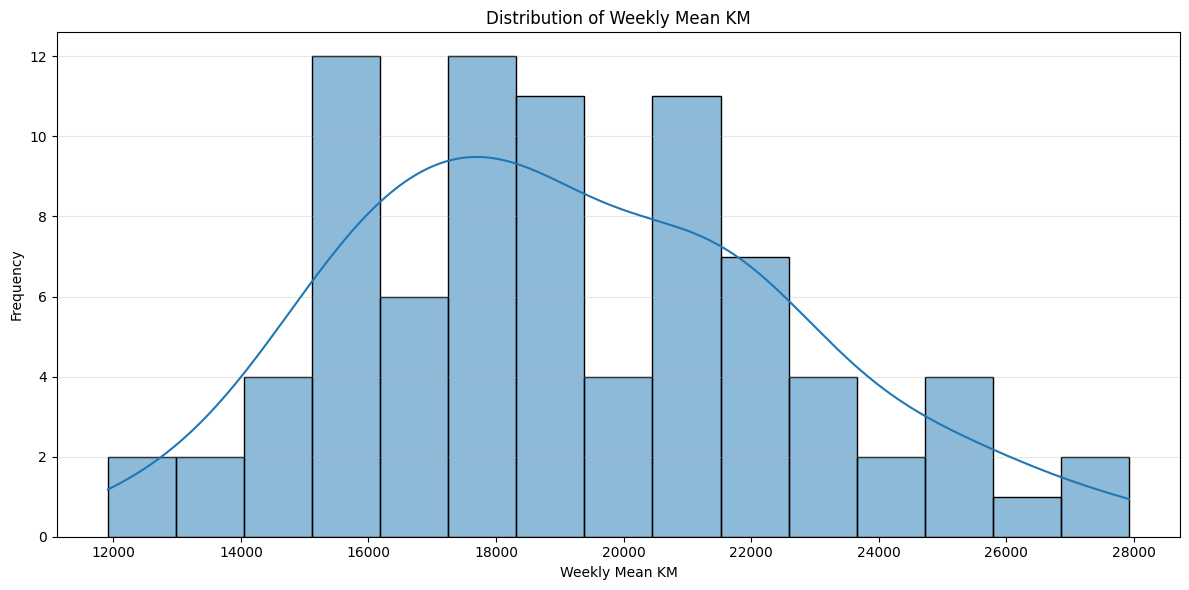

In [137]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

sns.histplot(
    weekly_analysis_final['weekly_mean_km'],
    bins=15,
    kde=True
)

plt.title('Distribution of Weekly Mean KM')
plt.xlabel('Weekly Mean KM')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [138]:
from scipy.stats import skew, kurtosis

series = weekly_analysis_final['weekly_mean_km']

print("Skewness:", skew(series))
print("Kurtosis:", kurtosis(series))


Skewness: 0.3587293157131462
Kurtosis: -0.29837871574830244


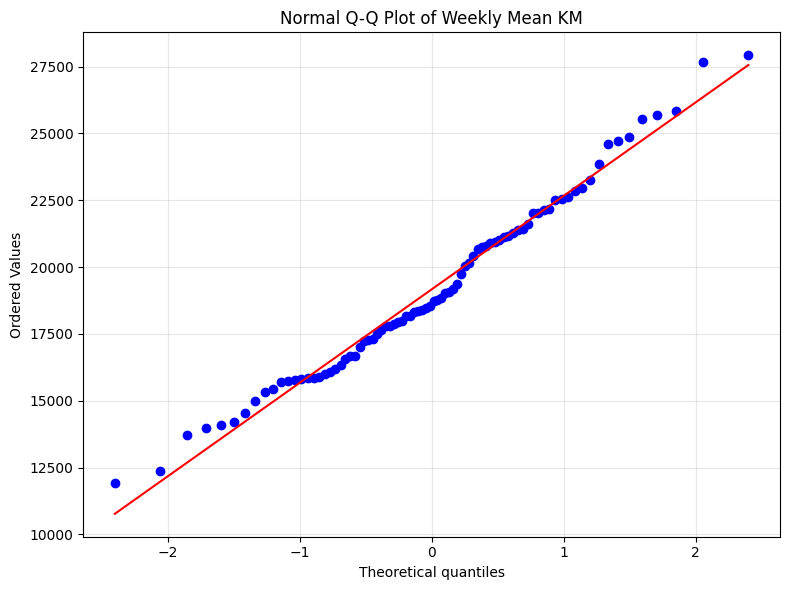

In [139]:
import scipy.stats as stats
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

stats.probplot(
    weekly_analysis_final['weekly_mean_km'],
    dist="norm",
    plot=plt
)

plt.title('Normal Q-Q Plot of Weekly Mean KM')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [140]:
from scipy.stats import shapiro

statistic, p_value = shapiro(
    weekly_analysis_final['weekly_mean_km']
)

print("Shapiro-Wilk Statistic:", statistic)
print("P-value:", p_value)

Shapiro-Wilk Statistic: 0.982538877868337
P-value: 0.31347602688483656


In [141]:
Q1 = weekly_analysis_final['weekly_mean_km'].quantile(0.25)
Q3 = weekly_analysis_final['weekly_mean_km'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = weekly_analysis_final[
    (weekly_analysis_final['weekly_mean_km'] < lower_bound) |
    (weekly_analysis_final['weekly_mean_km'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Potential Outliers:", len(outliers))
display(outliers)

Q1: 16509.51843126386
Q3: 21400.960144927536
IQR: 4891.441713663677
Lower Bound: 9172.355860768344
Upper Bound: 28738.12271542305
Number of Potential Outliers: 0


,weekly_mean_km,weekly_record_count,observed_days,rolling_8_week_mean,rolling_8_week_std,month
invoice_date,,,,,,


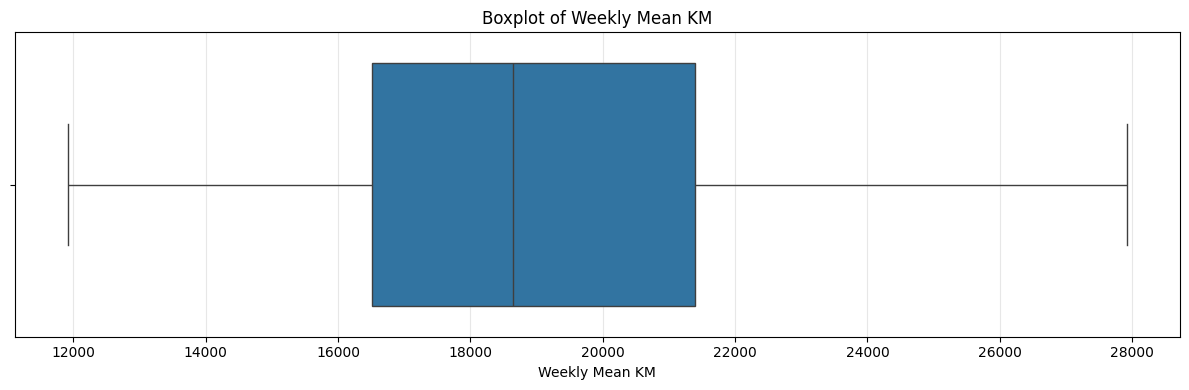

In [142]:
plt.figure(figsize=(12, 4))

sns.boxplot(x=weekly_analysis_final['weekly_mean_km'])

plt.title('Boxplot of Weekly Mean KM')
plt.xlabel('Weekly Mean KM')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [143]:
from statsmodels.tsa.stattools import adfuller

adf_series_final = weekly_analysis_final['weekly_mean_km']

adf_result = adfuller(adf_series_final)

print("ADF Statistic:", adf_result[0])
print("P-value:", adf_result[1])
print("Lags Used:", adf_result[2])
print("Observations Used:", adf_result[3])
print("Critical Values:", adf_result[4])

ADF Statistic: -9.857728469766
P-value: 4.314524808736449e-17
Lags Used: 0
Observations Used: 83
Critical Values: {'1%': np.float64(-3.5117123057187376), '5%': np.float64(-2.8970475206326833), '10%': np.float64(-2.5857126912469153)}


/tmp/ipykernel_482/267267803.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(adf_series_final)


The Augmented Dickey-Fuller (ADF) test was conducted on the final direct weekly mean KM series. The test produced an ADF statistic of −9.8577 and a p-value of 4.3145 × 10⁻¹⁷. The null hypothesis of non-stationarity was rejected. The result was consistent with the KPSS test, which did not reject its null hypothesis of stationarity (p-value greater than 0.10). Together, these results provide evidence that the weekly mean KM series is stationary, although conclusions should be interpreted cautiously given the limited 84-week dataset.

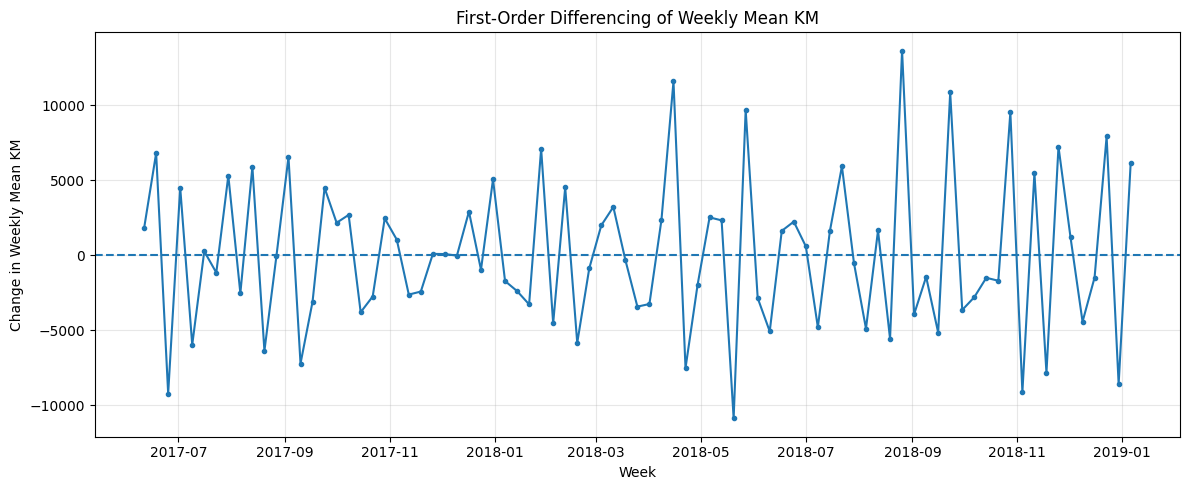

In [144]:
# First-order differencing
weekly_diff_1 = weekly_analysis_final['weekly_mean_km'].diff()

plt.figure(figsize=(12, 5))

plt.plot(weekly_diff_1, marker='o', markersize=3)

plt.axhline(0, linestyle='--')

plt.title('First-Order Differencing of Weekly Mean KM')
plt.xlabel('Week')
plt.ylabel('Change in Weekly Mean KM')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [145]:
weekly_diff_1.describe()

,weekly_mean_km
count,83.000000
mean,36.750779
std,5144.824448
min,-10874.723156
25%,-3354.933722
50%,-316.647188
75%,2794.225742
max,13625.791897


The first-difference statistics show substantial week-to-week variability despite an average change of only 36.75 KM and a median change of −316.65 KM. The standard deviation of 5,144.82 KM indicates considerable fluctuations between consecutive weeks, with both increases and decreases occurring throughout the observation period.

In [146]:
print("Original Weekly Mean KM Standard Deviation:",
      weekly_analysis_final['weekly_mean_km'].std())

print("First Difference Standard Deviation:",
      weekly_diff_1.std())

Original Weekly Mean KM Standard Deviation: 3463.5534962769566
First Difference Standard Deviation: 5144.82444779964


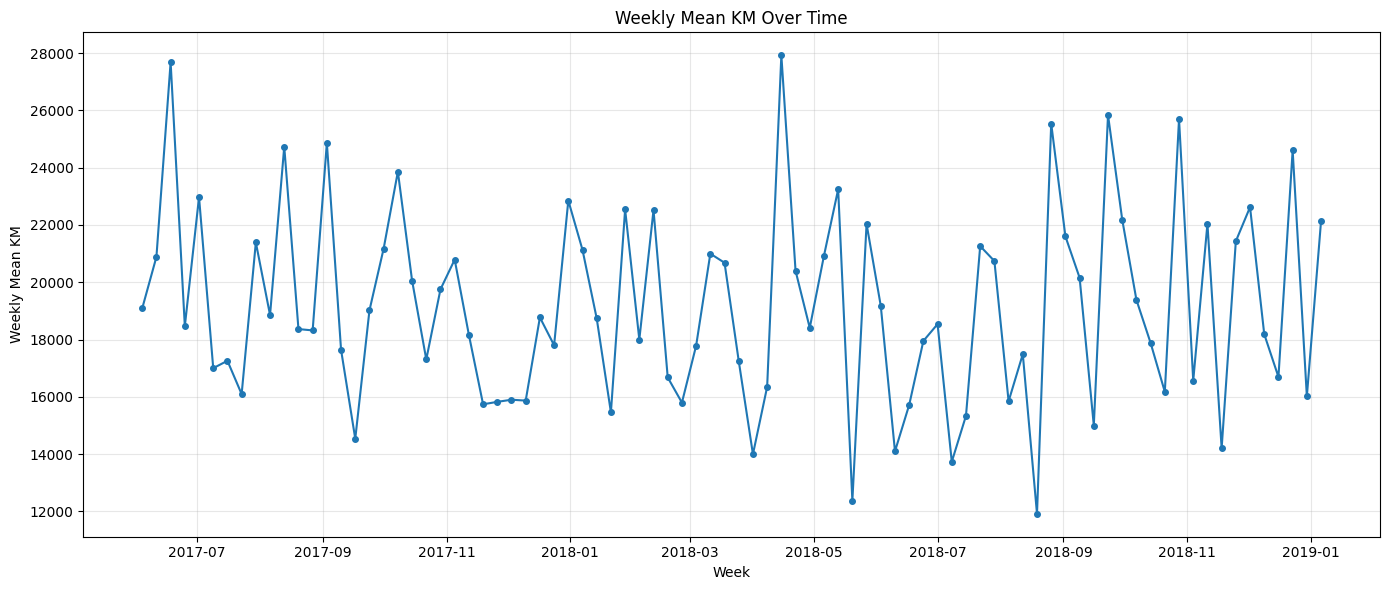

In [147]:
plt.figure(figsize=(14, 6))

plt.plot(
    weekly_analysis_final.index,
    weekly_analysis_final['weekly_mean_km'],
    marker='o',
    markersize=4
)

plt.title('Weekly Mean KM Over Time')
plt.xlabel('Week')
plt.ylabel('Weekly Mean KM')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Trend Slope (KM per week): -5.436438009417663
Intercept: 19391.78530272287
R² Score: 0.0014658922417829512


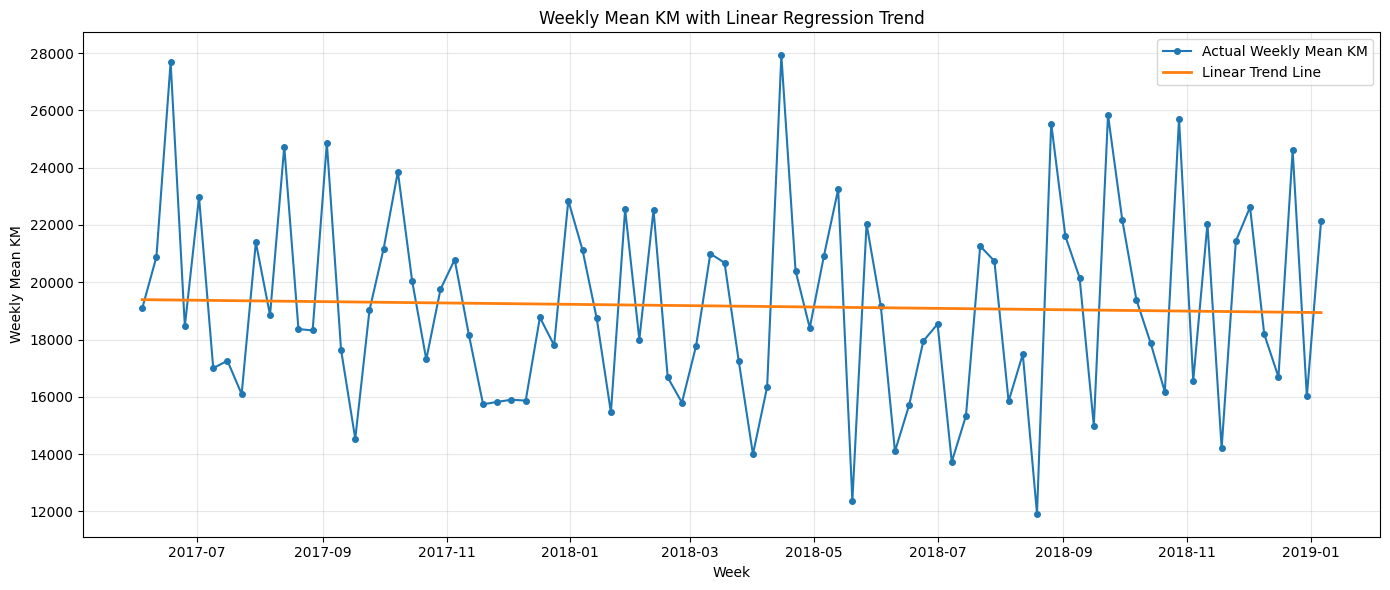

In [148]:
from sklearn.linear_model import LinearRegression
import numpy as np

# Create time index
X = np.arange(len(weekly_analysis_final)).reshape(-1, 1)

# Target variable
y = weekly_analysis_final['weekly_mean_km'].values

# Fit Linear Regression
trend_model = LinearRegression()
trend_model.fit(X, y)

# Predictions
trend_line = trend_model.predict(X)

# Results
print("Trend Slope (KM per week):", trend_model.coef_[0])
print("Intercept:", trend_model.intercept_)
print("R² Score:", trend_model.score(X, y))

# Plot
plt.figure(figsize=(14, 6))

plt.plot(
    weekly_analysis_final.index,
    y,
    marker='o',
    markersize=4,
    label='Actual Weekly Mean KM'
)

plt.plot(
    weekly_analysis_final.index,
    trend_line,
    linewidth=2,
    label='Linear Trend Line'
)

plt.title('Weekly Mean KM with Linear Regression Trend')
plt.xlabel('Week')
plt.ylabel('Weekly Mean KM')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Linear regression trend analysis produced a slope of −5.436 KM per week and an R² score of 0.001466. The slope indicates a negligible downward trend, while the R² suggests that time explains only approximately 0.147% of the variation in weekly mean KM. This supports the visual observation that the series has no strong linear trend and is dominated by fluctuations.

In [149]:
import pymannkendall as mk

mk_final_result = mk.original_test(
    weekly_analysis_final['weekly_mean_km']
)

print("Trend:", mk_final_result.trend)
print("H:", mk_final_result.h)
print("P-value:", mk_final_result.p)
print("Z-statistic:", mk_final_result.z)
print("Kendall's Tau:", mk_final_result.Tau)
print("Sen's Slope:", mk_final_result.slope)
print("Intercept:", mk_final_result.intercept)

Trend: no trend
H: False
P-value: 0.6850187769313167
Z-statistic: -0.4056241563254352
Kendall's Tau: -0.030407343660355707
Sen's Slope: -8.08518343526394
Intercept: 18972.550214351082


The Mann–Kendall trend test was performed on the final weekly mean KM series. The test indicated no statistically significant trend (p = 0.6850, Kendall's Tau = −0.0304). Sen's slope estimated a slight decrease of approximately 8.09 KM per week, which is negligible relative to the observed weekly values. These results agree with the linear regression trend analysis, suggesting that the series exhibits fluctuations without a significant monotonic trend

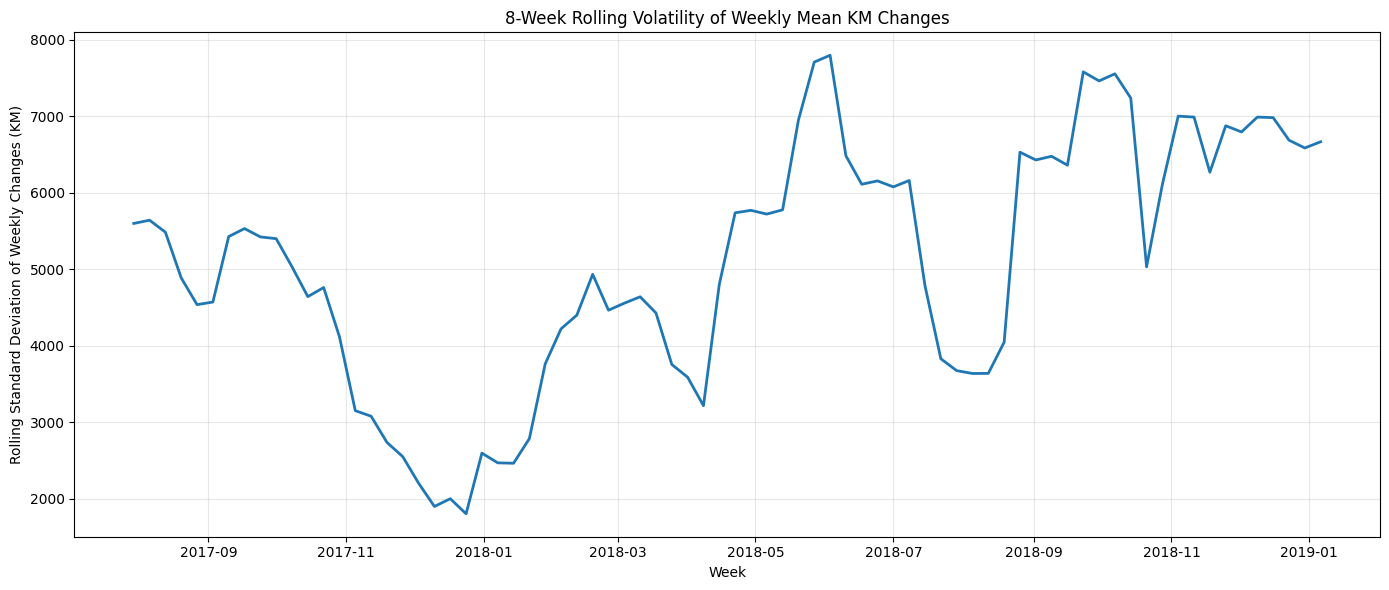

In [150]:
# Calculate weekly changes
weekly_diff_1 = weekly_analysis_final['weekly_mean_km'].diff()

# Calculate rolling volatility over 8 weeks
weekly_volatility = weekly_diff_1.rolling(window=8).std()

# Plot
plt.figure(figsize=(14, 6))

plt.plot(
    weekly_volatility.index,
    weekly_volatility,
    linewidth=2
)

plt.title('8-Week Rolling Volatility of Weekly Mean KM Changes')
plt.xlabel('Week')
plt.ylabel('Rolling Standard Deviation of Weekly Changes (KM)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


The 8-week rolling standard deviation of weekly KM changes indicates varying volatility over time. Volatility declined toward late 2017, increased during early-to-mid 2018, decreased around July–August 2018, and rose again during late 2018. This suggests that week-to-week fluctuations were not uniform throughout the observation period. However, this exploratory plot alone does not establish statistically significant volatility clustering

In [151]:
weekly_volatility.describe()

,weekly_mean_km
count,76.000000
mean,5080.684735
std,1606.583783
min,1803.813419
25%,3812.298706
50%,5214.757378
75%,6438.627778
max,7794.576057


The 8-week rolling volatility had a mean of 5,080.68 KM and ranged from 1,803.81 to 7,794.58 KM. The standard deviation of rolling volatility was 1,606.58 KM, indicating considerable variation in the magnitude of weekly fluctuations across different periods.

In [152]:
weekly_pct_change = weekly_analysis_final['weekly_mean_km'].pct_change() * 100

print("Weekly Percentage Change Summary:")
display(weekly_pct_change.describe())

Weekly Percentage Change Summary:


,weekly_mean_km
count,83.000000
mean,3.897701
std,29.477538
min,-46.787377
25%,-16.260218
50%,-1.508087
75%,17.431103
max,114.358886


The weekly percentage change analysis indicates substantial relative fluctuations in weekly mean KM. Percentage changes ranged from −46.79% to +114.36%, with a standard deviation of 29.48%. The median change was −1.51%, compared with a positive mean of 3.90%, suggesting that larger positive changes influenced the average. Overall, weekly readings are highly variable relative to their previous-week values.

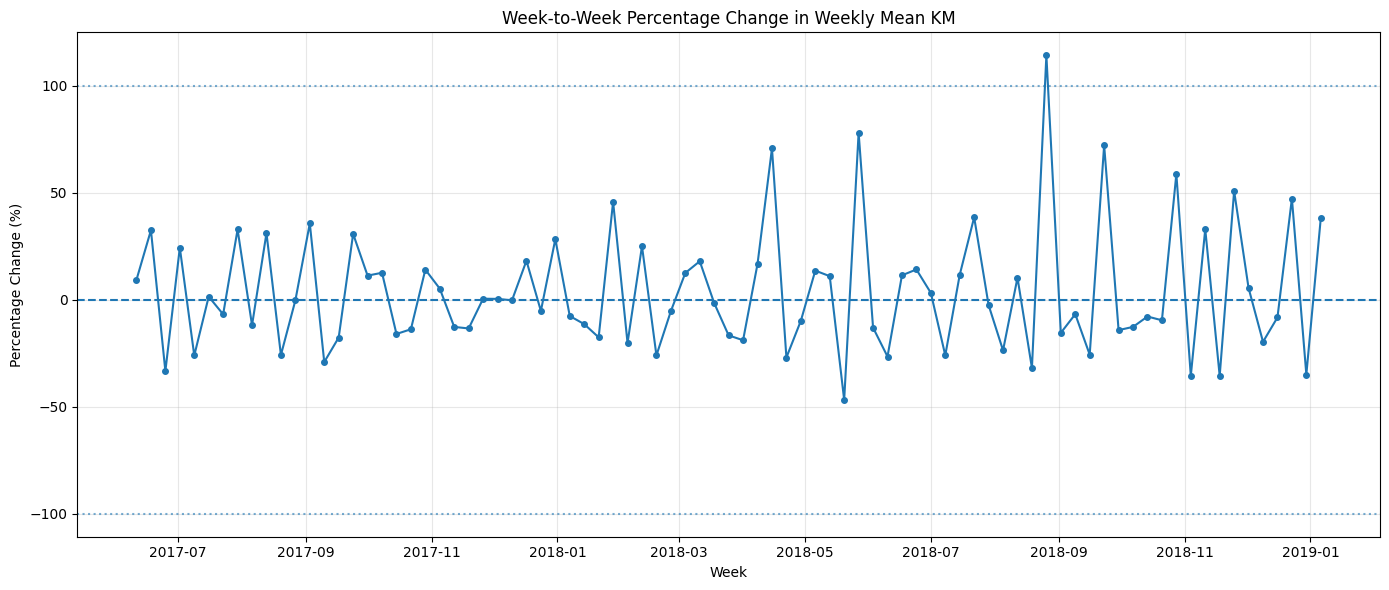

In [153]:
plt.figure(figsize=(14, 6))

plt.plot(
    weekly_pct_change.index,
    weekly_pct_change,
    marker='o',
    markersize=4
)

plt.axhline(0, linestyle='--')
plt.axhline(100, linestyle=':', alpha=0.6)
plt.axhline(-100, linestyle=':', alpha=0.6)

plt.title('Week-to-Week Percentage Change in Weekly Mean KM')
plt.xlabel('Week')
plt.ylabel('Percentage Change (%)')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Week-to-week percentage changes demonstrate substantial relative variability in weekly mean KM. Most changes are moderate, but several large increases and decreases occur throughout the observation period. No consistent directional pattern is evident. The largest percentage changes may be influenced by unusually low or high values in consecutive weeks and should be investigated rather than automatically treated as anomalies

In [154]:
# Top 5 largest weekly percentage increases
top_increases = weekly_pct_change.nlargest(5)

# Top 5 largest weekly percentage decreases
top_decreases = weekly_pct_change.nsmallest(5)

print("Top 5 Weekly Percentage Increases:")
display(top_increases)

print("\nTop 5 Weekly Percentage Decreases:")
display(top_decreases)

Top 5 Weekly Percentage Increases:


,weekly_mean_km
invoice_date,
2018-08-26,114.358886
2018-05-27,78.167031
2018-09-23,72.292038
2018-04-15,70.841026
2018-10-28,58.874548



Top 5 Weekly Percentage Decreases:


,weekly_mean_km
invoice_date,
2018-05-20,-46.787377
2018-11-18,-35.564809
2018-11-04,-35.532444
2018-12-30,-34.912881
2017-06-25,-33.308763


In [155]:
# Create a comparison table
weekly_comparison = pd.DataFrame({
    'Previous_Week_KM': weekly_analysis_final['weekly_mean_km'].shift(1),
    'Current_Week_KM': weekly_analysis_final['weekly_mean_km'],
    'Percentage_Change': weekly_pct_change
})

# Get the dates of the top increases and decreases
extreme_dates = top_increases.index.tolist() + top_decreases.index.tolist()

# Filter the comparison table
extreme_comparison = weekly_comparison.loc[extreme_dates].sort_index()

display(extreme_comparison)

,Previous_Week_KM,Current_Week_KM,Percentage_Change
invoice_date,,,
2017-06-25,27684.069333,18462.848387,-33.308763
2018-04-15,16345.164634,27924.247024,70.841026
2018-05-20,23242.857143,12368.133987,-46.787377
2018-05-27,12368.133987,22035.937063,78.167031
2018-08-26,11914.939306,25540.731203,114.358886
2018-09-23,14997.118203,25838.840551,72.292038
2018-10-28,16172.517544,25694.014199,58.874548
2018-11-04,25694.014199,16564.303030,-35.532444
2018-11-18,22041.070175,14202.205656,-35.564809


Investigation of the extreme weekly percentage changes revealed that some large fluctuations were associated with sharp changes between consecutive weeks, including low weekly values followed by substantial rebounds. These changes do not necessarily indicate a sustained trend or data errors. They should be retained unless independent evidence confirms an issue.

In [156]:
# Calculate correlation
pearson_corr = weekly_analysis_final[
    ['weekly_record_count', 'weekly_mean_km']
].corr(method='pearson')

spearman_corr = weekly_analysis_final[
    ['weekly_record_count', 'weekly_mean_km']
].corr(method='spearman')

print("Pearson Correlation:")
display(pearson_corr)

print("\nSpearman Correlation:")
display(spearman_corr)

Pearson Correlation:


,weekly_record_count,weekly_mean_km
weekly_record_count,1.000000,0.170313
weekly_mean_km,0.170313,1.000000



Spearman Correlation:


,weekly_record_count,weekly_mean_km
weekly_record_count,1.00000,0.09813
weekly_mean_km,0.09813,1.00000


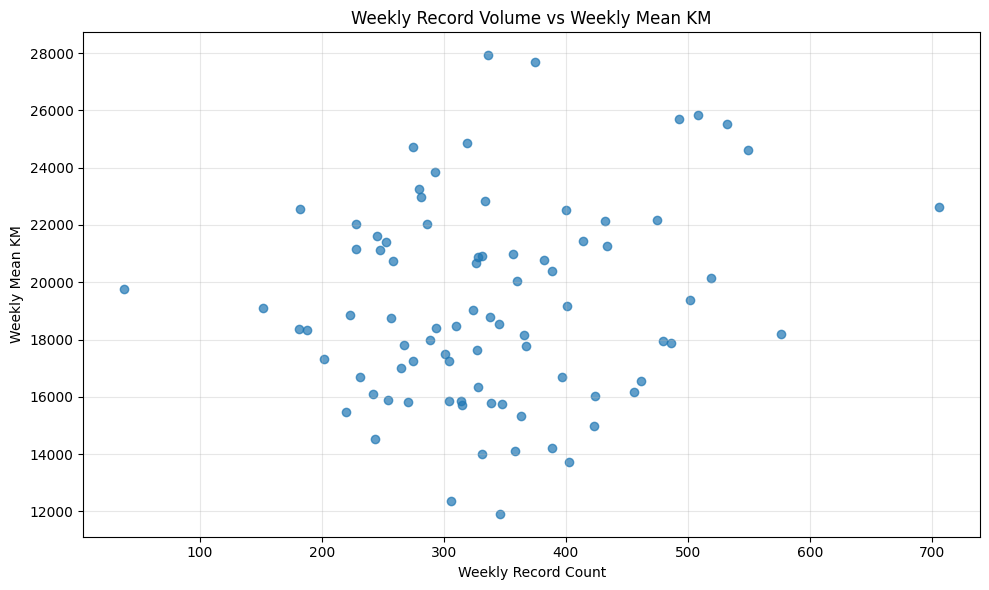

In [157]:
plt.figure(figsize=(10, 6))

plt.scatter(
    weekly_analysis_final['weekly_record_count'],
    weekly_analysis_final['weekly_mean_km'],
    alpha=0.7
)

plt.title('Weekly Record Volume vs Weekly Mean KM')
plt.xlabel('Weekly Record Count')
plt.ylabel('Weekly Mean KM')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [158]:
weekly_analysis_final['weekly_record_count'].describe()

,weekly_record_count
count,84.000000
mean,339.071429
std,105.776507
min,38.000000
25%,270.000000
50%,328.000000
75%,397.750000
max,706.000000


In [159]:
Q1_volume = weekly_analysis_final['weekly_record_count'].quantile(0.25)
Q3_volume = weekly_analysis_final['weekly_record_count'].quantile(0.75)

IQR_volume = Q3_volume - Q1_volume

lower_volume_bound = Q1_volume - 1.5 * IQR_volume
upper_volume_bound = Q3_volume + 1.5 * IQR_volume

volume_outliers = weekly_analysis_final[
    (weekly_analysis_final['weekly_record_count'] < lower_volume_bound) |
    (weekly_analysis_final['weekly_record_count'] > upper_volume_bound)
]

print("Q1:", Q1_volume)
print("Q3:", Q3_volume)
print("IQR:", IQR_volume)
print("Lower Bound:", lower_volume_bound)
print("Upper Bound:", upper_volume_bound)
print("Potential Outlier Weeks:", len(volume_outliers))

display(volume_outliers)

Q1: 270.0
Q3: 397.75
IQR: 127.75
Lower Bound: 78.375
Upper Bound: 589.375
Potential Outlier Weeks: 2


,weekly_mean_km,weekly_record_count,observed_days,rolling_8_week_mean,rolling_8_week_std,month
invoice_date,,,,,,
2017-10-29,19752.105263,38,2,19168.450268,2790.376813,10
2018-12-02,22620.923513,706,7,19575.625563,3939.574970,12


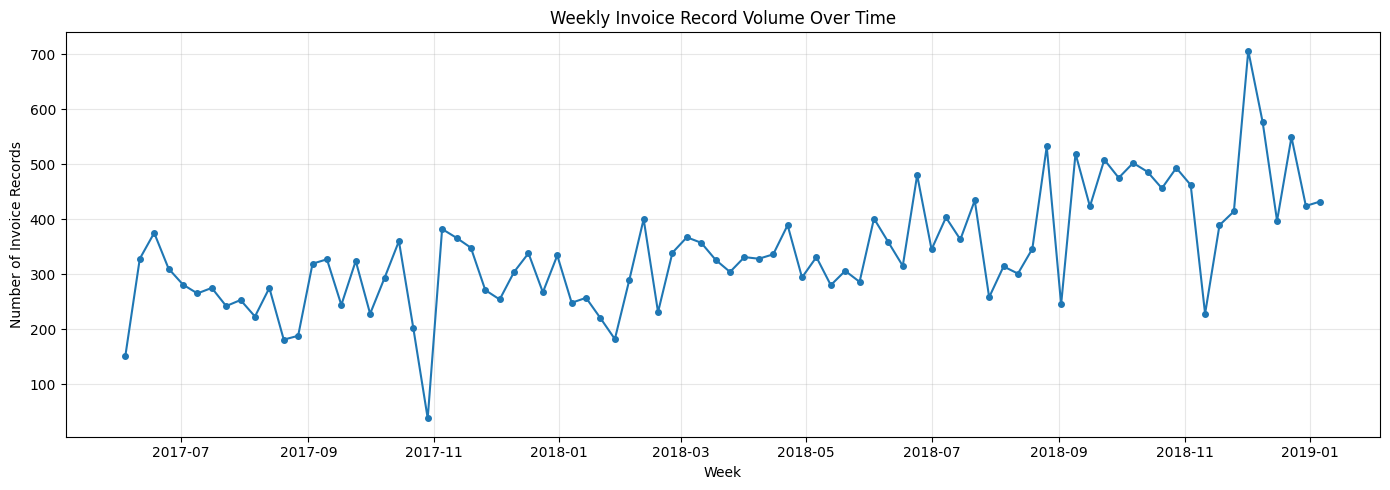

In [160]:
plt.figure(figsize=(14, 5))

plt.plot(
    weekly_analysis_final.index,
    weekly_analysis_final['weekly_record_count'],
    marker='o',
    markersize=4
)

plt.title('Weekly Invoice Record Volume Over Time')
plt.xlabel('Week')
plt.ylabel('Number of Invoice Records')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [161]:
from scipy.stats import linregress
import numpy as np

x = np.arange(len(weekly_analysis_final))
y = weekly_analysis_final['weekly_record_count']

trend_result = linregress(x, y)

print("Trend Slope (records per week):", trend_result.slope)
print("Intercept:", trend_result.intercept)
print("R² Score:", trend_result.rvalue ** 2)
print("P-value:", trend_result.pvalue)

Trend Slope (records per week): 2.83533461577402
Intercept: 221.40504201680673
R² Score: 0.42751086740407523
P-value: 1.5488852015920864e-11


In [162]:
import pymannkendall as mk

mk_volume_result = mk.original_test(
    weekly_analysis_final['weekly_record_count']
)

print("Trend:", mk_volume_result.trend)
print("H:", mk_volume_result.h)
print("P-value:", mk_volume_result.p)
print("Z-statistic:", mk_volume_result.z)
print("Kendall's Tau:", mk_volume_result.Tau)
print("Sen's Slope:", mk_volume_result.slope)

Trend: increasing
H: True
P-value: 1.0601022282230588e-09
Z-statistic: 6.10008780274073
Kendall's Tau: 0.45324153757888697
Sen's Slope: 2.6821789321789318


Weekly invoice-record volume exhibits a statistically significant increasing trend over the observation period. Linear regression estimated an increase of 2.84 records per week, while the Mann–Kendall test confirmed the upward trend with a Sen's slope of 2.68 records per week. Both methods indicate increasing recorded service activity over time.

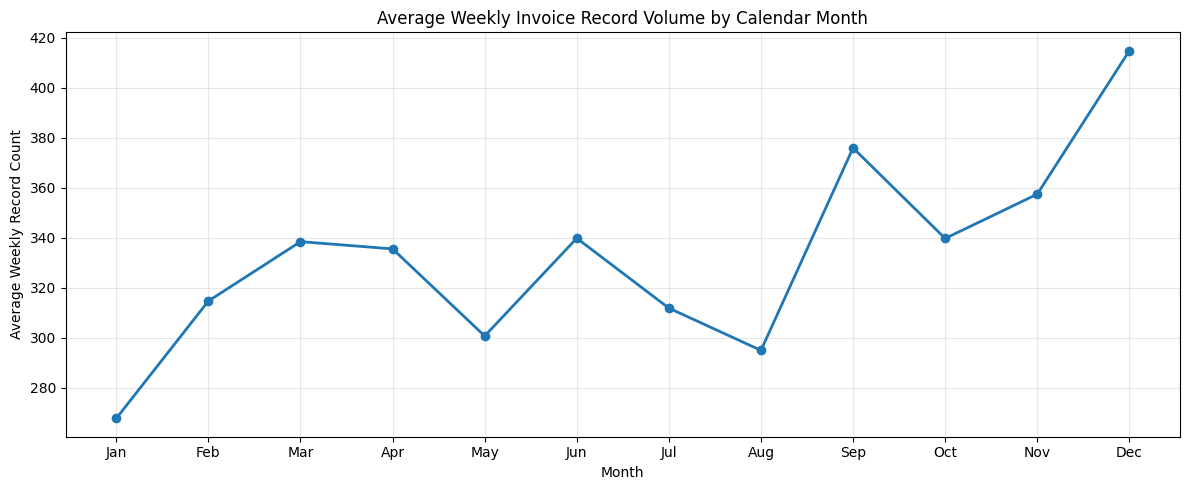

,weekly_record_count
month,
1,267.800000
2,314.750000
3,338.500000
4,335.600000
5,300.750000
6,339.875000
7,311.900000
8,295.000000
9,376.000000


In [163]:
# Extract calendar month from weekly index
weekly_analysis_final['month'] = weekly_analysis_final.index.month

# Calculate average weekly invoice volume by month
monthly_volume_seasonality = weekly_analysis_final.groupby('month')['weekly_record_count'].mean()

# Plot
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_volume_seasonality.index,
    monthly_volume_seasonality.values,
    marker='o',
    linewidth=2
)

plt.title('Average Weekly Invoice Record Volume by Calendar Month')
plt.xlabel('Month')
plt.ylabel('Average Weekly Record Count')

plt.xticks(
    range(1, 13),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly_volume_seasonality)

Average weekly invoice-record volume varies across calendar months, with higher activity observed in September and December and lower activity in January and August. However, because the dataset covers less than two complete annual cycles, these patterns should be treated as exploratory observations rather than confirmed recurring seasonality

<Figure size 1200x600 with 0 Axes>

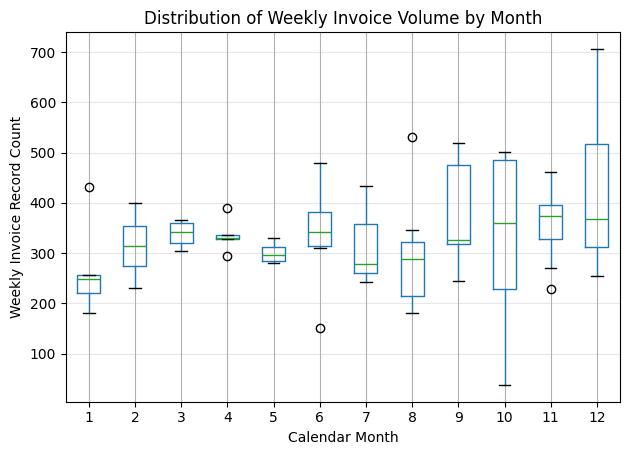

In [164]:
plt.figure(figsize=(12, 6))

weekly_analysis_final.boxplot(
    column='weekly_record_count',
    by='month'
)

plt.title('Distribution of Weekly Invoice Volume by Month')
plt.suptitle('')
plt.xlabel('Calendar Month')
plt.ylabel('Weekly Invoice Record Count')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

The monthly boxplot shows substantial variation in weekly invoice volume within several calendar months. Although September and December have relatively high average activity, their weekly distributions are also spread out. Therefore, higher monthly averages are not necessarily consistent across all weeks. The observed monthly patterns remain exploratory because the dataset covers fewer than two full annual cycles.

In [165]:
monthly_volume_stats = weekly_analysis_final.groupby('month')['weekly_record_count'].agg(
    ['mean', 'median', 'std', 'min', 'max', 'count']
).sort_values('std', ascending=False)

display(monthly_volume_stats)

,mean,median,std,min,max,count
month,,,,,,
10,339.777778,360.0,161.951210,38,502,9
12,414.900000,367.5,149.665887,254,706,10
8,295.000000,288.0,112.881733,181,532,8
9,376.000000,327.0,107.716062,244,519,9
1,267.800000,248.0,96.328604,182,432,5
6,339.875000,343.0,94.023458,152,480,8
11,357.500000,374.0,75.706199,228,462,8
2,314.750000,314.0,71.955426,231,400,4
7,311.900000,278.0,68.872588,242,434,10


In [166]:
from statsmodels.tsa.stattools import adfuller

volume_series = weekly_analysis_final['weekly_record_count']

adf_volume_result = adfuller(volume_series)

print("ADF Statistic:", adf_volume_result[0])
print("P-value:", adf_volume_result[1])
print("Lags Used:", adf_volume_result[2])
print("Observations Used:", adf_volume_result[3])
print("Critical Values:", adf_volume_result[4])

ADF Statistic: -1.3867172596306026
P-value: 0.588627205992589
Lags Used: 4
Observations Used: 79
Critical Values: {'1%': np.float64(-3.5159766913976376), '5%': np.float64(-2.898885703483903), '10%': np.float64(-2.5866935058484217)}


/tmp/ipykernel_482/2708567291.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_volume_result = adfuller(volume_series)


The ADF test produced a p-value of 0.5886, which is greater than the 0.05 significance level. Therefore, we fail to reject the null hypothesis of a unit root. Weekly invoice-record volume is non-stationary, indicating that its statistical properties may change over time. This finding is consistent with the previously identified significant upward trend

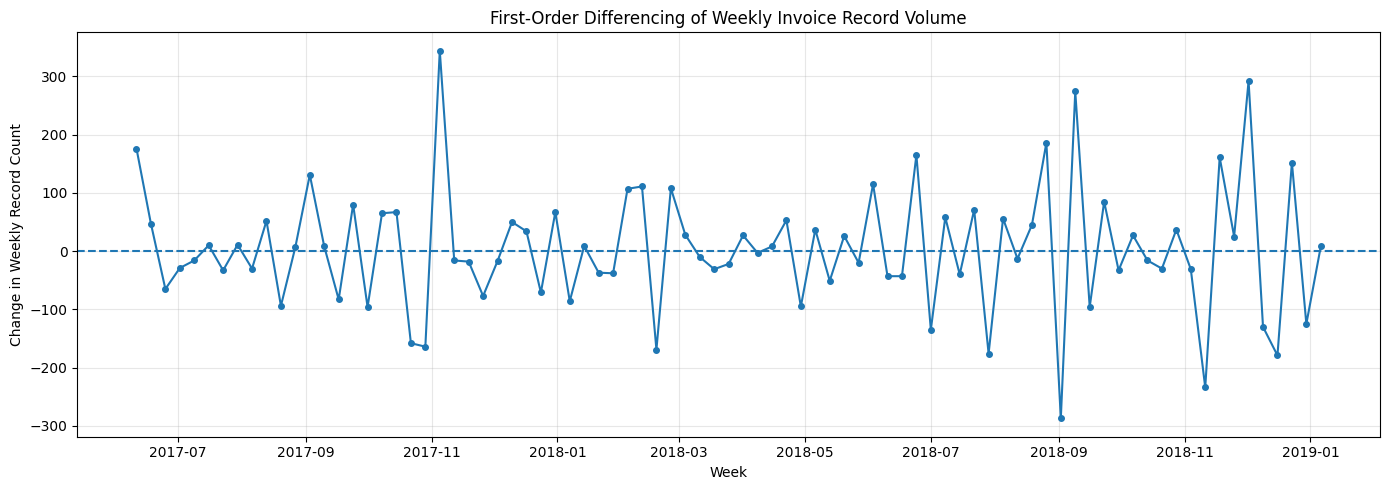

In [167]:
weekly_volume_diff = volume_series.diff().dropna()

plt.figure(figsize=(14, 5))

plt.plot(
    weekly_volume_diff.index,
    weekly_volume_diff,
    marker='o',
    markersize=4
)

plt.axhline(0, linestyle='--')
plt.title('First-Order Differencing of Weekly Invoice Record Volume')
plt.xlabel('Week')
plt.ylabel('Change in Weekly Record Count')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [168]:
from statsmodels.tsa.stattools import adfuller

adf_diff_result = adfuller(weekly_volume_diff)

print("ADF Statistic:", adf_diff_result[0])
print("P-value:", adf_diff_result[1])
print("Lags Used:", adf_diff_result[2])
print("Observations Used:", adf_diff_result[3])
print("Critical Values:", adf_diff_result[4])

ADF Statistic: -7.646375003976195
P-value: 1.838018740575742e-11
Lags Used: 3
Observations Used: 79
Critical Values: {'1%': np.float64(-3.5159766913976376), '5%': np.float64(-2.898885703483903), '10%': np.float64(-2.5866935058484217)}


/tmp/ipykernel_482/3999742250.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff_result = adfuller(weekly_volume_diff)


In [169]:
from statsmodels.tsa.stattools import kpss

kpss_diff_result = kpss(weekly_volume_diff, regression='c')

print("KPSS Statistic:", kpss_diff_result[0])
print("P-value:", kpss_diff_result[1])
print("Lags Used:", kpss_diff_result[2])
print("Critical Values:", kpss_diff_result[3])

KPSS Statistic: 0.16405624548487766
P-value: 0.1
Lags Used: 23
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}


/tmp/ipykernel_482/2060400885.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_diff_result = kpss(weekly_volume_diff, regression='c')
/tmp/ipykernel_482/2060400885.py:3: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_diff_result = kpss(weekly_volume_diff, regression='c')


<Figure size 1200x500 with 0 Axes>

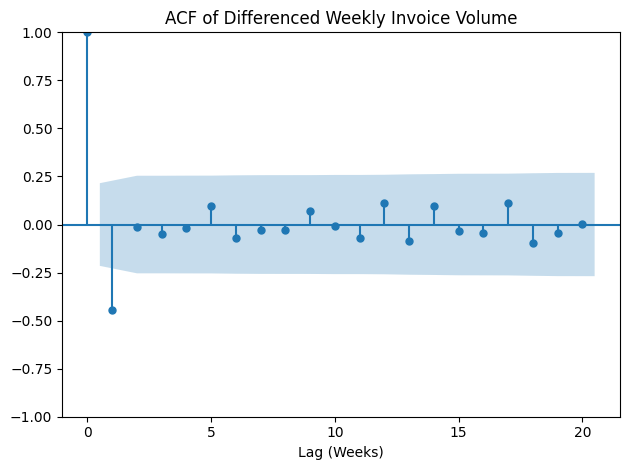

In [170]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plot_acf(
    weekly_volume_diff,
    lags=20
)

plt.title('ACF of Differenced Weekly Invoice Volume')
plt.xlabel('Lag (Weeks)')
plt.tight_layout()
plt.show()

<Figure size 1200x500 with 0 Axes>

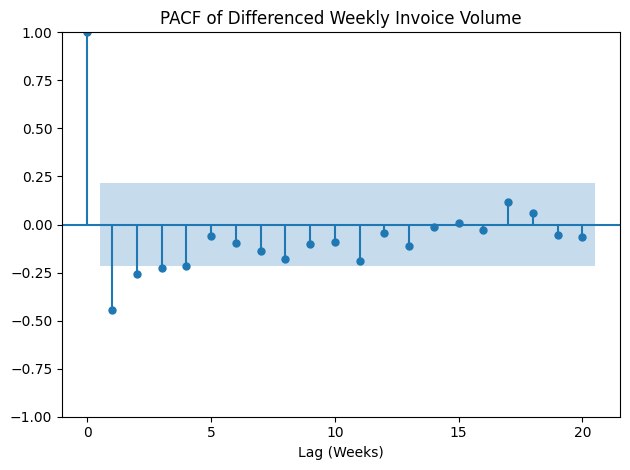

In [171]:
from statsmodels.graphics.tsaplots import plot_pacf
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plot_pacf(
    weekly_volume_diff,
    lags=20,
    method='ywm'
)

plt.title('PACF of Differenced Weekly Invoice Volume')
plt.xlabel('Lag (Weeks)')
plt.tight_layout()
plt.show()

<Figure size 1200x500 with 0 Axes>

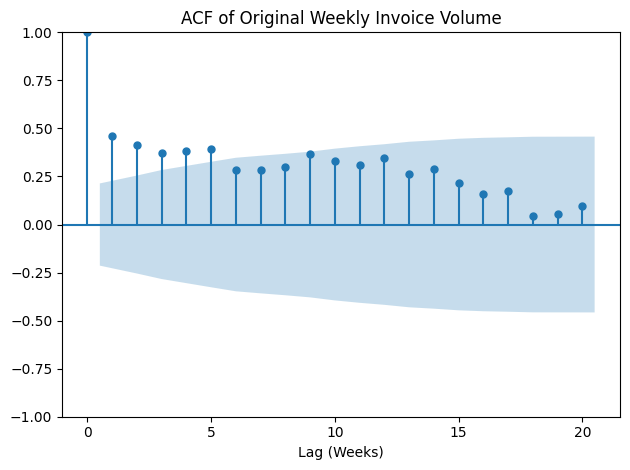

In [172]:
from statsmodels.graphics.tsaplots import plot_acf
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plot_acf(volume_series, lags=20)

plt.title('ACF of Original Weekly Invoice Volume')
plt.xlabel('Lag (Weeks)')
plt.tight_layout()
plt.show()

In [173]:
from statsmodels.tsa.stattools import acf

acf_values = acf(volume_series, nlags=20)

print("Lag 4 ACF:", acf_values[4])
print("Lag 13 ACF:", acf_values[13])

Lag 4 ACF: 0.3844129499004259
Lag 13 ACF: 0.2610843764083141


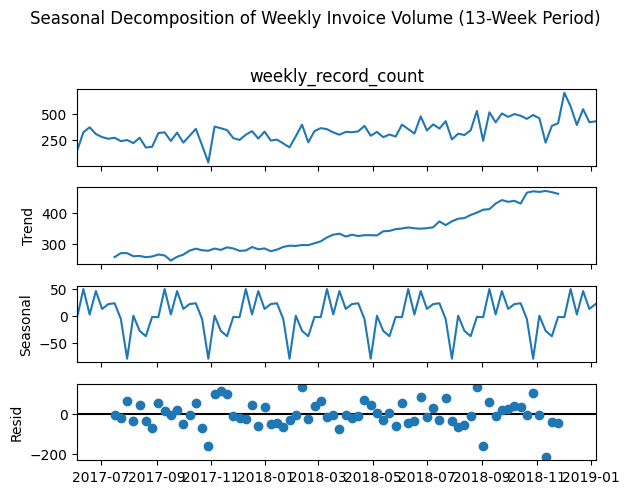

In [174]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

decomposition = seasonal_decompose(
    volume_series,
    model='additive',
    period=13
)

decomposition.plot()
plt.suptitle('Seasonal Decomposition of Weekly Invoice Volume (13-Week Period)', y=1.02)
plt.tight_layout()
plt.show()

In [175]:
import numpy as np

seasonal_component = decomposition.seasonal
residual_component = decomposition.resid

seasonal_strength = max(
    0,
    1 - (np.var(residual_component.dropna()) /
          np.var((residual_component + seasonal_component).dropna()))
)

print("Seasonal Strength:", seasonal_strength)

Seasonal Strength: 0.22111820622885636


In [176]:
# Chronological train-test split (80/20)

split_point = int(len(volume_series) * 0.80)

train = volume_series.iloc[:split_point]
test = volume_series.iloc[split_point:]

print("Total observations:", len(volume_series))
print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Total observations: 84
Training observations: 67
Testing observations: 17

Training period:
2017-06-04 00:00:00 to 2018-09-09 00:00:00

Testing period:
2018-09-16 00:00:00 to 2019-01-06 00:00:00


In [177]:
# Prepare weekly invoice volume series
volume_series = weekly_analysis_final['weekly_record_count']

# Chronological train-test split (80/20)
train_volume = volume_series.iloc[:67]
test_volume = volume_series.iloc[67:]

# Naive forecast: use the last training value for every test week
naive_forecast = [train_volume.iloc[-1]] * len(test_volume)

print("Last Training Week Value:", train_volume.iloc[-1])
print("Test Weeks:", len(test_volume))
print("Naive Forecast:", naive_forecast)

Last Training Week Value: 519
Test Weeks: 17
Naive Forecast: [np.int64(519), np.int64(519), np.int64(519), np.int64(519), np.int64(519), np.int64(519), np.int64(519), np.int64(519), np.int64(519), np.int64(519), np.int64(519), np.int64(519), np.int64(519), np.int64(519), np.int64(519), np.int64(519), np.int64(519)]


In [178]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Evaluate Naive Forecast
mae = mean_absolute_error(test_volume, naive_forecast)
rmse = np.sqrt(mean_squared_error(test_volume, naive_forecast))
mape = np.mean(np.abs((test_volume - naive_forecast) / test_volume)) * 100

print("Naive Model MAE:", mae)
print("Naive Model RMSE:", rmse)
print("Naive Model MAPE:", mape, "%")

Naive Model MAE: 85.3529411764706
Naive Model RMSE: 109.47656209006028
Naive Model MAPE: 22.191936818905926 %


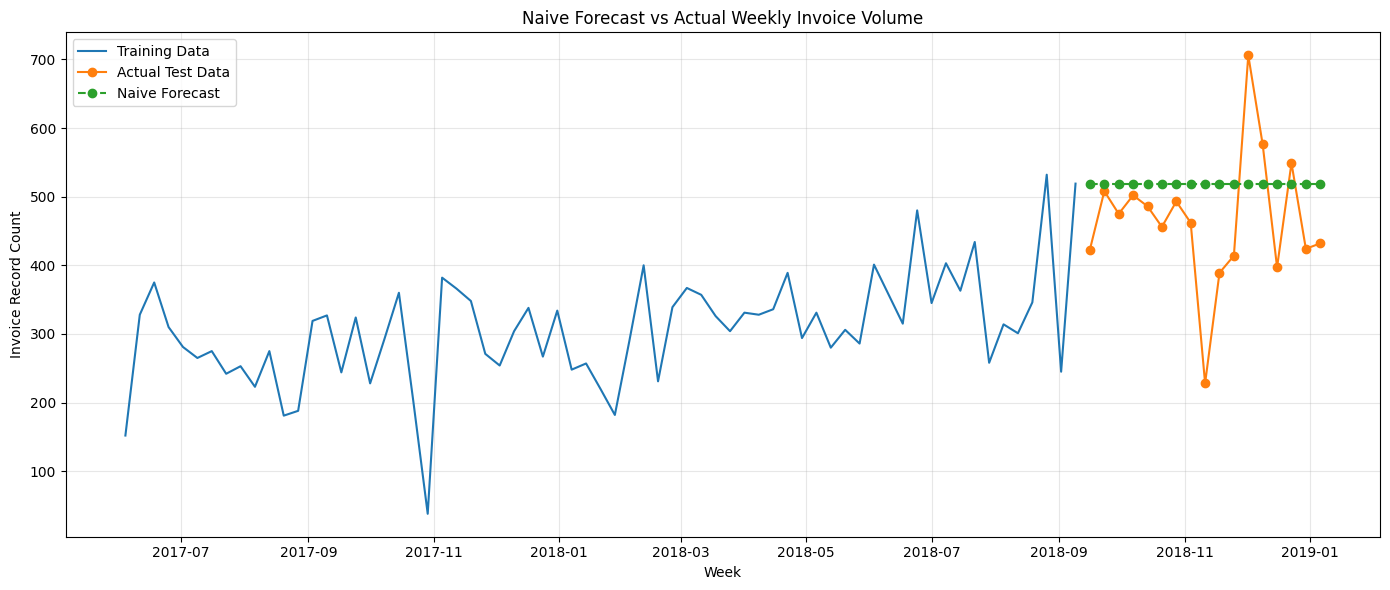

In [179]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(train_volume.index, train_volume, label='Training Data')
plt.plot(test_volume.index, test_volume, label='Actual Test Data', marker='o')
plt.plot(test_volume.index, naive_forecast, label='Naive Forecast', linestyle='--', marker='o')

plt.title('Naive Forecast vs Actual Weekly Invoice Volume')
plt.xlabel('Week')
plt.ylabel('Invoice Record Count')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [180]:
# Calculate the average of the last 4 training weeks
last_4_week_avg = train_volume.tail(4).mean()

# Forecast all 17 test weeks using this average
moving_avg_forecast = [last_4_week_avg] * len(test_volume)

print("Last 4 Weeks Values:")
print(train_volume.tail(4))

print("\n4-Week Moving Average Forecast:", last_4_week_avg)
print("Test Weeks:", len(test_volume))

Last 4 Weeks Values:
invoice_date
2018-08-19    346
2018-08-26    532
2018-09-02    245
2018-09-09    519
Freq: W-SUN, Name: weekly_record_count, dtype: int64

4-Week Moving Average Forecast: 410.5
Test Weeks: 17


In [181]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae_4wk = mean_absolute_error(test_volume, moving_avg_forecast)
rmse_4wk = np.sqrt(mean_squared_error(test_volume, moving_avg_forecast))
mape_4wk = np.mean(np.abs((test_volume - moving_avg_forecast) / test_volume)) * 100

print("4-Week Moving Average MAE:", mae_4wk)
print("4-Week Moving Average RMSE:", rmse_4wk)
print("4-Week Moving Average MAPE:", mape_4wk, "%")

4-Week Moving Average MAE: 80.97058823529412
4-Week Moving Average RMSE: 110.59312019874527
4-Week Moving Average MAPE: 17.714234172123156 %


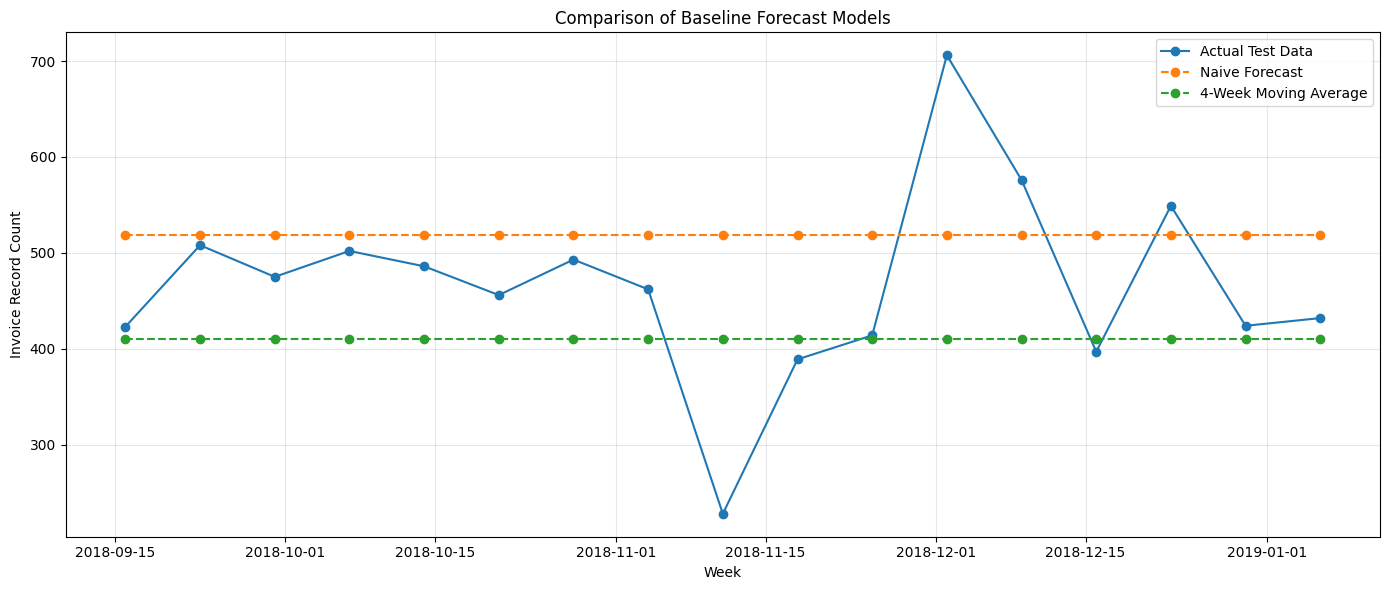

In [182]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(test_volume.index, test_volume,
         marker='o', label='Actual Test Data')

plt.plot(test_volume.index, naive_forecast,
         linestyle='--', marker='o', label='Naive Forecast')

plt.plot(test_volume.index, moving_avg_forecast,
         linestyle='--', marker='o', label='4-Week Moving Average')

plt.title('Comparison of Baseline Forecast Models')
plt.xlabel('Week')
plt.ylabel('Invoice Record Count')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [183]:
# Rolling 4-week moving average forecast

history = list(train_volume.values)
rolling_forecast = []

for actual_value in test_volume:

    # Forecast using the last 4 available weeks
    forecast = np.mean(history[-4:])
    rolling_forecast.append(forecast)

    # Update history with the actual observation
    history.append(actual_value)

print("Rolling 4-Week Forecast:")
print(rolling_forecast)
print("Number of Forecasts:", len(rolling_forecast))

Rolling 4-Week Forecast:
[np.float64(410.5), np.float64(429.75), np.float64(423.75), np.float64(481.25), np.float64(477.0), np.float64(492.75), np.float64(479.75), np.float64(484.25), np.float64(474.25), np.float64(409.75), np.float64(393.0), np.float64(373.25), np.float64(434.25), np.float64(521.25), np.float64(523.25), np.float64(557.0), np.float64(486.5)]
Number of Forecasts: 17


In [184]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae_rolling = mean_absolute_error(test_volume, rolling_forecast)
rmse_rolling = np.sqrt(mean_squared_error(test_volume, rolling_forecast))
mape_rolling = np.mean(np.abs((test_volume - rolling_forecast) / test_volume)) * 100

print("Rolling 4-Week MAE:", mae_rolling)
print("Rolling 4-Week RMSE:", rmse_rolling)
print("Rolling 4-Week MAPE:", mape_rolling, "%")

Rolling 4-Week MAE: 79.05882352941177
Rolling 4-Week RMSE: 118.94765284631328
Rolling 4-Week MAPE: 18.87174446587037 %


In [185]:
baseline_comparison = pd.DataFrame({
    'Model': [
        'Naive Forecast',
        'Fixed 4-Week Moving Average',
        'Rolling 4-Week Moving Average'
    ],
    'MAE': [mae, mae_4wk, mae_rolling],
    'RMSE': [rmse, rmse_4wk, rmse_rolling],
    'MAPE (%)': [mape, mape_4wk, mape_rolling]
})

display(baseline_comparison.round(2))

,Model,MAE,RMSE,MAPE (%)
0,Naive Forecast,85.35,109.48,22.19
1,Fixed 4-Week Moving Average,80.97,110.59,17.71
2,Rolling 4-Week Moving Average,79.06,118.95,18.87


In [186]:
# Seasonal Naive Forecast (13-week period)

seasonal_period = 13

seasonal_naive_forecast = []

for i in range(len(test_data)):
    forecast = train_data.iloc[-seasonal_period + (i % seasonal_period)]
    seasonal_naive_forecast.append(forecast)

print("Seasonal Naive Forecast:")
print(seasonal_naive_forecast)

print("Number of Forecasts:", len(seasonal_naive_forecast))

NameError: name 'test_data' is not defined

In [187]:
# Seasonal Naive Forecast (13-week seasonality)

seasonal_period = 13

# Recreate train-test split
train_data = weekly_analysis_final['weekly_record_count'][:67]
test_data = weekly_analysis_final['weekly_record_count'][67:]

# Generate forecast
seasonal_naive_forecast = []

for i in range(len(test_data)):
    forecast = train_data.iloc[-seasonal_period + (i % seasonal_period)]
    seasonal_naive_forecast.append(forecast)

print("Training Data:", len(train_data))
print("Testing Data:", len(test_data))
print("Seasonal Naive Forecast:", seasonal_naive_forecast)
print("Number of Forecasts:", len(seasonal_naive_forecast))

Training Data: 67
Testing Data: 17
Seasonal Naive Forecast: [np.int64(315), np.int64(480), np.int64(345), np.int64(403), np.int64(363), np.int64(434), np.int64(258), np.int64(314), np.int64(301), np.int64(346), np.int64(532), np.int64(245), np.int64(519), np.int64(315), np.int64(480), np.int64(345), np.int64(403)]
Number of Forecasts: 17


In [188]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

seasonal_naive_mae = mean_absolute_error(test_data, seasonal_naive_forecast)
seasonal_naive_rmse = np.sqrt(
    mean_squared_error(test_data, seasonal_naive_forecast)
)
seasonal_naive_mape = np.mean(
    np.abs((test_data - seasonal_naive_forecast) / test_data)
) * 100

print("Seasonal Naive MAE:", seasonal_naive_mae)
print("Seasonal Naive RMSE:", seasonal_naive_rmse)
print("Seasonal Naive MAPE:", seasonal_naive_mape, "%")

Seasonal Naive MAE: 112.0
Seasonal Naive RMSE: 150.94408781750553
Seasonal Naive MAPE: 23.135524979848388 %


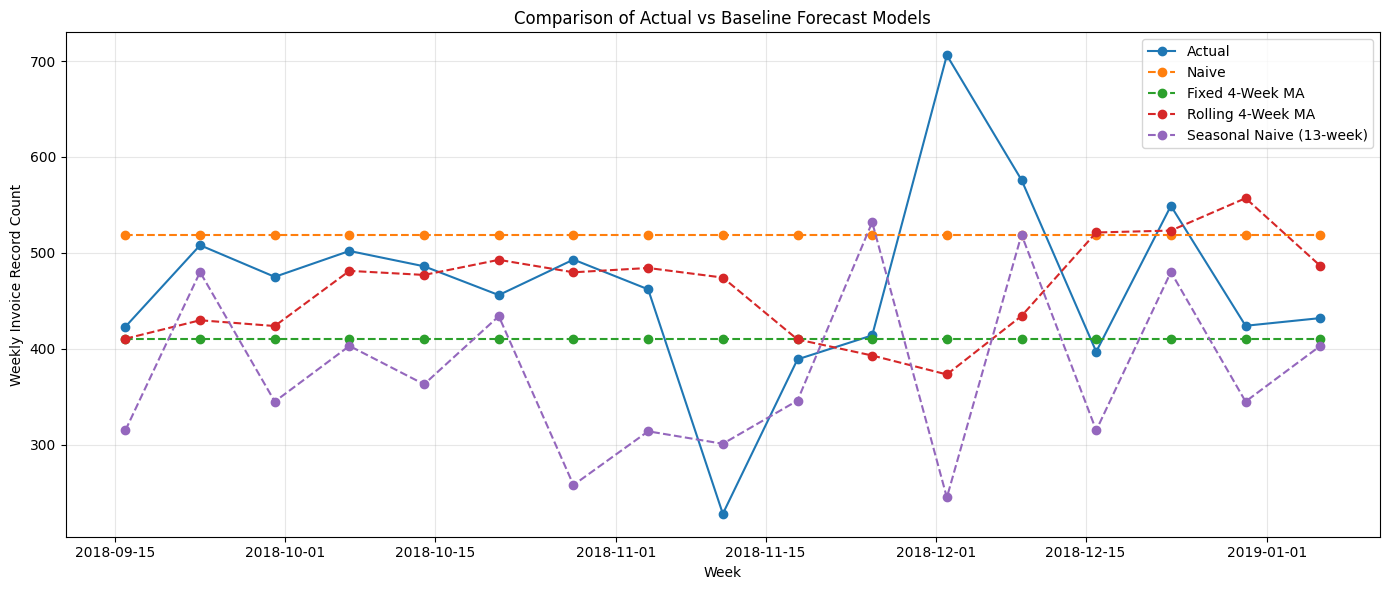

In [189]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(test_data.index, test_data,
         marker='o', label='Actual')

plt.plot(test_data.index, naive_forecast,
         marker='o', linestyle='--', label='Naive')

plt.plot(test_data.index, moving_avg_forecast,
         marker='o', linestyle='--', label='Fixed 4-Week MA')

plt.plot(test_data.index, rolling_forecast,
         marker='o', linestyle='--', label='Rolling 4-Week MA')

plt.plot(test_data.index, seasonal_naive_forecast,
         marker='o', linestyle='--', label='Seasonal Naive (13-week)')

plt.title('Comparison of Actual vs Baseline Forecast Models')
plt.xlabel('Week')
plt.ylabel('Weekly Invoice Record Count')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [190]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import warnings

warnings.filterwarnings('ignore')

# Candidate ARIMA parameters
p_values = range(0, 4)
d_values = range(0, 2)
q_values = range(0, 4)

arima_results = []

for p in p_values:
    for d in d_values:
        for q in q_values:

            try:
                model = ARIMA(
                    train_data,
                    order=(p, d, q)
                )

                model_fit = model.fit()

                forecast = model_fit.forecast(
                    steps=len(test_data)
                )

                mae = mean_absolute_error(test_data, forecast)
                rmse = np.sqrt(mean_squared_error(test_data, forecast))
                mape = np.mean(
                    np.abs((test_data - forecast) / test_data)
                ) * 100

                arima_results.append({
                    'Model': f'ARIMA({p},{d},{q})',
                    'p': p,
                    'd': d,
                    'q': q,
                    'MAE': mae,
                    'RMSE': rmse,
                    'MAPE': mape
                })

            except Exception:
                continue

# Display results sorted by MAE
arima_results_df = pd.DataFrame(arima_results)

arima_results_df = arima_results_df.sort_values(
    by='MAE'
).reset_index(drop=True)

display(arima_results_df.head(10))

,Model,p,d,q,MAE,RMSE,MAPE
0,"ARIMA(2,1,0)",2,1,0,73.574898,104.164345,16.742132
1,"ARIMA(1,1,0)",1,1,0,74.453611,103.537205,16.819144
2,"ARIMA(3,1,0)",3,1,0,75.712360,105.615105,16.881108
3,"ARIMA(0,1,0)",0,1,0,85.352941,109.476562,22.191937
4,"ARIMA(1,1,2)",1,1,2,97.453727,123.668439,20.790553
5,"ARIMA(2,1,2)",2,1,2,97.903872,124.199705,20.865286
6,"ARIMA(3,1,2)",3,1,2,98.920687,124.820708,21.072403
7,"ARIMA(2,0,2)",2,0,2,108.063765,131.720450,22.900423
8,"ARIMA(2,0,3)",2,0,3,109.961814,133.282060,23.274881
9,"ARIMA(0,1,3)",0,1,3,112.215844,135.216110,23.664457


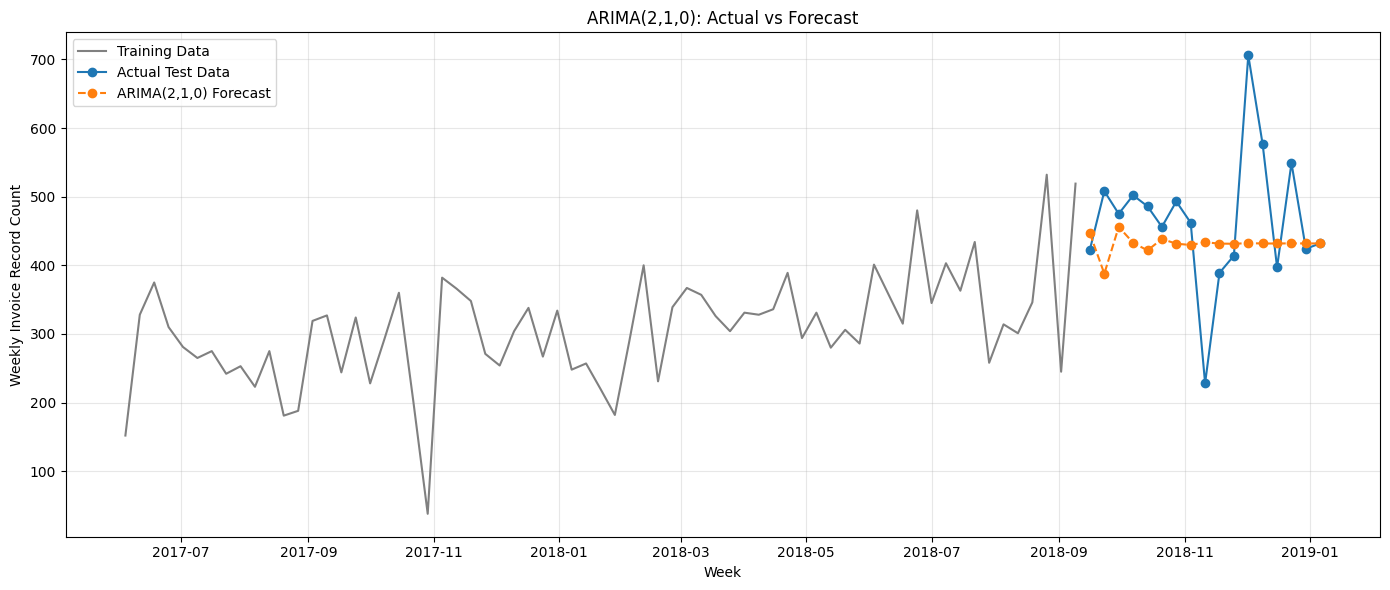

In [191]:
from statsmodels.tsa.arima.model import ARIMA
import matplotlib.pyplot as plt

# Fit best ARIMA model
best_arima_model = ARIMA(
    train_data,
    order=(2, 1, 0)
)

best_arima_fit = best_arima_model.fit()

# Forecast test period
best_arima_forecast = best_arima_fit.forecast(
    steps=len(test_data)
)

# Plot
plt.figure(figsize=(14, 6))

plt.plot(train_data.index, train_data,
         label='Training Data', color='gray')

plt.plot(test_data.index, test_data,
         label='Actual Test Data', marker='o')

plt.plot(test_data.index, best_arima_forecast,
         label='ARIMA(2,1,0) Forecast',
         marker='o', linestyle='--')

plt.title('ARIMA(2,1,0): Actual vs Forecast')
plt.xlabel('Week')
plt.ylabel('Weekly Invoice Record Count')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

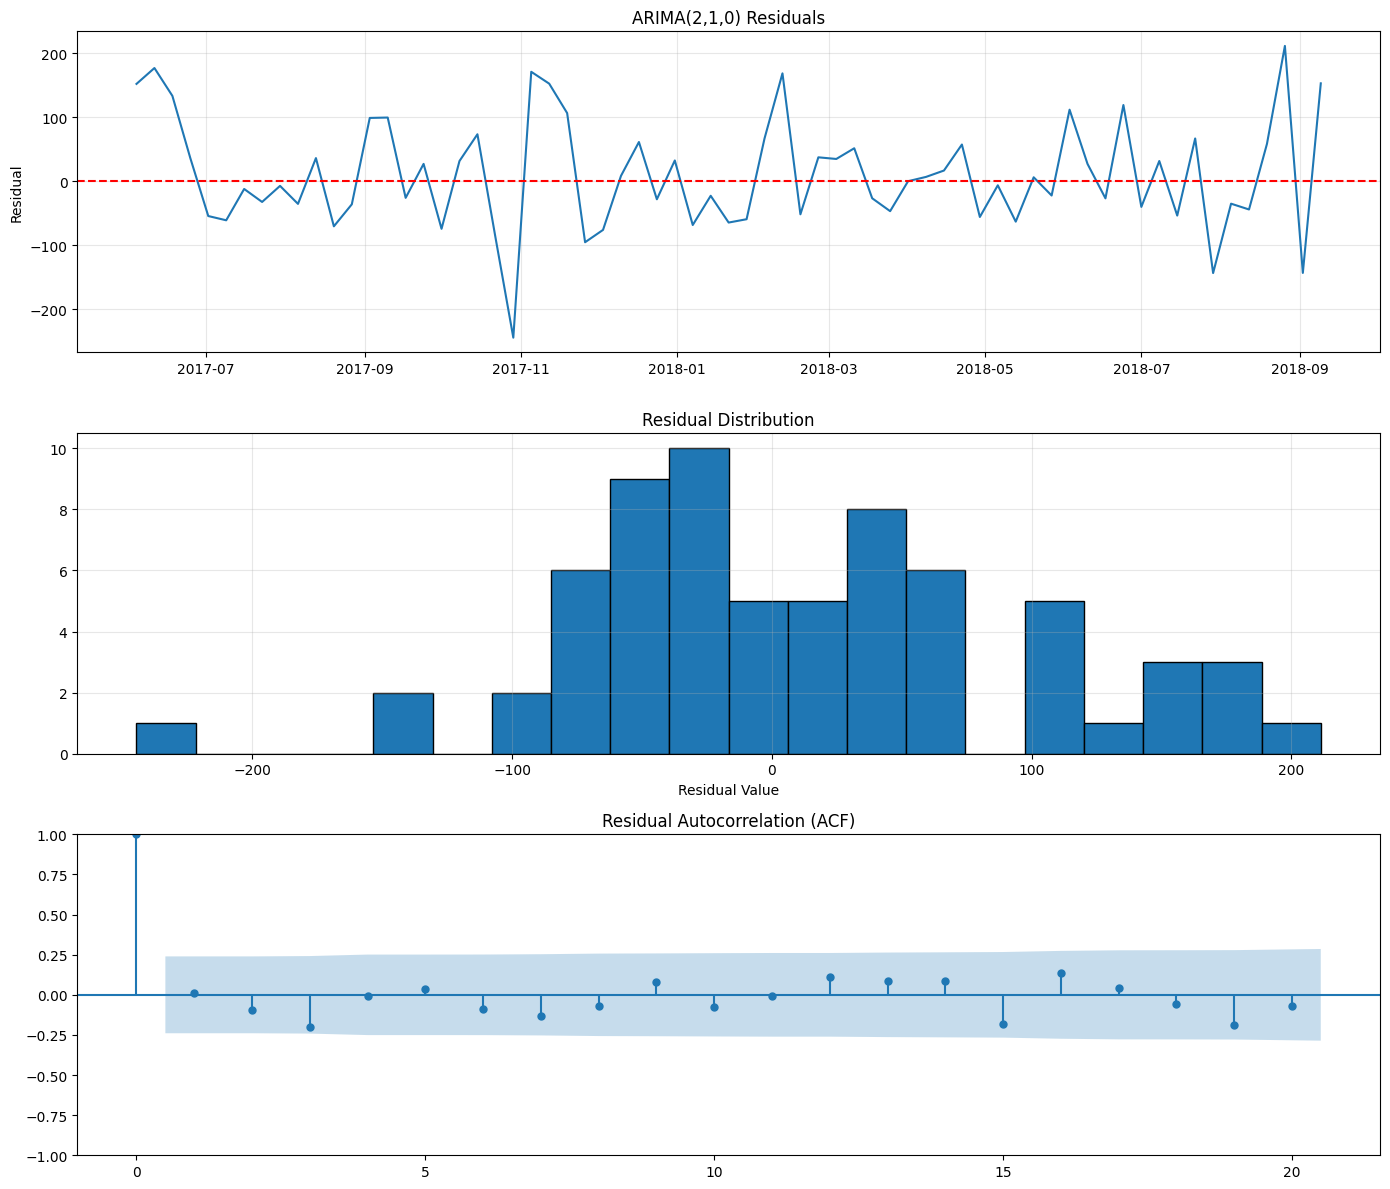

,lb_stat,lb_pvalue
10,6.945192,0.730609


In [192]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
import pandas as pd

# Extract residuals from the fitted ARIMA model
residuals = best_arima_fit.resid

fig, axes = plt.subplots(3, 1, figsize=(14, 12))

# 1. Residual plot
axes[0].plot(residuals)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('ARIMA(2,1,0) Residuals')
axes[0].set_ylabel('Residual')
axes[0].grid(alpha=0.3)

# 2. Residual distribution
axes[1].hist(residuals, bins=20, edgecolor='black')
axes[1].set_title('Residual Distribution')
axes[1].set_xlabel('Residual Value')
axes[1].grid(alpha=0.3)

# 3. Residual ACF
plot_acf(residuals, lags=20, ax=axes[2])
axes[2].set_title('Residual Autocorrelation (ACF)')

plt.tight_layout()
plt.show()

# Ljung-Box test
ljung_box_results = acorr_ljungbox(
    residuals,
    lags=[10],
    return_df=True
)

display(ljung_box_results)

In [193]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings('ignore')

# Base ARIMA order
order = (2, 1, 0)

# Seasonal period
seasonal_period = 13

# Small seasonal parameter search
seasonal_params = [
    (0, 0, 0, 13),
    (1, 0, 0, 13),
    (0, 0, 1, 13),
    (1, 0, 1, 13),
    (0, 1, 0, 13),
    (1, 1, 0, 13),
    (0, 1, 1, 13),
    (1, 1, 1, 13)
]

sarima_results = []

for seasonal_order in seasonal_params:

    try:
        model = SARIMAX(
            train_data,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        model_fit = model.fit(disp=False)

        forecast = model_fit.forecast(
            steps=len(test_data)
        )

        mae = mean_absolute_error(test_data, forecast)
        rmse = np.sqrt(mean_squared_error(test_data, forecast))
        mape = np.mean(
            np.abs((test_data - forecast) / test_data)
        ) * 100

        sarima_results.append({
            'Model': f'SARIMA{order}x{seasonal_order}',
            'Order': order,
            'Seasonal Order': seasonal_order,
            'MAE': mae,
            'RMSE': rmse,
            'MAPE': mape
        })

    except Exception as e:
        print(f"Model {seasonal_order} failed: {e}")

# Results comparison
sarima_results_df = pd.DataFrame(sarima_results)

sarima_results_df = sarima_results_df.sort_values(
    by='MAE'
).reset_index(drop=True)

display(sarima_results_df)

,Model,Order,Seasonal Order,MAE,RMSE,MAPE
0,"SARIMA(2, 1, 0)x(0, 0, 0, 13)","(2, 1, 0)","(0, 0, 0, 13)",73.417246,104.286377,16.644955
1,"SARIMA(2, 1, 0)x(1, 0, 0, 13)","(2, 1, 0)","(1, 0, 0, 13)",74.730262,105.530009,16.698349
2,"SARIMA(2, 1, 0)x(0, 0, 1, 13)","(2, 1, 0)","(0, 0, 1, 13)",77.186636,107.384762,17.206187
3,"SARIMA(2, 1, 0)x(1, 1, 0, 13)","(2, 1, 0)","(1, 1, 0, 13)",77.938762,110.451589,16.621524
4,"SARIMA(2, 1, 0)x(1, 1, 1, 13)","(2, 1, 0)","(1, 1, 1, 13)",80.439786,110.823697,17.732935
5,"SARIMA(2, 1, 0)x(1, 0, 1, 13)","(2, 1, 0)","(1, 0, 1, 13)",80.873804,111.585545,18.195302
6,"SARIMA(2, 1, 0)x(0, 1, 0, 13)","(2, 1, 0)","(0, 1, 0, 13)",85.294051,127.697677,18.576449
7,"SARIMA(2, 1, 0)x(0, 1, 1, 13)","(2, 1, 0)","(0, 1, 1, 13)",86.561399,130.649158,18.625417


In [194]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
import numpy as np
import pandas as pd
import warnings

warnings.filterwarnings('ignore')

# Full weekly record-count series
series = weekly_analysis_final['weekly_record_count']

# 5 chronological splits
tscv = TimeSeriesSplit(n_splits=5)

cv_results = []

fold = 1

for train_index, test_index in tscv.split(series):

    train_fold = series.iloc[train_index]
    test_fold = series.iloc[test_index]

    # ARIMA model
    model = ARIMA(train_fold, order=(2, 1, 0))
    model_fit = model.fit()

    arima_pred = model_fit.forecast(steps=len(test_fold))

    # Naive forecast: repeat last training observation
    naive_pred = np.repeat(train_fold.iloc[-1], len(test_fold))

    # ARIMA metrics
    arima_mae = mean_absolute_error(test_fold, arima_pred)
    arima_rmse = np.sqrt(mean_squared_error(test_fold, arima_pred))

    # Naive metrics
    naive_mae = mean_absolute_error(test_fold, naive_pred)
    naive_rmse = np.sqrt(mean_squared_error(test_fold, naive_pred))

    cv_results.append({
        'Fold': fold,
        'Train Size': len(train_fold),
        'Test Size': len(test_fold),
        'ARIMA MAE': arima_mae,
        'ARIMA RMSE': arima_rmse,
        'Naive MAE': naive_mae,
        'Naive RMSE': naive_rmse
    })

    fold += 1

# Display fold results
cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df)

print("\nAverage Cross-Validation Results:")

display(
    cv_results_df[
        ['ARIMA MAE', 'ARIMA RMSE', 'Naive MAE', 'Naive RMSE']
    ].mean().to_frame('Average Score')
)

,Fold,Train Size,Test Size,ARIMA MAE,ARIMA RMSE,Naive MAE,Naive RMSE
0,1,14,14,76.922967,95.522961,65.071429,93.646371
1,2,28,14,54.098869,62.483689,54.785714,62.086921
2,3,42,14,41.072364,52.310523,36.928571,53.607702
3,4,56,14,83.338111,94.614218,106.571429,128.258667
4,5,70,14,76.248161,105.029360,75.714286,104.677054



Average Cross-Validation Results:


,Average Score
ARIMA MAE,66.336095
ARIMA RMSE,81.992150
Naive MAE,67.814286
Naive RMSE,88.455343


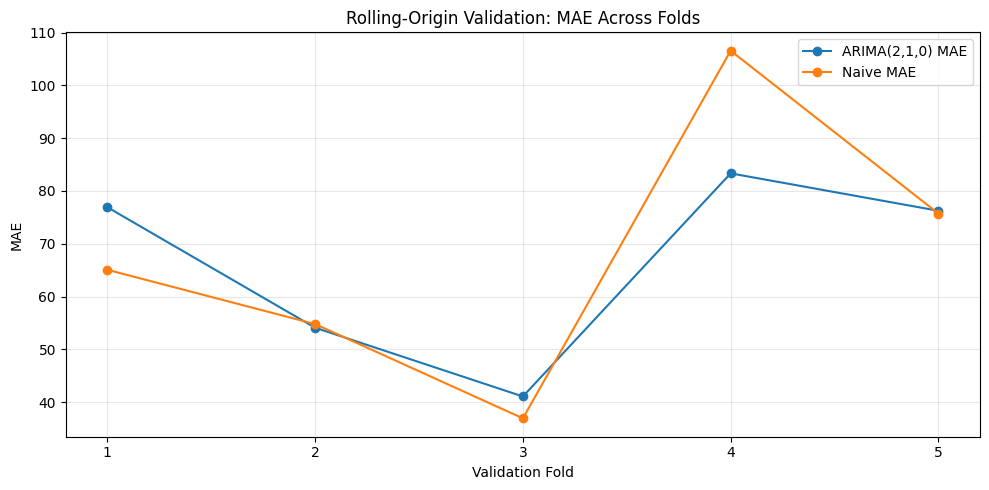

In [195]:
import matplotlib.pyplot as plt
import numpy as np

folds = cv_results_df['Fold']

plt.figure(figsize=(10, 5))

plt.plot(folds, cv_results_df['ARIMA MAE'],
         marker='o', label='ARIMA(2,1,0) MAE')

plt.plot(folds, cv_results_df['Naive MAE'],
         marker='o', label='Naive MAE')

plt.title('Rolling-Origin Validation: MAE Across Folds')
plt.xlabel('Validation Fold')
plt.ylabel('MAE')
plt.xticks(folds)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [196]:
cv_results_df['MAE_Improvement'] = (
    cv_results_df['Naive MAE'] - cv_results_df['ARIMA MAE']
)

cv_results_df['Improvement_Percentage'] = (
    cv_results_df['MAE_Improvement'] /
    cv_results_df['Naive MAE'] * 100
)

display(
    cv_results_df[
        ['Fold', 'Naive MAE', 'ARIMA MAE',
         'MAE_Improvement', 'Improvement_Percentage']
    ].round(2)
)

print("\nAverage Improvement (%):",
      round(cv_results_df['Improvement_Percentage'].mean(), 2))

,Fold,Naive MAE,ARIMA MAE,MAE_Improvement,Improvement_Percentage
0,1,65.07,76.92,-11.85,-18.21
1,2,54.79,54.10,0.69,1.25
2,3,36.93,41.07,-4.14,-11.22
3,4,106.57,83.34,23.23,21.80
4,5,75.71,76.25,-0.53,-0.71



Average Improvement (%): -1.42


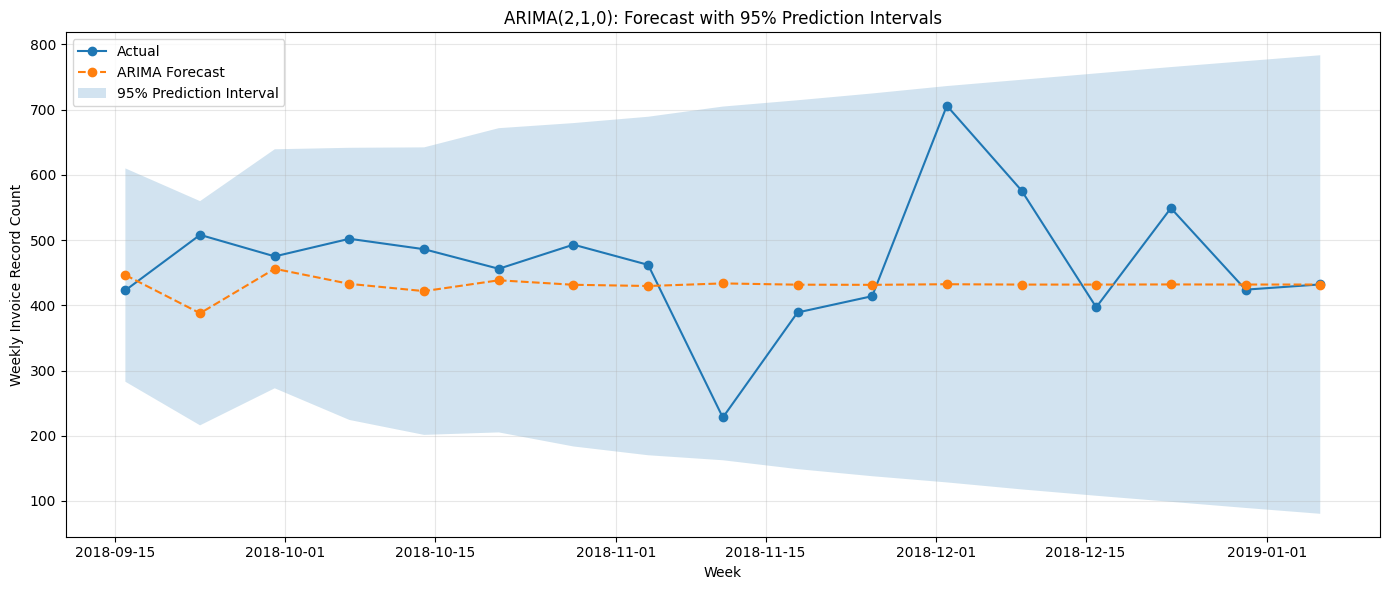

,Actual,Forecast,Lower_95%,Upper_95%
2018-09-16,423,446.35,282.81,609.89
2018-09-23,508,387.83,215.97,559.70
2018-09-30,475,455.99,272.77,639.21
2018-10-07,502,432.86,224.22,641.50
2018-10-14,486,421.73,201.33,642.13
2018-10-21,456,438.35,205.14,671.57
2018-10-28,493,431.48,183.59,679.36
2018-11-04,462,429.60,170.11,689.08
2018-11-11,228,433.57,162.44,704.70
2018-11-18,389,431.62,148.88,714.36


In [197]:
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

# Fit ARIMA(2,1,0) on training data
model = ARIMA(train_data, order=(2, 1, 0))
best_arima_fit = model.fit()

# Forecast the test period with 95% prediction intervals
forecast_result = best_arima_fit.get_forecast(
    steps=len(test_data)
)

forecast_mean = forecast_result.predicted_mean
forecast_ci = forecast_result.conf_int(alpha=0.05)

lower_bound = forecast_ci.iloc[:, 0]
upper_bound = forecast_ci.iloc[:, 1]

# Plot
plt.figure(figsize=(14, 6))

plt.plot(test_data.index, test_data,
         marker='o', label='Actual')

plt.plot(test_data.index, forecast_mean,
         marker='o', linestyle='--', label='ARIMA Forecast')

plt.fill_between(
    test_data.index,
    lower_bound,
    upper_bound,
    alpha=0.2,
    label='95% Prediction Interval'
)

plt.title('ARIMA(2,1,0): Forecast with 95% Prediction Intervals')
plt.xlabel('Week')
plt.ylabel('Weekly Invoice Record Count')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Display forecast table
forecast_table = pd.DataFrame({
    'Actual': test_data,
    'Forecast': forecast_mean,
    'Lower_95%': lower_bound,
    'Upper_95%': upper_bound
})

display(forecast_table.round(2))

In [198]:
# Check whether actual values fall inside prediction intervals
inside_interval = (
    (test_data >= lower_bound) &
    (test_data <= upper_bound)
)

coverage_count = inside_interval.sum()
total_weeks = len(test_data)
coverage_percentage = (coverage_count / total_weeks) * 100

# Average interval width
interval_width = upper_bound - lower_bound
average_width = interval_width.mean()

print("Weeks inside 95% interval:", coverage_count, "/", total_weeks)
print("Interval Coverage (%):", round(coverage_percentage, 2), "%")
print("Average Prediction Interval Width:", round(average_width, 2))

# Display individual results
coverage_table = pd.DataFrame({
    'Actual': test_data,
    'Lower Bound': lower_bound,
    'Upper Bound': upper_bound,
    'Inside Interval': inside_interval
})

display(coverage_table.round(2))

Weeks inside 95% interval: 17 / 17
Interval Coverage (%): 100.0 %
Average Prediction Interval Width: 529.93


,Actual,Lower Bound,Upper Bound,Inside Interval
2018-09-16,423,282.81,609.89,True
2018-09-23,508,215.97,559.70,True
2018-09-30,475,272.77,639.21,True
2018-10-07,502,224.22,641.50,True
2018-10-14,486,201.33,642.13,True
2018-10-21,456,205.14,671.57,True
2018-10-28,493,183.59,679.36,True
2018-11-04,462,170.11,689.08,True
2018-11-11,228,162.44,704.70,True
2018-11-18,389,148.88,714.36,True


Mean Forecast Error (Bias): 34.57
Median Forecast Error: 19.01
Underforecast Weeks: 11
Overforecast Weeks: 6
Exact Forecast Weeks: 0


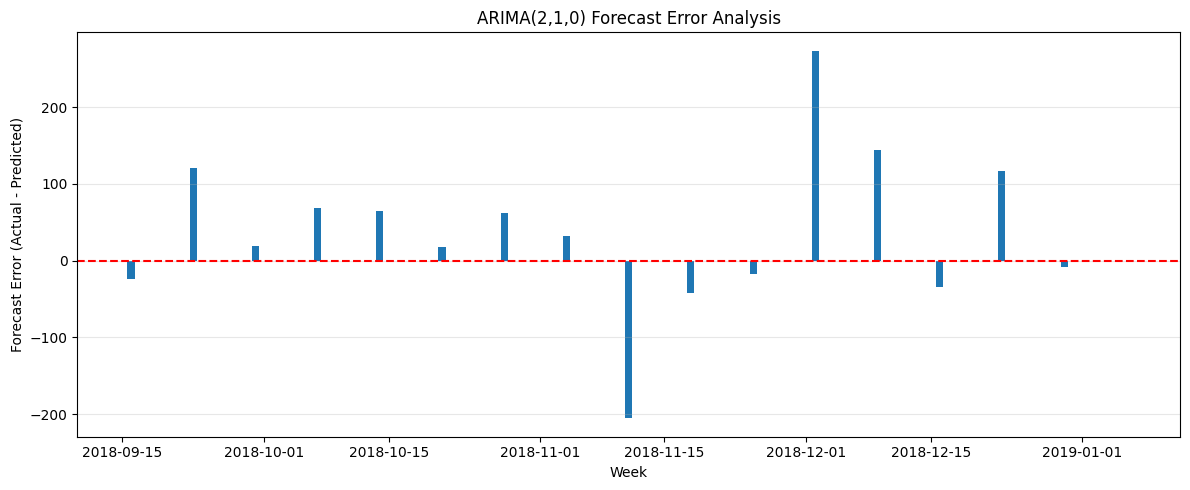

In [199]:
# Calculate forecast errors
forecast_errors = test_data - forecast_mean

# Bias metrics
mean_error = forecast_errors.mean()
median_error = forecast_errors.median()

underforecast_weeks = (forecast_errors > 0).sum()
overforecast_weeks = (forecast_errors < 0).sum()
exact_weeks = (forecast_errors == 0).sum()

print("Mean Forecast Error (Bias):", round(mean_error, 2))
print("Median Forecast Error:", round(median_error, 2))
print("Underforecast Weeks:", underforecast_weeks)
print("Overforecast Weeks:", overforecast_weeks)
print("Exact Forecast Weeks:", exact_weeks)

# Plot forecast errors
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.bar(forecast_errors.index, forecast_errors)
plt.axhline(0, color='red', linestyle='--')

plt.title('ARIMA(2,1,0) Forecast Error Analysis')
plt.xlabel('Week')
plt.ylabel('Forecast Error (Actual - Predicted)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [200]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate bias using TRAINING residuals only
training_residuals = best_arima_fit.resid
training_bias = training_residuals.mean()

# Original forecast
original_forecast = forecast_mean

# Bias-corrected forecast
corrected_forecast = original_forecast + training_bias

# Evaluate both forecasts
original_mae = mean_absolute_error(test_data, original_forecast)
corrected_mae = mean_absolute_error(test_data, corrected_forecast)

original_rmse = np.sqrt(mean_squared_error(test_data, original_forecast))
corrected_rmse = np.sqrt(mean_squared_error(test_data, corrected_forecast))

original_mape = np.mean(
    np.abs((test_data - original_forecast) / test_data)
) * 100

corrected_mape = np.mean(
    np.abs((test_data - corrected_forecast) / test_data)
) * 100

print("Training Bias:", round(training_bias, 2))

comparison = pd.DataFrame({
    'Metric': ['MAE', 'RMSE', 'MAPE'],
    'Original ARIMA': [original_mae, original_rmse, original_mape],
    'Bias-Corrected ARIMA': [
        corrected_mae, corrected_rmse, corrected_mape
    ]
})

display(comparison.round(2))

Training Bias: 10.44


,Metric,Original ARIMA,Bias-Corrected ARIMA
0,MAE,73.57,71.72
1,RMSE,104.16,101.18
2,MAPE,16.74,16.70


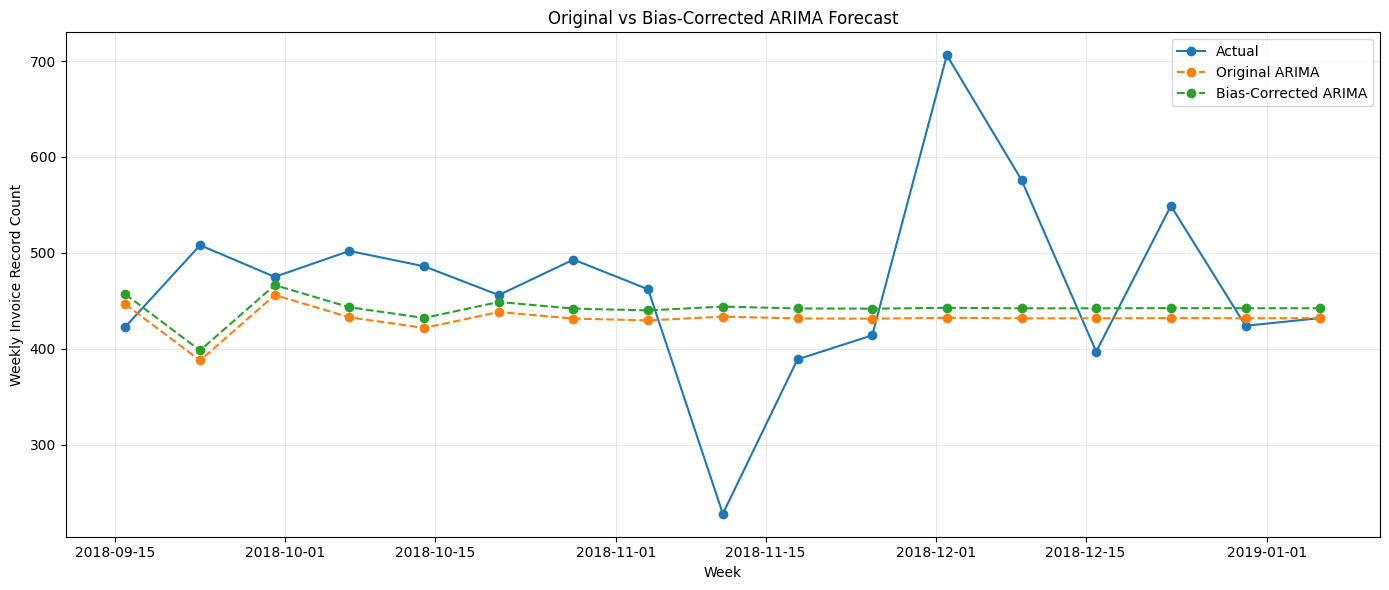

In [201]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(test_data.index, test_data,
         marker='o', label='Actual')

plt.plot(test_data.index, original_forecast,
         marker='o', linestyle='--',
         label='Original ARIMA')

plt.plot(test_data.index, corrected_forecast,
         marker='o', linestyle='--',
         label='Bias-Corrected ARIMA')

plt.title('Original vs Bias-Corrected ARIMA Forecast')
plt.xlabel('Week')
plt.ylabel('Weekly Invoice Record Count')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Average Absolute Error by Forecast Horizon:


,Average_MAE
Period,
Weeks 1-5,59.19
Weeks 6-10,71.95
Weeks 11-17,85.01


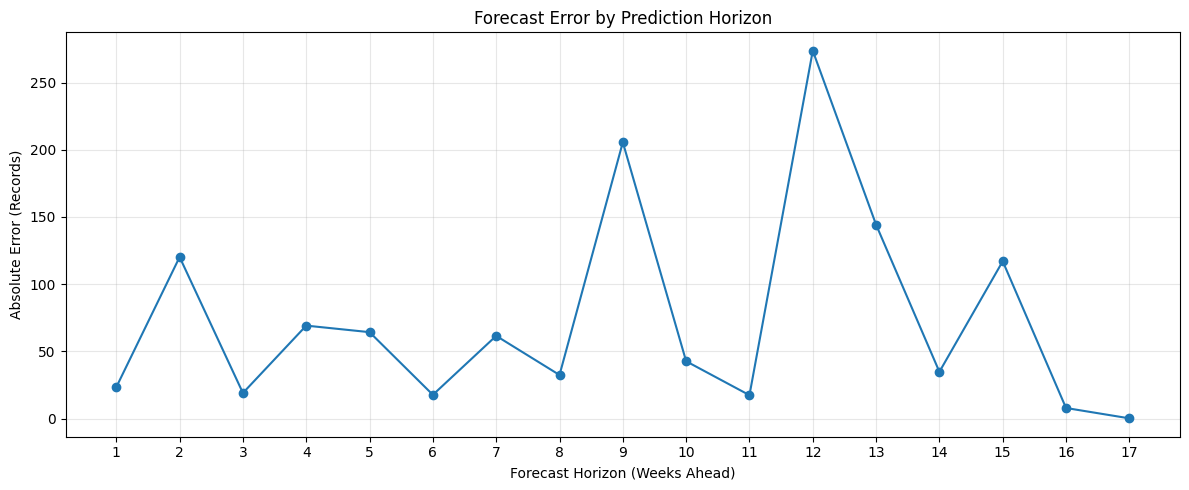

In [202]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Absolute error for each forecast horizon
horizon_analysis = pd.DataFrame({
    'Forecast_Week': range(1, len(test_data) + 1),
    'Actual': test_data.values,
    'Forecast': original_forecast.values
})

horizon_analysis['Absolute_Error'] = np.abs(
    horizon_analysis['Actual'] - horizon_analysis['Forecast']
)

# Group forecast horizon into periods
horizon_analysis['Period'] = pd.cut(
    horizon_analysis['Forecast_Week'],
    bins=[0, 5, 10, 17],
    labels=['Weeks 1-5', 'Weeks 6-10', 'Weeks 11-17']
)

# Average error by forecast period
horizon_summary = horizon_analysis.groupby(
    'Period', observed=False
)['Absolute_Error'].mean()

print("Average Absolute Error by Forecast Horizon:")
display(horizon_summary.to_frame('Average_MAE').round(2))

# Plot individual errors
plt.figure(figsize=(12, 5))

plt.plot(
    horizon_analysis['Forecast_Week'],
    horizon_analysis['Absolute_Error'],
    marker='o'
)

plt.title('Forecast Error by Prediction Horizon')
plt.xlabel('Forecast Horizon (Weeks Ahead)')
plt.ylabel('Absolute Error (Records)')
plt.xticks(horizon_analysis['Forecast_Week'])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [203]:
horizon_analysis['Squared_Error'] = (
    (horizon_analysis['Actual'] - horizon_analysis['Forecast']) ** 2
)

horizon_analysis['Percentage_Error'] = (
    np.abs(
        (horizon_analysis['Actual'] - horizon_analysis['Forecast'])
        / horizon_analysis['Actual']
    ) * 100
)

horizon_metrics = horizon_analysis.groupby(
    'Period', observed=False
).agg(
    MAE=('Absolute_Error', 'mean'),
    RMSE=('Squared_Error', lambda x: np.sqrt(x.mean())),
    MAPE=('Percentage_Error', 'mean')
)

display(horizon_metrics.round(2))

,MAE,RMSE,MAPE
Period,,,
Weeks 1-5,59.19,69.65,12.03
Weeks 6-10,71.95,99.22,24.90
Weeks 11-17,85.01,125.91,14.28


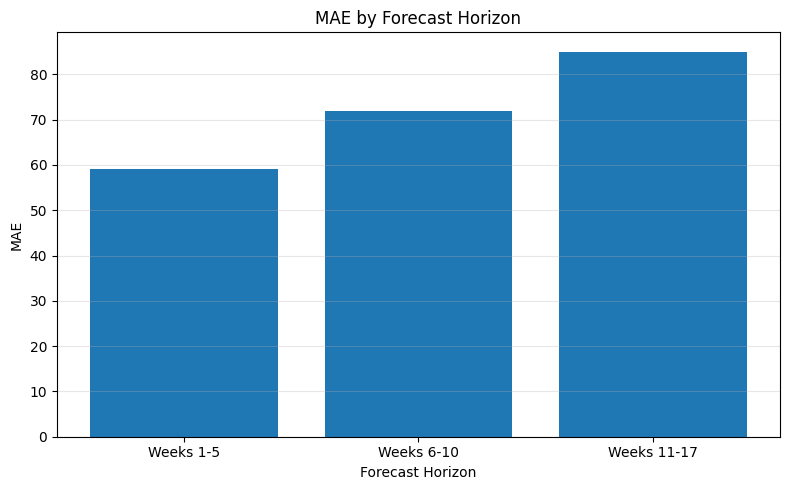

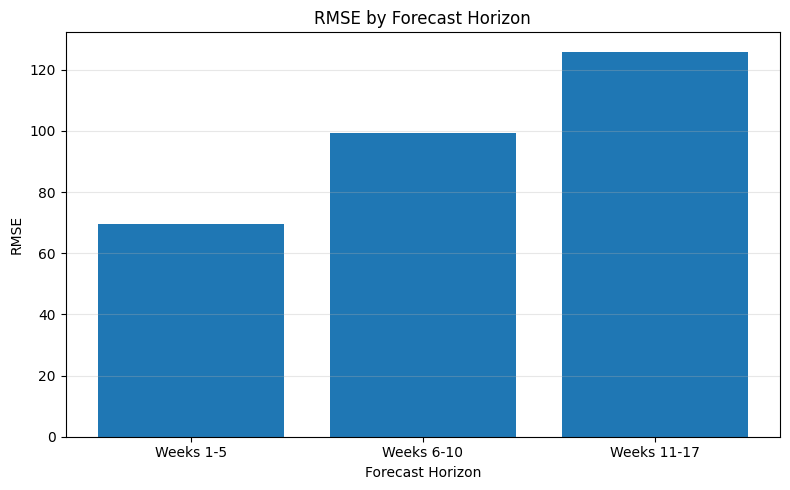

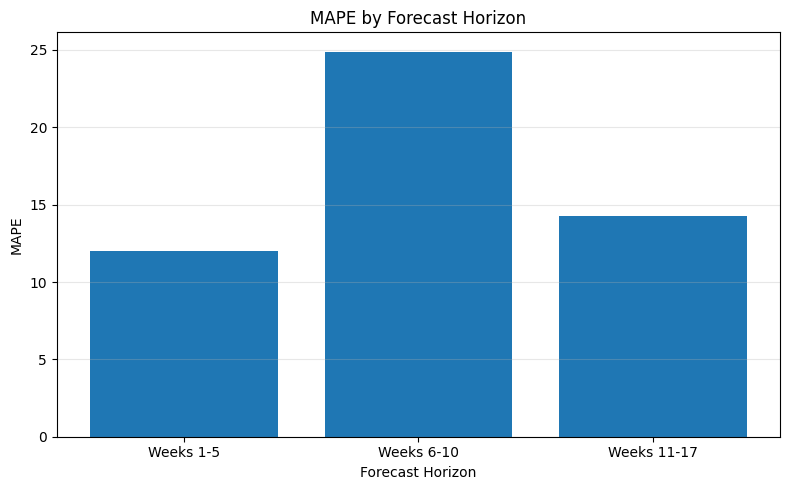

In [205]:
import matplotlib.pyplot as plt

metrics = ['MAE', 'RMSE', 'MAPE']
horizons = horizon_metrics.index.astype(str)

for metric in metrics:
    plt.figure(figsize=(8, 5))

    plt.bar(horizons, horizon_metrics[metric])

    plt.title(f'{metric} by Forecast Horizon')
    plt.xlabel('Forecast Horizon')
    plt.ylabel(metric)
    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

In [206]:
import pandas as pd

final_model_comparison = pd.DataFrame({
    'Model': [
        'Naive',
        'Fixed 4-Week Moving Average',
        'Rolling 4-Week Moving Average',
        'Seasonal Naive (13-week)',
        'ARIMA (2,1,0)',
        'Bias-Corrected ARIMA (2,1,0)',
        'SARIMA (2,1,0) x (1,0,0,13)',
        'SARIMA (2,1,0) x (0,0,1,13)',
        'SARIMA (2,1,0) x (1,1,0,13)'
    ],
    'MAE': [
        85.352941,
        80.970588,
        79.058824,
        112.000000,
        73.574898,
        71.720000,
        74.730262,
        77.186636,
        77.938762
    ],
    'RMSE': [
        109.476562,
        110.593120,
        118.947650,
        150.944088,
        104.164345,
        101.180000,
        105.530009,
        107.384762,
        110.451589
    ],
    'MAPE': [
        22.191937,
        17.714230,
        18.871740,
        23.135525,
        16.742132,
        16.700000,
        16.698349,
        17.206187,
        16.621524
    ]
})

final_model_comparison = final_model_comparison.sort_values(
    by='MAE'
).reset_index(drop=True)

display(final_model_comparison.round(2))

,Model,MAE,RMSE,MAPE
0,"Bias-Corrected ARIMA (2,1,0)",71.72,101.18,16.70
1,"ARIMA (2,1,0)",73.57,104.16,16.74
2,"SARIMA (2,1,0) x (1,0,0,13)",74.73,105.53,16.70
3,"SARIMA (2,1,0) x (0,0,1,13)",77.19,107.38,17.21
4,"SARIMA (2,1,0) x (1,1,0,13)",77.94,110.45,16.62
5,Rolling 4-Week Moving Average,79.06,118.95,18.87
6,Fixed 4-Week Moving Average,80.97,110.59,17.71
7,Naive,85.35,109.48,22.19
8,Seasonal Naive (13-week),112.00,150.94,23.14


In [207]:
import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA

# 1. Use the complete weekly record-count series
final_series = weekly_analysis_final['weekly_record_count'].copy()

# 2. Fit the selected ARIMA model on all available data
final_model = ARIMA(final_series, order=(2, 1, 0))
final_model_fit = final_model.fit()

# 3. Forecast the next 4 weeks
forecast_steps = 4

future_forecast = final_model_fit.get_forecast(steps=forecast_steps)
forecast_values = future_forecast.predicted_mean
forecast_intervals = future_forecast.conf_int(alpha=0.05)

# 4. Create future weekly dates
last_date = final_series.index[-1]
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=7),
    periods=forecast_steps,
    freq='W-SUN'
)

# 5. Create final forecast table
final_forecast_table = pd.DataFrame({
    'Forecast_Week': future_dates,
    'Predicted_Records': forecast_values.values,
    'Lower_95%': forecast_intervals.iloc[:, 0].values,
    'Upper_95%': forecast_intervals.iloc[:, 1].values
})

final_forecast_table['Predicted_Records'] = (
    final_forecast_table['Predicted_Records'].round().astype(int)
)

final_forecast_table = final_forecast_table.round(2)

display(final_forecast_table)

,Forecast_Week,Predicted_Records,Lower_95%,Upper_95%
0,2019-01-13,463,281.76,643.65
1,2019-01-20,443,246.54,638.48
2,2019-01-27,446,231.70,659.53
3,2019-02-03,450,209.18,689.85


In [208]:
import pandas as pd
import numpy as np
from statsmodels.tsa.arima.model import ARIMA

# 1. Use the complete weekly record-count series
final_series = weekly_analysis_final['weekly_record_count'].copy()

# 2. Fit the selected ARIMA model on all available data
final_model = ARIMA(final_series, order=(2, 1, 0))
final_model_fit = final_model.fit()

# 3. Forecast the next 4 weeks
forecast_steps = 4

future_forecast = final_model_fit.get_forecast(steps=forecast_steps)
forecast_values = future_forecast.predicted_mean
forecast_intervals = future_forecast.conf_int(alpha=0.05)

# 4. Create future weekly dates
last_date = final_series.index[-1]
future_dates = pd.date_range(
    start=last_date + pd.Timedelta(days=7),
    periods=forecast_steps,
    freq='W-SUN'
)

# 5. Create final forecast table
final_forecast_table = pd.DataFrame({
    'Forecast_Week': future_dates,
    'Predicted_Records': forecast_values.values,
    'Lower_95%': forecast_intervals.iloc[:, 0].values,
    'Upper_95%': forecast_intervals.iloc[:, 1].values
})

final_forecast_table['Predicted_Records'] = (
    final_forecast_table['Predicted_Records'].round().astype(int)
)

final_forecast_table = final_forecast_table.round(2)

display(final_forecast_table)

,Forecast_Week,Predicted_Records,Lower_95%,Upper_95%
0,2019-01-13,463,281.76,643.65
1,2019-01-20,443,246.54,638.48
2,2019-01-27,446,231.70,659.53
3,2019-02-03,450,209.18,689.85


**The ARIMA(2,1,0) model forecasts weekly invoice-record volume of approximately 443–463 records over the next four weeks. Although the point forecasts remain relatively stable, the 95% prediction intervals are wide, indicating substantial uncertainty. Therefore, the model is more useful for estimating short-term operational activity trends than for making precise inventory purchasing decisions**


## 1. Forecast Interpretation

The ARIMA(2,1,0) model was used to forecast weekly invoice-record volume for the next four weeks.

| Forecast Week | Predicted Records | Lower 95% | Upper 95% |
|---|---:|---:|---:|
| 2019-01-13 | 463 | 281.76 | 643.65 |
| 2019-01-20 | 443 | 246.54 | 638.48 |
| 2019-01-27 | 446 | 231.70 | 659.53 |
| 2019-02-03 | 450 | 209.18 | 689.85 |

### Key Observations

- The predicted weekly invoice-record volume remains relatively stable, ranging from 443 to 463 records.
- No clear upward or downward trend is observed in the four forecasted values.
- The predictions remain close to 450 records per week.
- The 95% prediction intervals are wide, indicating considerable uncertainty in future actual values.
- Prediction intervals widen as the forecast horizon increases, reflecting increasing forecast uncertainty.

### Interpretation

The model expects weekly invoice-record volume to remain relatively stable over the next four weeks, at approximately 450 records per week. However, the wide prediction intervals suggest that actual weekly volumes may vary considerably from the predicted values. Therefore, the forecasts are more useful for understanding short-term operational activity than for making precise long-term decisions.



## 2. Model Selection Justification

Multiple forecasting approaches were evaluated, including Naive Forecasting, Moving Average, Seasonal Naive, ARIMA, and SARIMA models.

### Selected Model: ARIMA(2,1,0)

ARIMA(2,1,0) was selected as the primary forecasting model based on its test-set performance, rolling-origin cross-validation results, and residual diagnostics.

### Reasons for Selection

- **Test Performance:** The model achieved a Mean Absolute Error (MAE) of 73.57, Root Mean Squared Error (RMSE) of 104.16, and Mean Absolute Percentage Error (MAPE) of 16.74%.
- **Stationarity:** The original weekly series was non-stationary. First differencing helped achieve stationarity, supporting the use of an ARIMA model with differencing order d=1.
- **Cross-Validation:** The model achieved an average CV MAE of 66.34 and CV RMSE of 81.99, modestly outperforming the Naive model.
- **Residual Diagnostics:** The Ljung-Box test at lag 10 returned a p-value of 0.731, indicating no significant residual autocorrelation was detected at the tested lag.
- **Seasonality:** Seasonal models did not provide sufficient consistent improvement to justify introducing seasonal complexity, given the limited historical data.

### Model Selection Conclusion

ARIMA(2,1,0) was selected because it provided competitive forecasting performance, better average rolling-origin cross-validation performance than the Naive baseline, and satisfactory residual diagnostics. However, its performance improvement was modest and not consistent across every cross-validation fold.



## 3. Final Project Conclusion

The NewX Services Spare Parts Inventory Forecasting project focused on analyzing historical service invoice records and developing a time-series forecasting model to estimate future weekly operational activity.

The project involved data inspection, data quality assessment, exploratory data analysis, date-based aggregation, trend analysis, stationarity testing, autocorrelation analysis, baseline forecasting, ARIMA model development, SARIMA comparison, time-series cross-validation, residual diagnostics, and forecast uncertainty analysis.

The weekly invoice-record series demonstrated a significant increasing historical trend and was non-stationary in its original form. First differencing improved stationarity, supporting the application of ARIMA-based forecasting techniques.

Among the evaluated approaches, ARIMA(2,1,0) was selected as the primary model. It achieved a test MAE of 73.57, RMSE of 104.16, and MAPE of 16.74%. Rolling-origin cross-validation showed that the model modestly outperformed the Naive baseline on average, although performance varied across folds.

The final four-week forecast suggests relatively stable weekly invoice-record volume of approximately 443–463 records. However, the wide prediction intervals indicate considerable uncertainty in future operational activity.

Overall, the project demonstrates how time-series analysis can support operational planning and activity forecasting. Further improvements would require richer operational data, especially actual spare-part consumption, stock levels, purchasing history, supplier lead times, and inventory movement information, to develop a more accurate and actionable inventory-demand forecasting system**.


## 4. Limitations

### Data Limitations

- **No actual inventory quantities:** The dataset does not contain stock-on-hand, stock-out records, or quantities consumed for individual spare parts.
- **Proxy target variable:** The forecasting target is weekly invoice-record volume, not actual spare-part demand.
- **Limited historical period:** Approximately 84 weekly observations were available after aggregation.
- **Missing descriptions:** A small number of records have missing invoice-line descriptions.
- **Description inconsistencies:** Spare-part descriptions contain spelling variations, inconsistent formatting, and naming differences.
- **Duplicate records:** Duplicate transactions were identified and require validation before removal.
- **Limited operational information:** Supplier lead times, purchase orders, replenishment dates, and inventory movements were unavailable.

### Model Limitations

- The time series contains a relatively small number of weekly observations.
- Forecast prediction intervals are wide, indicating substantial uncertainty.
- Model performance varies across cross-validation folds.
- Seasonal patterns could not be established with sufficient confidence.
- The model cannot predict unexpected business events or sudden changes in service activity.
- Forecast reliability decreases as the prediction horizon increases.
- Bias-corrected ARIMA showed slightly better test-set metrics, but the improvement was not yet validated through rolling-origin cross-validation.

### Business Limitations

The current model cannot directly determine:

- The quantity of a specific spare part to order.
- Optimal reorder points.
- Safety-stock requirements.
- Stock-out probability for individual parts.
- Supplier purchasing requirements.
- Actual inventory holding or shortage costs.

These decisions require actual part-level demand and inventory information.



## 5. Project Summary – Portfolio

### NewX Services – Spare Parts Inventory Forecasting

**Project Type:** Time-Series Forecasting & Data Analytics  
**Domain:** Automotive Service Operations

### Project Overview

Analyzed historical service invoice records from NewX Services to identify operational patterns and forecast future weekly invoice-record volume using statistical time-series forecasting techniques.

### Objectives

- Analyze historical invoice records and identify trends.
- Perform data quality assessment and exploratory data analysis.
- Aggregate transaction data into a weekly time series.
- Evaluate stationarity and autocorrelation.
- Develop and compare baseline and statistical forecasting models.
- Evaluate models using MAE, RMSE, MAPE, and rolling-origin cross-validation.
- Generate future forecasts with 95% prediction intervals.

### Methodology

Data Inspection → Data Quality Analysis → EDA → Weekly Aggregation → Stationarity Testing → Baseline Models → ARIMA/SARIMA Modeling → Cross-Validation → Residual Diagnostics → Future Forecasting

### Final Model

**ARIMA(2,1,0)**

| Metric | Test Performance |
|---|---:|
| MAE | 73.57 |
| RMSE | 104.16 |
| MAPE | 16.74% |

### Key Findings

- Historical weekly invoice-record volume demonstrated an increasing trend.
- First differencing helped achieve stationarity.
- ARIMA(2,1,0) modestly outperformed the Naive baseline on average during rolling-origin cross-validation.
- The next four weeks were forecasted at approximately 443–463 invoice records per week.
- Wide prediction intervals indicated uncertainty in future operational activity.

### Business Value

The forecasting approach provides a preliminary estimate of future service activity that may support operational workload planning and resource allocation. It also establishes a foundation for future development of a more complete spare-parts demand forecasting system.

### Limitations

The forecasting target represents weekly invoice-record volume rather than actual spare-parts demand. Inventory quantities, stock movements, supplier lead times, and purchasing records were unavailable.

### Tools & Technologies

Python, Pandas, NumPy, Matplotlib, Statsmodels, Scikit-learn, Time-Series Analysis, ARIMA, SARIMA

### Future Scope

- Standardize and categorize spare-part descriptions.
- Develop part-level demand forecasting.
- Forecast individual spare parts.
- Integrate inventory and procurement data.
- Calculate reorder points and safety stock using actual demand and lead-time data.
- Develop an interactive forecasting dashboard.
